In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Working folder banano hocche Drive-e, jate dataset o output shobkichu save thake
import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/dataset', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/outputs', exist_ok=True)
print("Project dir ready:", PROJECT_DIR)

Mounted at /content/drive
Project dir ready: /content/drive/MyDrive/OCT_C8_Project


In [ ]:
import os

# --- Kaggle new-style API token setup ---
os.makedirs('/root/.kaggle', exist_ok=True)

# Ekhane tomar NIJER (notun generate kora) token ta boso:
KAGGLE_TOKEN = "KGAT_fad969bdceb240ec5b6c7465b4bec391"   # <-- eikhane token ta paste korbe

with open('/root/.kaggle/access_token', 'w') as f:
    f.write(KAGGLE_TOKEN)

os.chmod('/root/.kaggle/access_token', 0o600)

# Environment variable hisebeo set kore rakha bhalo (double safety)
os.environ['KAGGLE_API_TOKEN'] = KAGGLE_TOKEN

# --- Install kaggle package ---
!pip install -q kaggle

# --- Download dataset directly into Drive folder ---
!kaggle datasets download -d obulisainaren/retinal-oct-c8 -p "{PROJECT_DIR}/dataset" --unzip

print("Download complete. Files:")
!ls "{PROJECT_DIR}/dataset"

^C
Download complete. Files:
README.md  RetinalOCT_Dataset


In [ ]:
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

In [ ]:
dataset_root = f'{PROJECT_DIR}/dataset'

for split in ['train', 'val', 'test']:
    split_path = os.path.join(dataset_root, split)
    if os.path.exists(split_path):
        classes = os.listdir(split_path)
        print(f"\n{split.upper()} — {len(classes)} classes")
        for c in classes:
            n = len(os.listdir(os.path.join(split_path, c)))
            print(f"  {c}: {n} images")

In [ ]:
import cv2
import numpy as np

IMG_SIZE = (224, 224)

def load_and_preprocess(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)
    img = img.astype(np.float32) / 255.0
    return img

In [ ]:
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

# Confirm করো ঠিক আছে কিনা
import os
print(os.listdir(dataset_root))  # ['test', 'train', 'val'] আসা উচিত

['test', 'train', 'val']


In [ ]:
!pip install -q imagehash

import imagehash
from PIL import Image
import pandas as pd
from itertools import combinations

def compute_hashes(split_path):
    records = []
    for class_name in os.listdir(split_path):
        class_dir = os.path.join(split_path, class_name)
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            try:
                h = imagehash.phash(Image.open(fpath))
                records.append({'path': fpath, 'class': class_name, 'hash': h})
            except Exception as e:
                print("Skip:", fpath, e)
    return records

train_hashes = compute_hashes(os.path.join(dataset_root, 'train'))
val_hashes   = compute_hashes(os.path.join(dataset_root, 'val'))
test_hashes  = compute_hashes(os.path.join(dataset_root, 'test'))

print(f"Train: {len(train_hashes)}, Val: {len(val_hashes)}, Test: {len(test_hashes)}")

# --- Cross-split near-duplicate check ---
HASH_THRESHOLD = 5  # hamming distance; kom hole strict match, beshi hole loose

def find_leaks(set_a, set_b, name_a, name_b, threshold=HASH_THRESHOLD):
    leaks = []
    for a in set_a:
        for b in set_b:
            dist = a['hash'] - b['hash']
            if dist <= threshold:
                leaks.append({
                    f'{name_a}_path': a['path'], f'{name_a}_class': a['class'],
                    f'{name_b}_path': b['path'], f'{name_b}_class': b['class'],
                    'hamming_distance': dist
                })
    return leaks

leaks_train_val  = find_leaks(train_hashes, val_hashes, 'train', 'val')
leaks_train_test = find_leaks(train_hashes, test_hashes, 'train', 'test')
leaks_val_test   = find_leaks(val_hashes, test_hashes, 'val', 'test')

print(f"Train-Val leaks: {len(leaks_train_val)}")
print(f"Train-Test leaks: {len(leaks_train_test)}")
print(f"Val-Test leaks: {len(leaks_val_test)}")

# --- Save reports to Drive ---
pd.DataFrame(leaks_train_val).to_csv(f'{PROJECT_DIR}/outputs/leaks_train_val.csv', index=False)
pd.DataFrame(leaks_train_test).to_csv(f'{PROJECT_DIR}/outputs/leaks_train_test.csv', index=False)
pd.DataFrame(leaks_val_test).to_csv(f'{PROJECT_DIR}/outputs/leaks_val_test.csv', index=False)

print("Reports saved to Drive outputs folder.")

Train: 18400, Val: 2800, Test: 2800
Train-Val leaks: 240
Train-Test leaks: 210
Val-Test leaks: 16
Reports saved to Drive outputs folder.


In [ ]:
import os

dataset_root = f'{PROJECT_DIR}/dataset'

# Top-level dekhi
print("Top level:", os.listdir(dataset_root))

# RetinalOCT_Dataset er bhitore ki ache dekhi
inner_path = os.path.join(dataset_root, 'RetinalOCT_Dataset')
if os.path.exists(inner_path):
    print("\nInside RetinalOCT_Dataset:", os.listdir(inner_path))

Top level: ['README.md', 'RetinalOCT_Dataset']

Inside RetinalOCT_Dataset: ['RetinalOCT_Dataset']


In [ ]:
inner_path2 = os.path.join(dataset_root, 'RetinalOCT_Dataset', 'RetinalOCT_Dataset')
print("Inside second RetinalOCT_Dataset:", os.listdir(inner_path2))


Inside second RetinalOCT_Dataset: ['test', 'train', 'val']


In [ ]:
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

In [ ]:
for split in ['train', 'val', 'test']:
    split_path = os.path.join(dataset_root, split)
    if os.path.exists(split_path):
        classes = os.listdir(split_path)
        print(f"\n{split.upper()} — {len(classes)} classes")
        for c in classes:
            n = len(os.listdir(os.path.join(split_path, c)))
            print(f"  {c}: {n} images")


TRAIN — 8 classes
  AMD: 2300 images
  CNV: 2300 images
  CSR: 2300 images
  DME: 2300 images
  DR: 2300 images
  DRUSEN: 2300 images
  MH: 2300 images
  NORMAL: 2300 images

VAL — 8 classes
  AMD: 350 images
  CNV: 350 images
  CSR: 350 images
  DME: 350 images
  DR: 350 images
  DRUSEN: 350 images
  MH: 350 images
  NORMAL: 350 images

TEST — 8 classes
  AMD: 350 images
  CNV: 350 images
  CSR: 350 images
  DME: 350 images
  DR: 350 images
  DRUSEN: 350 images
  MH: 350 images
  NORMAL: 350 images


In [ ]:
import imagehash
from PIL import Image
import pandas as pd
import numpy as np
import os

def popcount64(x):
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0f0f0f0f0f0f0f0f)
    return (x * np.uint64(0x0101010101010101)) >> np.uint64(56)

def compute_hashes_by_class(split_path):
    """class_name -> (list of paths, numpy uint64 array of phash-as-int)"""
    data = {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join(split_path, class_name)
        paths, hashes = [], []
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            try:
                h = imagehash.phash(Image.open(fpath))
                paths.append(fpath)
                hashes.append(int(str(h), 16))
            except Exception as e:
                print("Skip:", fpath, e)
        data[class_name] = (paths, np.array(hashes, dtype=np.uint64))
        print(f"  {class_name}: {len(paths)} hashed")
    return data

print("Hashing TRAIN...")
train_data = compute_hashes_by_class(os.path.join(dataset_root, 'train'))
print("Hashing VAL...")
val_data = compute_hashes_by_class(os.path.join(dataset_root, 'val'))
print("Hashing TEST...")
test_data = compute_hashes_by_class(os.path.join(dataset_root, 'test'))
print("All hashing done.")

Hashing TRAIN...
  AMD: 2300 hashed
  CNV: 2300 hashed
  CSR: 2300 hashed
  DME: 2300 hashed
  DR: 2300 hashed
  DRUSEN: 2300 hashed
  MH: 2300 hashed
  NORMAL: 2300 hashed
Hashing VAL...
  AMD: 350 hashed
  CNV: 350 hashed
  CSR: 350 hashed
  DME: 350 hashed
  DR: 350 hashed
  DRUSEN: 350 hashed
  MH: 350 hashed
  NORMAL: 350 hashed
Hashing TEST...
  AMD: 350 hashed
  CNV: 350 hashed
  CSR: 350 hashed
  DME: 350 hashed
  DR: 350 hashed
  DRUSEN: 350 hashed
  MH: 350 hashed
  NORMAL: 350 hashed
All hashing done.


In [ ]:
HASH_THRESHOLD = 5  # hamming distance; komale strict, barale loose match

def find_leaks_vectorized(data_a, data_b, name_a, name_b, threshold=HASH_THRESHOLD):
    leaks = []
    classes = sorted(set(data_a.keys()) & set(data_b.keys()))
    for cls in classes:
        paths_a, hashes_a = data_a[cls]
        paths_b, hashes_b = data_b[cls]
        if len(hashes_a) == 0 or len(hashes_b) == 0:
            continue
        xor_matrix = hashes_a[:, None] ^ hashes_b[None, :]
        dist_matrix = popcount64(xor_matrix)
        idx_a, idx_b = np.where(dist_matrix <= threshold)
        for i, j in zip(idx_a, idx_b):
            leaks.append({
                f'{name_a}_path': paths_a[i],
                f'{name_b}_path': paths_b[j],
                'class': cls,
                'hamming_distance': int(dist_matrix[i, j])
            })
    return leaks

print("Checking Train-Val...")
leaks_train_val  = find_leaks_vectorized(train_data, val_data, 'train', 'val')
print("Checking Train-Test...")
leaks_train_test = find_leaks_vectorized(train_data, test_data, 'train', 'test')
print("Checking Val-Test...")
leaks_val_test   = find_leaks_vectorized(val_data, test_data, 'val', 'test')

print(f"\nTrain-Val leaks: {len(leaks_train_val)}")
print(f"Train-Test leaks: {len(leaks_train_test)}")
print(f"Val-Test leaks: {len(leaks_val_test)}")

pd.DataFrame(leaks_train_val).to_csv(f'{PROJECT_DIR}/outputs/leaks_train_val.csv', index=False)
pd.DataFrame(leaks_train_test).to_csv(f'{PROJECT_DIR}/outputs/leaks_train_test.csv', index=False)
pd.DataFrame(leaks_val_test).to_csv(f'{PROJECT_DIR}/outputs/leaks_val_test.csv', index=False)

print("\nSaved leak reports to Drive outputs folder.")

Checking Train-Val...
Checking Train-Test...
Checking Val-Test...

Train-Val leaks: 175
Train-Test leaks: 158
Val-Test leaks: 12

Saved leak reports to Drive outputs folder.


In [ ]:
from skimage.metrics import structural_similarity as ssim
import cv2
import pandas as pd

SSIM_THRESHOLD = 0.90  # egerchay high hole strict; ei value paper e report korte hobe

def verify_with_ssim(csv_path, col_a, col_b):
    df = pd.read_csv(csv_path)
    if len(df) == 0:
        df['ssim_score'] = []
        df['confirmed_duplicate'] = []
        return df

    ssim_scores = []
    for _, row in df.iterrows():
        img_a = cv2.imread(row[col_a], cv2.IMREAD_GRAYSCALE)
        img_b = cv2.imread(row[col_b], cv2.IMREAD_GRAYSCALE)
        # Same size e resize kora hocche fair comparison er jonne
        img_b = cv2.resize(img_b, (img_a.shape[1], img_a.shape[0]))
        score = ssim(img_a, img_b)
        ssim_scores.append(score)

    df['ssim_score'] = ssim_scores
    df['confirmed_duplicate'] = df['ssim_score'] >= SSIM_THRESHOLD
    return df

print("Verifying Train-Val leaks...")
tv_df = verify_with_ssim(f'{PROJECT_DIR}/outputs/leaks_train_val.csv', 'train_path', 'val_path')
print("Verifying Train-Test leaks...")
tt_df = verify_with_ssim(f'{PROJECT_DIR}/outputs/leaks_train_test.csv', 'train_path', 'test_path')
print("Verifying Val-Test leaks...")
vt_df = verify_with_ssim(f'{PROJECT_DIR}/outputs/leaks_val_test.csv', 'val_path', 'test_path')

tv_df.to_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv', index=False)
tt_df.to_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv', index=False)
vt_df.to_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv', index=False)

print(f"\nTrain-Val: {tv_df['confirmed_duplicate'].sum()} / {len(tv_df)} confirmed")
print(f"Train-Test: {tt_df['confirmed_duplicate'].sum()} / {len(tt_df)} confirmed")
print(f"Val-Test: {vt_df['confirmed_duplicate'].sum()} / {len(vt_df)} confirmed")

Verifying Train-Val leaks...
Verifying Train-Test leaks...
Verifying Val-Test leaks...

Train-Val: 29 / 175 confirmed
Train-Test: 19 / 158 confirmed
Val-Test: 1 / 12 confirmed


In [ ]:
import pandas as pd

tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

tv_confirmed = tv_df[tv_df['confirmed_duplicate'] == True]
tt_confirmed = tt_df[tt_df['confirmed_duplicate'] == True]
vt_confirmed = vt_df[vt_df['confirmed_duplicate'] == True]

remove_from_val  = set(tv_confirmed['val_path'])
remove_from_test = set(tt_confirmed['test_path']) | set(vt_confirmed['test_path'])

print(f"Images to remove from VAL: {len(remove_from_val)}")
print(f"Images to remove from TEST: {len(remove_from_test)}")

# Log e save kore rakhlam paper-e report korar jonne
pd.DataFrame({'removed_val_path': list(remove_from_val)}).to_csv(
    f'{PROJECT_DIR}/outputs/removed_from_val.csv', index=False)
pd.DataFrame({'removed_test_path': list(remove_from_test)}).to_csv(
    f'{PROJECT_DIR}/outputs/removed_from_test.csv', index=False)

Images to remove from VAL: 28
Images to remove from TEST: 20


In [ ]:
def build_file_label_list(split_path, exclude_set=None):
    """Returns list of (filepath, class_label) tuples"""
    exclude_set = exclude_set or set()
    data = []
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join(split_path, class_name)
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            if fpath not in exclude_set:
                data.append((fpath, class_name))
    return data

# --- Condition A: original, untouched ---
condA_train = build_file_label_list(os.path.join(dataset_root, 'train'))
condA_val   = build_file_label_list(os.path.join(dataset_root, 'val'))
condA_test  = build_file_label_list(os.path.join(dataset_root, 'test'))

# --- Condition B: deduplicated ---
condB_train = build_file_label_list(os.path.join(dataset_root, 'train'))  # train unchanged
condB_val   = build_file_label_list(os.path.join(dataset_root, 'val'), exclude_set=remove_from_val)
condB_test  = build_file_label_list(os.path.join(dataset_root, 'test'), exclude_set=remove_from_test)

print("=== Condition A (Original) ===")
print(f"Train: {len(condA_train)}, Val: {len(condA_val)}, Test: {len(condA_test)}")

print("\n=== Condition B (Deduplicated) ===")
print(f"Train: {len(condB_train)}, Val: {len(condB_val)}, Test: {len(condB_test)}")

# --- Per-class breakdown for Condition B (paper-e table hisebe lagbe) ---
from collections import Counter
print("\nCondition B - Val class distribution:", Counter([c for _, c in condB_val]))
print("Condition B - Test class distribution:", Counter([c for _, c in condB_test]))

=== Condition A (Original) ===
Train: 18400, Val: 2800, Test: 2800

=== Condition B (Deduplicated) ===
Train: 18400, Val: 2772, Test: 2780

Condition B - Val class distribution: Counter({'AMD': 350, 'CSR': 350, 'DR': 350, 'MH': 350, 'NORMAL': 349, 'CNV': 344, 'DME': 341, 'DRUSEN': 338})
Condition B - Test class distribution: Counter({'AMD': 350, 'CSR': 350, 'DR': 350, 'MH': 350, 'NORMAL': 350, 'DME': 348, 'CNV': 344, 'DRUSEN': 338})


In [ ]:
import pickle

splits = {
    'condA_train': condA_train, 'condA_val': condA_val, 'condA_test': condA_test,
    'condB_train': condB_train, 'condB_val': condB_val, 'condB_test': condB_test,
}

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'wb') as f:
    pickle.dump(splits, f)

print("Saved split_lists.pkl — Condition A & B file lists ready for training.")

Saved split_lists.pkl — Condition A & B file lists ready for training.


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        label = class_to_idx[class_name]
        return img, label

# --- Train transform: resize + light augmentation ---
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# --- Val/Test transform: resize only, no augmentation ---
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels)

def run_experiment(train_list, val_list, test_list, seed, epochs=10, batch_size=32, lr=1e-4):
    set_seed(seed)
    train_ds = OCTDataset(train_list, transform=train_transform)
    val_ds   = OCTDataset(val_list, transform=eval_transform)
    test_ds  = OCTDataset(test_list, transform=eval_transform)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(num_classes=len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    best_val_acc = 0
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _ = evaluate(model, val_loader)
        print(f"  Seed {seed} | Epoch {epoch+1}/{epochs} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")
        best_val_acc = max(best_val_acc, val_acc)

    test_acc, preds, labels = evaluate(model, test_loader)
    print(f"  Seed {seed} | FINAL TEST ACC = {test_acc:.4f}")
    return test_acc, preds, labels

In [ ]:
import pickle

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

SEEDS = [42, 123, 2024]
EPOCHS = 10   # dataset boro hole time lagbe, dorkar hole kome barate paro

results = {'condition': [], 'seed': [], 'test_acc': []}
all_preds_labels = {}

for condition, (train_l, val_l, test_l) in [
    ('A_original', (splits['condA_train'], splits['condA_val'], splits['condA_test'])),
    ('B_deduplicated', (splits['condB_train'], splits['condB_val'], splits['condB_test'])),
]:
    print(f"\n{'='*50}\nRunning Condition {condition}\n{'='*50}")
    for seed in SEEDS:
        start = time.time()
        test_acc, preds, labels = run_experiment(train_l, val_l, test_l, seed, epochs=EPOCHS)
        elapsed = time.time() - start
        print(f"  Time: {elapsed/60:.1f} min")

        results['condition'].append(condition)
        results['seed'].append(seed)
        results['test_acc'].append(test_acc)
        all_preds_labels[f'{condition}_seed{seed}'] = (preds, labels)

import pandas as pd
results_df = pd.DataFrame(results)
results_df.to_csv(f'{PROJECT_DIR}/outputs/experiment_results.csv', index=False)

with open(f'{PROJECT_DIR}/outputs/preds_labels.pkl', 'wb') as f:
    pickle.dump(all_preds_labels, f)

print("\n\n=== SUMMARY ===")
print(results_df.groupby('condition')['test_acc'].agg(['mean', 'std']))


Running Condition A_original
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 133MB/s]


  Seed 42 | Epoch 1/10 | train_loss=0.2594 train_acc=0.9113 val_acc=0.9504
  Seed 42 | Epoch 2/10 | train_loss=0.1240 train_acc=0.9586 val_acc=0.9504
  Seed 42 | Epoch 3/10 | train_loss=0.1034 train_acc=0.9667 val_acc=0.9668
  Seed 42 | Epoch 4/10 | train_loss=0.0902 train_acc=0.9695 val_acc=0.9664
  Seed 42 | Epoch 5/10 | train_loss=0.0807 train_acc=0.9729 val_acc=0.9636
  Seed 42 | Epoch 6/10 | train_loss=0.0714 train_acc=0.9772 val_acc=0.9750
  Seed 42 | Epoch 7/10 | train_loss=0.0656 train_acc=0.9782 val_acc=0.9493
  Seed 42 | Epoch 8/10 | train_loss=0.0608 train_acc=0.9788 val_acc=0.9704
  Seed 42 | Epoch 9/10 | train_loss=0.0591 train_acc=0.9802 val_acc=0.9700
  Seed 42 | Epoch 10/10 | train_loss=0.0461 train_acc=0.9842 val_acc=0.9714
  Seed 42 | FINAL TEST ACC = 0.9711
  Time: 31.4 min
  Seed 123 | Epoch 1/10 | train_loss=0.2631 train_acc=0.9095 val_acc=0.9486
  Seed 123 | Epoch 2/10 | train_loss=0.1280 train_acc=0.9573 val_acc=0.9632
  Seed 123 | Epoch 3/10 | train_loss=0.1057 

KeyboardInterrupt: 

In [ ]:
import pandas as pd

condA_results = pd.DataFrame({
    'condition': ['A_original', 'A_original'],
    'seed': [42, 123],
    'test_acc': [0.9711, 0.9754]
})
condA_results.to_csv(f'{PROJECT_DIR}/outputs/condA_results.csv', index=False)
print("Saved so far:", condA_results)

Saved so far:     condition  seed  test_acc
0  A_original    42    0.9711
1  A_original   123    0.9754


In [ ]:
import pickle, time, pandas as pd

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

EPOCHS = 10
results_path = f'{PROJECT_DIR}/outputs/condA_results.csv'

# --- Resume Condition A: baki thaka seed 2024 ---
results_df = pd.read_csv(results_path)  # already 42,123 ache

for seed in [42, 123, 2024]:
    if ((results_df['condition'] == 'A_original') & (results_df['seed'] == seed)).any():
        print(f"Seed {seed} (A) already done, skipping.")
        continue
    print(f"Running Condition A, seed {seed}...")
    start = time.time()
    test_acc, preds, labels = run_experiment(
        splits['condA_train'], splits['condA_val'], splits['condA_test'], seed, epochs=EPOCHS
    )
    print(f"  Time: {(time.time()-start)/60:.1f} min | Test acc: {test_acc:.4f}")
    new_row = pd.DataFrame([{'condition': 'A_original', 'seed': seed, 'test_acc': test_acc}])
    results_df = pd.concat([results_df, new_row], ignore_index=True)
    results_df.to_csv(results_path, index=False)
    with open(f'{PROJECT_DIR}/outputs/preds_A_seed{seed}.pkl', 'wb') as f:
        pickle.dump((preds, labels), f)

print("\nCondition A fully done:")
print(results_df)

Seed 42 (A) already done, skipping.
Seed 123 (A) already done, skipping.
Running Condition A, seed 2024...
  Seed 2024 | Epoch 1/10 | train_loss=0.2537 train_acc=0.9141 val_acc=0.9550
  Seed 2024 | Epoch 2/10 | train_loss=0.1259 train_acc=0.9582 val_acc=0.9611
  Seed 2024 | Epoch 3/10 | train_loss=0.1037 train_acc=0.9658 val_acc=0.9650
  Seed 2024 | Epoch 4/10 | train_loss=0.0918 train_acc=0.9692 val_acc=0.9664
  Seed 2024 | Epoch 5/10 | train_loss=0.0798 train_acc=0.9729 val_acc=0.9514
  Seed 2024 | Epoch 6/10 | train_loss=0.0756 train_acc=0.9765 val_acc=0.9696
  Seed 2024 | Epoch 7/10 | train_loss=0.0661 train_acc=0.9786 val_acc=0.9661
  Seed 2024 | Epoch 8/10 | train_loss=0.0583 train_acc=0.9810 val_acc=0.9639
  Seed 2024 | Epoch 9/10 | train_loss=0.0591 train_acc=0.9797 val_acc=0.9689
  Seed 2024 | Epoch 10/10 | train_loss=0.0504 train_acc=0.9833 val_acc=0.9679
  Seed 2024 | FINAL TEST ACC = 0.9754
  Time: 30.2 min | Test acc: 0.9754

Condition A fully done:
    condition  seed  te

In [ ]:
import pickle, time, pandas as pd

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

SEEDS = [42, 123, 2024]
EPOCHS = 10

results_path = f'{PROJECT_DIR}/outputs/condB_results.csv'

try:
    results_df = pd.read_csv(results_path)
except FileNotFoundError:
    results_df = pd.DataFrame(columns=['condition', 'seed', 'test_acc'])

print("Running Condition B_deduplicated")
for seed in SEEDS:
    if ((results_df['condition'] == 'B_deduplicated') & (results_df['seed'] == seed)).any():
        print(f"  Seed {seed} already done, skipping.")
        continue

    start = time.time()
    test_acc, preds, labels = run_experiment(
        splits['condB_train'], splits['condB_val'], splits['condB_test'], seed, epochs=EPOCHS
    )
    elapsed = time.time() - start
    print(f"  Time: {elapsed/60:.1f} min | Test acc: {test_acc:.4f}")

    new_row = pd.DataFrame([{'condition': 'B_deduplicated', 'seed': seed, 'test_acc': test_acc}])
    results_df = pd.concat([results_df, new_row], ignore_index=True)
    results_df.to_csv(results_path, index=False)

    with open(f'{PROJECT_DIR}/outputs/preds_B_seed{seed}.pkl', 'wb') as f:
        pickle.dump((preds, labels), f)

    print(f"  Saved. Progress: {len(results_df)} runs done so far.")

print("\nCondition B done (or resumed):")
print(results_df)

Running Condition B_deduplicated
  Seed 42 | Epoch 1/10 | train_loss=0.2587 train_acc=0.9102 val_acc=0.9455
  Seed 42 | Epoch 2/10 | train_loss=0.1268 train_acc=0.9577 val_acc=0.9520
  Seed 42 | Epoch 3/10 | train_loss=0.1037 train_acc=0.9666 val_acc=0.9646
  Seed 42 | Epoch 4/10 | train_loss=0.0897 train_acc=0.9699 val_acc=0.9654
  Seed 42 | Epoch 5/10 | train_loss=0.0791 train_acc=0.9729 val_acc=0.9654
  Seed 42 | Epoch 6/10 | train_loss=0.0717 train_acc=0.9757 val_acc=0.9758
  Seed 42 | Epoch 7/10 | train_loss=0.0668 train_acc=0.9768 val_acc=0.9679
  Seed 42 | Epoch 8/10 | train_loss=0.0605 train_acc=0.9801 val_acc=0.9701
  Seed 42 | Epoch 9/10 | train_loss=0.0583 train_acc=0.9807 val_acc=0.9722
  Seed 42 | Epoch 10/10 | train_loss=0.0488 train_acc=0.9821 val_acc=0.9657
  Seed 42 | FINAL TEST ACC = 0.9673
  Time: 31.4 min | Test acc: 0.9673
  Saved. Progress: 1 runs done so far.


/tmp/ipykernel_2752/2053060491.py:30: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_df = pd.concat([results_df, new_row], ignore_index=True)


  Seed 123 | Epoch 1/10 | train_loss=0.2613 train_acc=0.9105 val_acc=0.9383
  Seed 123 | Epoch 2/10 | train_loss=0.1285 train_acc=0.9578 val_acc=0.9621
  Seed 123 | Epoch 3/10 | train_loss=0.1063 train_acc=0.9649 val_acc=0.9628
  Seed 123 | Epoch 4/10 | train_loss=0.0877 train_acc=0.9711 val_acc=0.9643
  Seed 123 | Epoch 5/10 | train_loss=0.0801 train_acc=0.9749 val_acc=0.9621
  Seed 123 | Epoch 6/10 | train_loss=0.0748 train_acc=0.9750 val_acc=0.9704
  Seed 123 | Epoch 7/10 | train_loss=0.0675 train_acc=0.9772 val_acc=0.9679
  Seed 123 | Epoch 8/10 | train_loss=0.0613 train_acc=0.9803 val_acc=0.9690
  Seed 123 | Epoch 9/10 | train_loss=0.0564 train_acc=0.9805 val_acc=0.9578
  Seed 123 | Epoch 10/10 | train_loss=0.0526 train_acc=0.9822 val_acc=0.9719
  Seed 123 | FINAL TEST ACC = 0.9737
  Time: 30.5 min | Test acc: 0.9737
  Saved. Progress: 2 runs done so far.
  Seed 2024 | Epoch 1/10 | train_loss=0.2540 train_acc=0.9143 val_acc=0.9553
  Seed 2024 | Epoch 2/10 | train_loss=0.1236 train

In [ ]:
import pandas as pd

condA = pd.read_csv(f'{PROJECT_DIR}/outputs/condA_results.csv')
condB = pd.read_csv(f'{PROJECT_DIR}/outputs/condB_results.csv')

combined = pd.concat([condA, condB], ignore_index=True)
combined.to_csv(f'{PROJECT_DIR}/outputs/final_combined_results.csv', index=False)

print(combined)
print("\n=== SUMMARY ===")
print(combined.groupby('condition')['test_acc'].agg(['mean', 'std', 'count']))

        condition  seed  test_acc
0      A_original    42  0.971100
1      A_original   123  0.975400
2      A_original  2024  0.975357
3  B_deduplicated    42  0.967266
4  B_deduplicated   123  0.973741
5  B_deduplicated  2024  0.969784

=== SUMMARY ===
                    mean       std  count
condition                                
A_original      0.973952  0.002470      3
B_deduplicated  0.970264  0.003264      3


In [ ]:
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_preds(condition, seed):
    if condition == 'A_original':
        path = f'{PROJECT_DIR}/outputs/preds_A_seed{seed}.pkl'
    else:
        path = f'{PROJECT_DIR}/outputs/preds_B_seed{seed}.pkl'
    with open(path, 'rb') as f:
        preds, labels = pickle.load(f)
    return preds, labels

SEEDS = [42, 123, 2024]

all_preds = {}
for cond in ['A_original', 'B_deduplicated']:
    for seed in SEEDS:
        preds, labels = load_preds(cond, seed)
        all_preds[f'{cond}_seed{seed}'] = (preds, labels)

print("Loaded all prediction sets:", list(all_preds.keys()))

NameError: name 'PROJECT_DIR' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
print("Project dir ready:", PROJECT_DIR)

# Confirm করি সব ফাইল আগের মতোই আছে কিনা
print("\nOutputs folder contents:")
print(os.listdir(f'{PROJECT_DIR}/outputs'))

Mounted at /content/drive
Project dir ready: /content/drive/MyDrive/OCT_C8_Project

Outputs folder contents:
['leaks_val_test.csv', 'leaks_train_val.csv', 'leaks_train_test.csv', 'leaks_train_val_verified.csv', 'leaks_train_test_verified.csv', 'leaks_val_test_verified.csv', 'removed_from_val.csv', 'removed_from_test.csv', 'split_lists.pkl', 'preds_A_seed2024.pkl', 'condA_results.csv', 'preds_B_seed42.pkl', 'preds_B_seed123.pkl', 'preds_B_seed2024.pkl', 'condB_results.csv', 'final_combined_results.csv']


In [ ]:
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_preds(condition, seed):
    if condition == 'A_original':
        path = f'{PROJECT_DIR}/outputs/preds_A_seed{seed}.pkl'
    else:
        path = f'{PROJECT_DIR}/outputs/preds_B_seed{seed}.pkl'
    with open(path, 'rb') as f:
        preds, labels = pickle.load(f)
    return preds, labels

SEEDS = [42, 123, 2024]

all_preds = {}
for cond in ['A_original', 'B_deduplicated']:
    for seed in SEEDS:
        preds, labels = load_preds(cond, seed)
        all_preds[f'{cond}_seed{seed}'] = (preds, labels)

print("Loaded all prediction sets:", list(all_preds.keys()))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/OCT_C8_Project/outputs/preds_A_seed42.pkl'

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'

import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_preds(condition, seed):
    prefix = 'preds_A_seed' if condition == 'A_original' else 'preds_B_seed'
    path = f'{PROJECT_DIR}/outputs/{prefix}{seed}.pkl'
    with open(path, 'rb') as f:
        preds, labels = pickle.load(f)
    return preds, labels

all_preds = {}
all_preds['A_original_seed2024'] = load_preds('A_original', 2024)
for seed in [42, 123, 2024]:
    all_preds[f'B_deduplicated_seed{seed}'] = load_preds('B_deduplicated', seed)

print("Loaded prediction sets:", list(all_preds.keys()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded prediction sets: ['A_original_seed2024', 'B_deduplicated_seed42', 'B_deduplicated_seed123', 'B_deduplicated_seed2024']


In [ ]:
def per_class_accuracy(preds, labels, n_classes=8):
    accs = []
    for c in range(n_classes):
        mask = labels == c
        accs.append((preds[mask] == labels[mask]).mean() if mask.sum() > 0 else np.nan)
    return accs

preds_A, labels_A = all_preds['A_original_seed2024']
preds_B, labels_B = all_preds['B_deduplicated_seed2024']

acc_A_per_class = per_class_accuracy(preds_A, labels_A)
acc_B_per_class = per_class_accuracy(preds_B, labels_B)

per_class_df = pd.DataFrame({
    'class': CLASS_NAMES,
    'A_original (seed 2024)': acc_A_per_class,
    'B_deduplicated (seed 2024)': acc_B_per_class,
})
per_class_df['diff (A - B)'] = per_class_df['A_original (seed 2024)'] - per_class_df['B_deduplicated (seed 2024)']
per_class_df = per_class_df.sort_values('diff (A - B)', ascending=False)

print(per_class_df)
per_class_df.to_csv(f'{PROJECT_DIR}/outputs/per_class_accuracy_comparison.csv', index=False)

    class  A_original (seed 2024)  B_deduplicated (seed 2024)  diff (A - B)
5  DRUSEN                0.957143                    0.928994      0.028149
1     CNV                0.942857                    0.918605      0.024252
2     CSR                1.000000                    1.000000      0.000000
0     AMD                1.000000                    1.000000      0.000000
6      MH                1.000000                    1.000000      0.000000
4      DR                1.000000                    1.000000      0.000000
3     DME                0.911429                    0.913793     -0.002365
7  NORMAL                0.991429                    0.994286     -0.002857


In [ ]:
acc_A = [0.9711, 0.9754, 0.975357]
acc_B = [0.967266, 0.973741, 0.969784]

t_stat, p_value = stats.ttest_rel(acc_A, acc_B)
print(f"Paired t-test: t={t_stat:.4f}, p={p_value:.4f}")

diff = np.array(acc_A) - np.array(acc_B)
print(f"Mean diff: {diff.mean():.4f}, Std diff: {diff.std():.4f}")
cohens_d = diff.mean() / diff.std()
print(f"Cohen's d: {cohens_d:.4f}")

Paired t-test: t=3.2579, p=0.0827
Mean diff: 0.0037, Std diff: 0.0016
Cohen's d: 2.3037


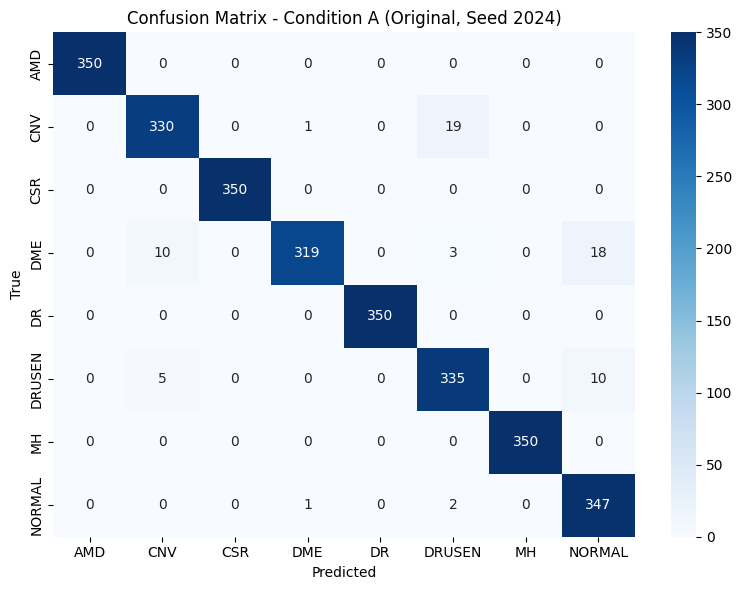

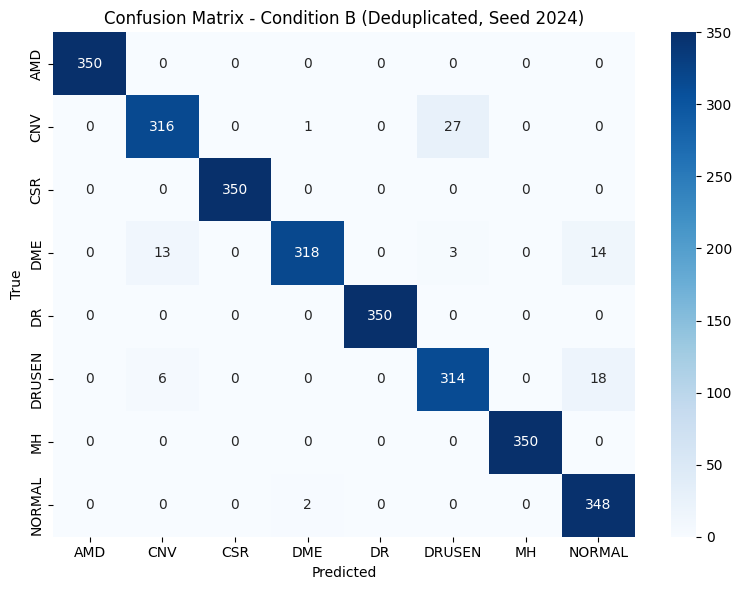

In [ ]:
os.makedirs(f'{PROJECT_DIR}/outputs/paper_figures', exist_ok=True)
FIG_DIR = f'{PROJECT_DIR}/outputs/paper_figures'

def plot_confusion(preds, labels, title, filename):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{filename}', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

plot_confusion(preds_A, labels_A, 'Confusion Matrix - Condition A (Original, Seed 2024)', 'confusion_matrix_A.png')
plot_confusion(preds_B, labels_B, 'Confusion Matrix - Condition B (Deduplicated, Seed 2024)', 'confusion_matrix_B.png')

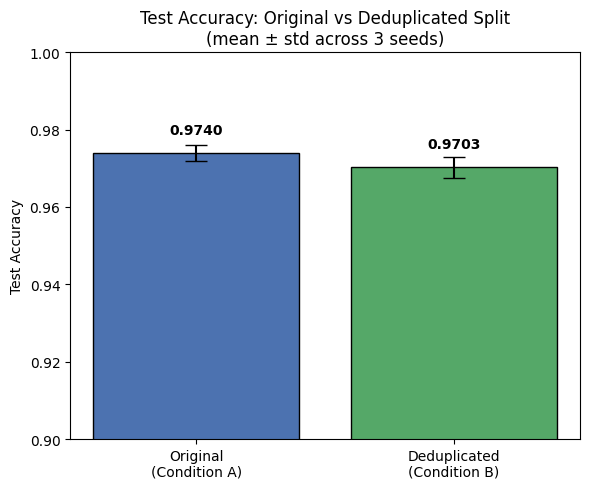

In [ ]:
plt.figure(figsize=(6, 5))
means = [np.mean(acc_A), np.mean(acc_B)]
stds = [np.std(acc_A), np.std(acc_B)]

bars = plt.bar(['Original\n(Condition A)', 'Deduplicated\n(Condition B)'], means, yerr=stds, capsize=8,
               color=['#4C72B0', '#55A868'], edgecolor='black')
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy: Original vs Deduplicated Split\n(mean ± std across 3 seeds)')
plt.ylim(0.90, 1.0)
for bar, mean in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width()/2, mean + 0.005, f'{mean:.4f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/accuracy_comparison_bar.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

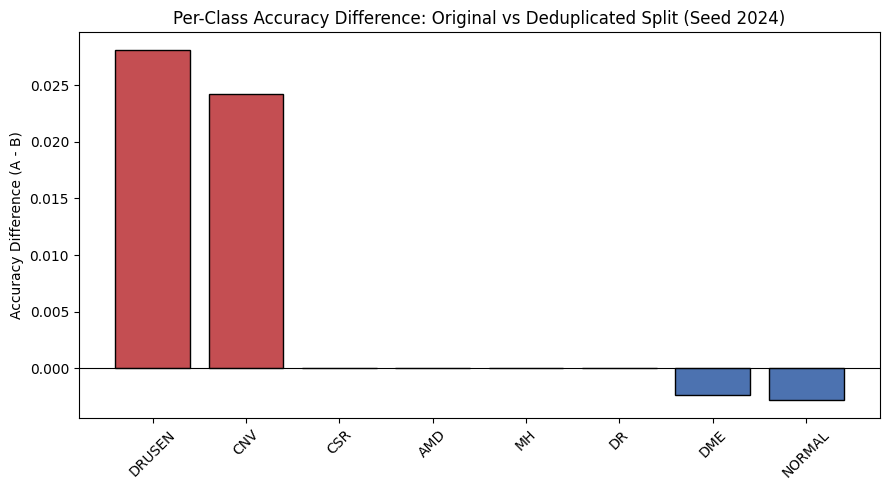

In [ ]:
plt.figure(figsize=(9, 5))
classes_sorted = per_class_df['class'].tolist()
diffs = per_class_df['diff (A - B)'].values

colors = ['#C44E52' if d > 0 else '#4C72B0' for d in diffs]
plt.bar(classes_sorted, diffs, color=colors, edgecolor='black')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Accuracy Difference (A - B)')
plt.title('Per-Class Accuracy Difference: Original vs Deduplicated Split (Seed 2024)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/per_class_accuracy_diff.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

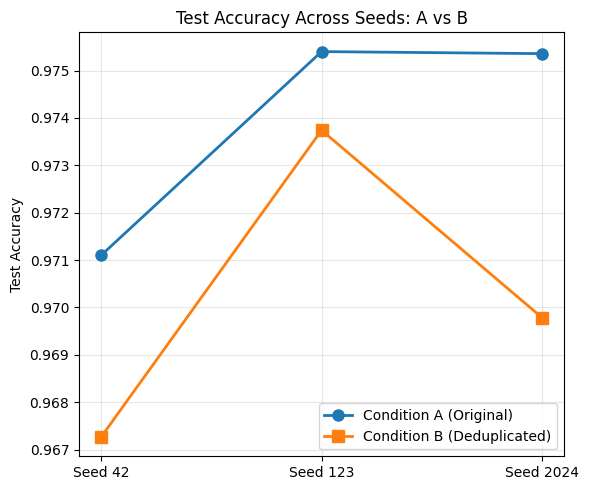

In [ ]:
plt.figure(figsize=(6, 5))
x = ['Seed 42', 'Seed 123', 'Seed 2024']
plt.plot(x, acc_A, marker='o', label='Condition A (Original)', linewidth=2, markersize=8)
plt.plot(x, acc_B, marker='s', label='Condition B (Deduplicated)', linewidth=2, markersize=8)
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy Across Seeds: A vs B')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/accuracy_across_seeds.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

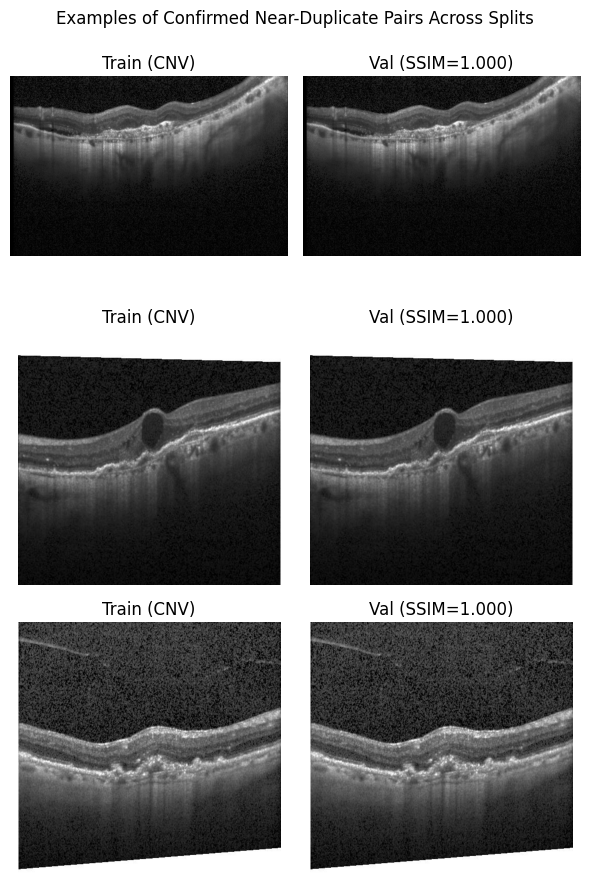

In [ ]:
tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
confirmed_pairs = tv_df[tv_df['confirmed_duplicate'] == True].head(3)

fig, axes = plt.subplots(len(confirmed_pairs), 2, figsize=(6, 3*len(confirmed_pairs)))
for i, (_, row) in enumerate(confirmed_pairs.iterrows()):
    img_train = plt.imread(row['train_path'])
    img_val = plt.imread(row['val_path'])
    axes[i, 0].imshow(img_train, cmap='gray')
    axes[i, 0].set_title(f"Train ({row['class']})")
    axes[i, 0].axis('off')
    axes[i, 1].imshow(img_val, cmap='gray')
    axes[i, 1].set_title(f"Val (SSIM={row['ssim_score']:.3f})")
    axes[i, 1].axis('off')

plt.suptitle('Examples of Confirmed Near-Duplicate Pairs Across Splits')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/duplicate_examples.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

class
DRUSEN    25
CNV       12
DME       11
NORMAL     1
Name: count, dtype: int64


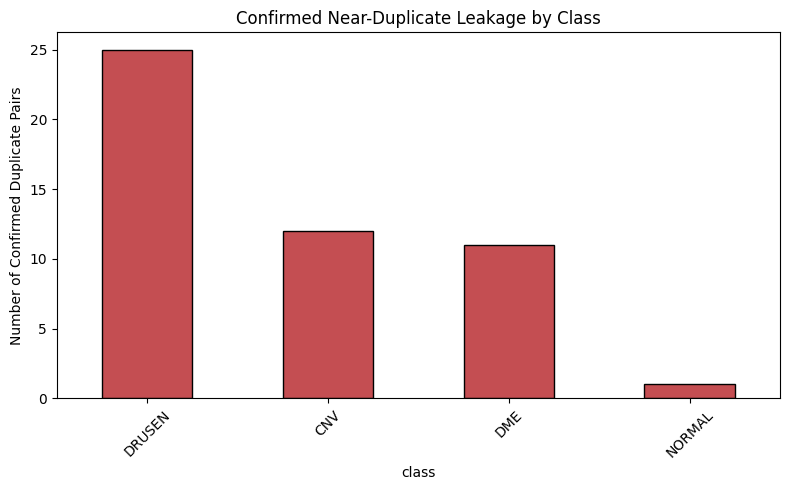

In [ ]:
tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

tv_conf = tv_df[tv_df['confirmed_duplicate']]
tt_conf = tt_df[tt_df['confirmed_duplicate']]
vt_conf = vt_df[vt_df['confirmed_duplicate']]

# 'class' column thakle tv/tt/vt csv-e, na thakle path theke extract korte hobe
leak_counts = pd.concat([
    tv_conf['class'] if 'class' in tv_conf.columns else tv_conf['train_class'],
    tt_conf['class'] if 'class' in tt_conf.columns else tt_conf['train_class'],
    vt_conf['class'] if 'class' in vt_conf.columns else vt_conf['val_class'],
]).value_counts()

print(leak_counts)

plt.figure(figsize=(8,5))
leak_counts.plot(kind='bar', color='#C44E52', edgecolor='black')
plt.ylabel('Number of Confirmed Duplicate Pairs')
plt.title('Confirmed Near-Duplicate Leakage by Class')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/leak_count_by_class.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

In [ ]:
# CNV chara alada class theke example nichi, jate figure diverse hoy
diverse_examples = pd.concat([
    tv_conf[tv_conf.get('class', tv_conf.get('train_class')) != 'CNV'].head(2),
    tv_conf[tv_conf.get('class', tv_conf.get('train_class')) == 'CNV'].head(1),
])

In [ ]:
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

tt_conf = tt_df[tt_df['confirmed_duplicate']]
vt_conf = vt_df[vt_df['confirmed_duplicate']]

print("Train-Test confirmed columns:", tt_conf.columns.tolist())
print(tt_conf.head())

Train-Test confirmed columns: ['train_path', 'test_path', 'class', 'hamming_distance', 'ssim_score', 'confirmed_duplicate']
                                           train_path  \
20  /content/drive/MyDrive/OCT_C8_Project/dataset/...   
21  /content/drive/MyDrive/OCT_C8_Project/dataset/...   
22  /content/drive/MyDrive/OCT_C8_Project/dataset/...   
33  /content/drive/MyDrive/OCT_C8_Project/dataset/...   
34  /content/drive/MyDrive/OCT_C8_Project/dataset/...   

                                            test_path class  hamming_distance  \
20  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   
21  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   
22  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   
33  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   
34  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   

    ssim_score  confirmed_duplicate  
20      


Leaks affecting TEST set specifically:
class
DRUSEN    12
CNV        6
DME        2
Name: count, dtype: int64


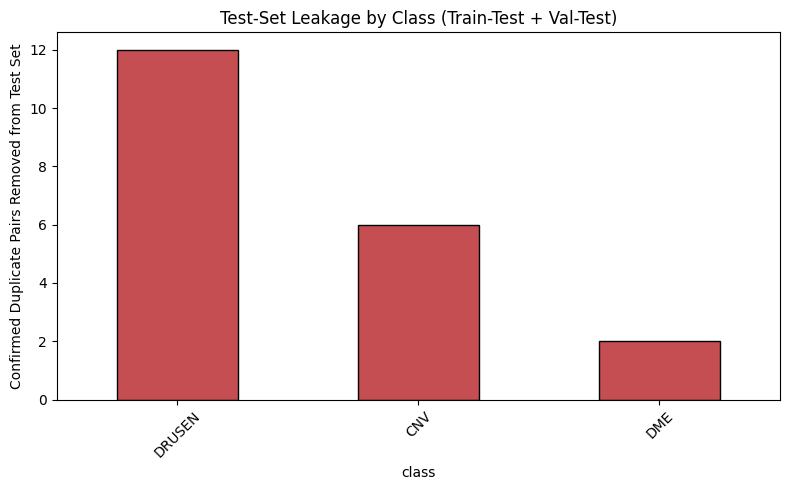

In [ ]:
# Column name confirm howar por eta run koro (dhoro column 'class' ache)
test_affecting_leaks = pd.concat([
    tt_conf['class'] if 'class' in tt_conf.columns else tt_conf['test_class'],
    vt_conf['class'] if 'class' in vt_conf.columns else vt_conf['test_class'],
])

test_leak_counts = test_affecting_leaks.value_counts()
print("\nLeaks affecting TEST set specifically:")
print(test_leak_counts)

plt.figure(figsize=(8,5))
test_leak_counts.plot(kind='bar', color='#C44E52', edgecolor='black')
plt.ylabel('Confirmed Duplicate Pairs Removed from Test Set')
plt.title('Test-Set Leakage by Class (Train-Test + Val-Test)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/test_leak_count_by_class.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

print("Ready:", PROJECT_DIR)
print(os.listdir(dataset_root))  # ['test', 'train', 'val'] asha uchit

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready: /content/drive/MyDrive/OCT_C8_Project
['test', 'train', 'val']


In [ ]:
!pip install -q imagehash

import imagehash
from PIL import Image
import pandas as pd
import numpy as np

def popcount64(x):
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0f0f0f0f0f0f0f0f)
    return (x * np.uint64(0x0101010101010101)) >> np.uint64(56)

def compute_hashes_by_class(split_path):
    data = {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join(split_path, class_name)
        paths, hashes = [], []
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            try:
                h = imagehash.phash(Image.open(fpath))
                paths.append(fpath)
                hashes.append(int(str(h), 16))
            except Exception as e:
                print("Skip:", fpath, e)
        data[class_name] = (paths, np.array(hashes, dtype=np.uint64))
        print(f"  {class_name}: {len(paths)} hashed")
    return data

print("Hashing TRAIN...")
train_data = compute_hashes_by_class(os.path.join(dataset_root, 'train'))
print("Hashing VAL...")
val_data = compute_hashes_by_class(os.path.join(dataset_root, 'val'))
print("Hashing TEST...")
test_data = compute_hashes_by_class(os.path.join(dataset_root, 'test'))
print("All hashing done.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 10.9 MB/s eta 0:00:00
Hashing TRAIN...
  AMD: 2300 hashed
  CNV: 2300 hashed
  CSR: 2300 hashed
  DME: 2300 hashed
  DR: 2300 hashed
  DRUSEN: 2300 hashed
  MH: 2300 hashed
  NORMAL: 2300 hashed
Hashing VAL...
  AMD: 350 hashed
  CNV: 350 hashed
  CSR: 350 hashed
  DME: 350 hashed
  DR: 350 hashed
  DRUSEN: 350 hashed
  MH: 350 hashed
  NORMAL: 350 hashed
Hashing TEST...
  AMD: 350 hashed
  CNV: 350 hashed
  CSR: 350 hashed
  DME: 350 hashed
  DR: 350 hashed
  DRUSEN: 350 hashed
  MH: 350 hashed
  NORMAL: 350 hashed
All hashing done.


In [ ]:
import pandas as pd
import numpy as np

def count_leaks_at_threshold(data_a, data_b, threshold):
    """Total leak pair count across shared classes, ekta threshold-e"""
    total = 0
    classes = sorted(set(data_a.keys()) & set(data_b.keys()))
    for cls in classes:
        paths_a, hashes_a = data_a[cls]
        paths_b, hashes_b = data_b[cls]
        if len(hashes_a) == 0 or len(hashes_b) == 0:
            continue
        xor_matrix = hashes_a[:, None] ^ hashes_b[None, :]
        dist_matrix = popcount64(xor_matrix)
        total += int((dist_matrix <= threshold).sum())
    return total

THRESHOLDS = [0, 2, 4, 5, 6, 8, 10, 12]

sweep_results = []
for th in THRESHOLDS:
    tv = count_leaks_at_threshold(train_data, val_data, th)
    tt = count_leaks_at_threshold(train_data, test_data, th)
    vt = count_leaks_at_threshold(val_data, test_data, th)
    sweep_results.append({'threshold': th, 'train_val': tv, 'train_test': tt, 'val_test': vt, 'total': tv+tt+vt})
    print(f"Threshold={th}: Train-Val={tv}, Train-Test={tt}, Val-Test={vt}, Total={tv+tt+vt}")

sweep_df = pd.DataFrame(sweep_results)
sweep_df.to_csv(f'{PROJECT_DIR}/outputs/phash_threshold_sensitivity.csv', index=False)
print("\nSaved sensitivity table.")

Threshold=0: Train-Val=29, Train-Test=24, Val-Test=1, Total=54
Threshold=2: Train-Val=56, Train-Test=56, Val-Test=1, Total=113
Threshold=4: Train-Val=175, Train-Test=158, Val-Test=12, Total=345
Threshold=5: Train-Val=175, Train-Test=158, Val-Test=12, Total=345
Threshold=6: Train-Val=478, Train-Test=491, Val-Test=58, Total=1027
Threshold=8: Train-Val=1540, Train-Test=1550, Val-Test=230, Total=3320
Threshold=10: Train-Val=4822, Train-Test=4867, Val-Test=721, Total=10410
Threshold=12: Train-Val=13705, Train-Test=14212, Val-Test=2109, Total=30026

Saved sensitivity table.


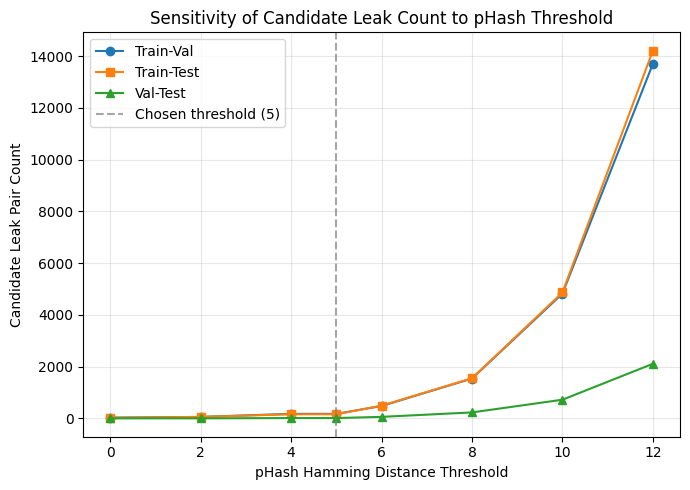

In [ ]:
import matplotlib.pyplot as plt

os.makedirs(f'{PROJECT_DIR}/outputs/paper_figures', exist_ok=True)
FIG_DIR = f'{PROJECT_DIR}/outputs/paper_figures'

plt.figure(figsize=(7,5))
plt.plot(sweep_df['threshold'], sweep_df['train_val'], marker='o', label='Train-Val')
plt.plot(sweep_df['threshold'], sweep_df['train_test'], marker='s', label='Train-Test')
plt.plot(sweep_df['threshold'], sweep_df['val_test'], marker='^', label='Val-Test')
plt.axvline(5, color='gray', linestyle='--', alpha=0.7, label='Chosen threshold (5)')
plt.xlabel('pHash Hamming Distance Threshold')
plt.ylabel('Candidate Leak Pair Count')
plt.title('Sensitivity of Candidate Leak Count to pHash Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/phash_threshold_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

SSIM>=0.8: Train-Val=30, Train-Test=23, Val-Test=2, Total=55
SSIM>=0.85: Train-Val=29, Train-Test=21, Val-Test=1, Total=51
SSIM>=0.9: Train-Val=29, Train-Test=19, Val-Test=1, Total=49
SSIM>=0.95: Train-Val=27, Train-Test=19, Val-Test=1, Total=47
SSIM>=0.99: Train-Val=26, Train-Test=19, Val-Test=1, Total=46


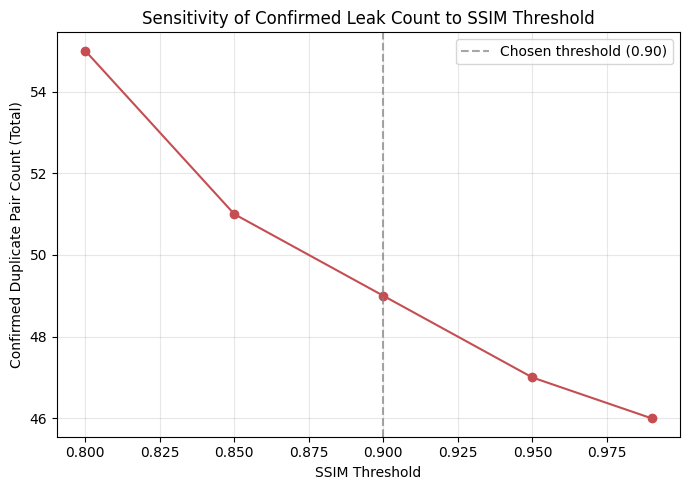

In [ ]:
tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

SSIM_THRESHOLDS = [0.80, 0.85, 0.90, 0.95, 0.99]

ssim_sweep = []
for th in SSIM_THRESHOLDS:
    tv_c = (tv_df['ssim_score'] >= th).sum()
    tt_c = (tt_df['ssim_score'] >= th).sum()
    vt_c = (vt_df['ssim_score'] >= th).sum()
    ssim_sweep.append({'ssim_threshold': th, 'train_val': tv_c, 'train_test': tt_c, 'val_test': vt_c, 'total': tv_c+tt_c+vt_c})
    print(f"SSIM>={th}: Train-Val={tv_c}, Train-Test={tt_c}, Val-Test={vt_c}, Total={tv_c+tt_c+vt_c}")

ssim_sweep_df = pd.DataFrame(ssim_sweep)
ssim_sweep_df.to_csv(f'{PROJECT_DIR}/outputs/ssim_threshold_sensitivity.csv', index=False)

plt.figure(figsize=(7,5))
plt.plot(ssim_sweep_df['ssim_threshold'], ssim_sweep_df['total'], marker='o', color='#C44E52')
plt.axvline(0.90, color='gray', linestyle='--', alpha=0.7, label='Chosen threshold (0.90)')
plt.xlabel('SSIM Threshold')
plt.ylabel('Confirmed Duplicate Pair Count (Total)')
plt.title('Sensitivity of Confirmed Leak Count to SSIM Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/ssim_threshold_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

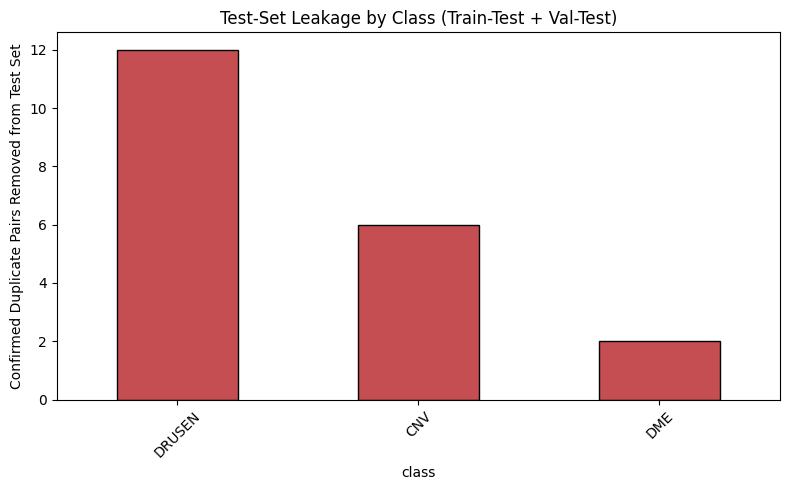

         metric    t_stat   p_value  mean_diff  std_diff  cohens_d
0  paired_ttest  3.257939  0.082695   0.003689  0.001601   2.30371


In [ ]:
# --- Test-set-specific leak chart, save kore rakhi ---
tt_conf = tt_df[tt_df['confirmed_duplicate']]
vt_conf = vt_df[vt_df['confirmed_duplicate']]

test_affecting_leaks = pd.concat([tt_conf['class'], vt_conf['class']])
test_leak_counts = test_affecting_leaks.value_counts()
test_leak_counts.to_csv(f'{PROJECT_DIR}/outputs/test_leak_counts_by_class.csv')

plt.figure(figsize=(8,5))
test_leak_counts.plot(kind='bar', color='#C44E52', edgecolor='black')
plt.ylabel('Confirmed Duplicate Pairs Removed from Test Set')
plt.title('Test-Set Leakage by Class (Train-Test + Val-Test)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/test_leak_count_by_class.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# --- Statistical test result, save kore rakhi ---
from scipy import stats
acc_A = [0.9711, 0.9754, 0.975357]
acc_B = [0.967266, 0.973741, 0.969784]
t_stat, p_value = stats.ttest_rel(acc_A, acc_B)
diff = np.array(acc_A) - np.array(acc_B)
cohens_d = diff.mean() / diff.std()

stat_summary = pd.DataFrame([{
    'metric': 'paired_ttest',
    't_stat': t_stat, 'p_value': p_value,
    'mean_diff': diff.mean(), 'std_diff': diff.std(), 'cohens_d': cohens_d
}])
stat_summary.to_csv(f'{PROJECT_DIR}/outputs/statistical_test_summary.csv', index=False)
print(stat_summary)

In [ ]:
from sklearn.metrics import classification_report

print("=== Condition A (seed 2024) ===")
print(classification_report(labels_A, preds_A, target_names=CLASS_NAMES, digits=4))

print("\n=== Condition B (seed 2024) ===")
print(classification_report(labels_B, preds_B, target_names=CLASS_NAMES, digits=4))

# Save as CSV too
report_A = classification_report(labels_A, preds_A, target_names=CLASS_NAMES, digits=4, output_dict=True)
report_B = classification_report(labels_B, preds_B, target_names=CLASS_NAMES, digits=4, output_dict=True)

pd.DataFrame(report_A).transpose().to_csv(f'{PROJECT_DIR}/outputs/classification_report_A.csv')
pd.DataFrame(report_B).transpose().to_csv(f'{PROJECT_DIR}/outputs/classification_report_B.csv')
print("\nSaved classification reports.")

=== Condition A (seed 2024) ===
              precision    recall  f1-score   support

         AMD     1.0000    1.0000    1.0000       350
         CNV     0.9565    0.9429    0.9496       350
         CSR     1.0000    1.0000    1.0000       350
         DME     0.9938    0.9114    0.9508       350
          DR     1.0000    1.0000    1.0000       350
      DRUSEN     0.9331    0.9571    0.9450       350
          MH     1.0000    1.0000    1.0000       350
      NORMAL     0.9253    0.9914    0.9572       350

    accuracy                         0.9754      2800
   macro avg     0.9761    0.9754    0.9753      2800
weighted avg     0.9761    0.9754    0.9753      2800


=== Condition B (seed 2024) ===
              precision    recall  f1-score   support

         AMD     1.0000    1.0000    1.0000       350
         CNV     0.9433    0.9186    0.9308       344
         CSR     1.0000    1.0000    1.0000       350
         DME     0.9907    0.9138    0.9507       348
          DR 

In [ ]:
import pandas as pd

tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

tv_conf = tv_df[tv_df['confirmed_duplicate']]
tt_conf = tt_df[tt_df['confirmed_duplicate']]
vt_conf = vt_df[vt_df['confirmed_duplicate']]

leak_counts = pd.concat([tv_conf['class'], tt_conf['class'], vt_conf['class']]).value_counts()

leak_counts_df = leak_counts.reset_index()
leak_counts_df.columns = ['class', 'confirmed_duplicate_pairs']
leak_counts_df.to_csv(f'{PROJECT_DIR}/outputs/all_leaks_by_class.csv', index=False)

print(leak_counts_df)
print("\nSaved to all_leaks_by_class.csv")

    class  confirmed_duplicate_pairs
0  DRUSEN                         25
1     CNV                         12
2     DME                         11
3  NORMAL                          1

Saved to all_leaks_by_class.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
print(os.listdir(dataset_root))  # ['test', 'train', 'val'] asha uchit

Mounted at /content/drive
['test', 'train', 'val']


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import pandas as pd
import glob

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU on na — Runtime > Change runtime type > GPU kore Cell 1 theke abar shuru koro")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels)

def run_experiment(train_list, val_list, test_list, seed, epochs=10, batch_size=32, lr=1e-4):
    set_seed(seed)
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _ = evaluate(model, val_loader)
        print(f"    Epoch {epoch+1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")

    test_acc, preds, labels = evaluate(model, test_loader)
    return test_acc, preds, labels

In [ ]:
SEEDS = [42, 123, 2024, 7, 17, 55, 99]   # original 3 + 4 notun (chao to ei list e add/remove korte paro)
EPOCHS = 10

def preds_path(letter, seed):
    return f'{PROJECT_DIR}/outputs/preds_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{PROJECT_DIR}/outputs/{condition}_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]  # purono thakle sorao (upsert)
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'='*60}\n{cond_label} — {len(SEEDS)}-ta seed check hocche\n{'='*60}")

    for seed in SEEDS:
        pfile = preds_path(letter, seed)
        if os.path.exists(pfile):
            print(f"[{cond_label} | seed {seed}] already saved — skip")
            continue

        print(f"[{cond_label} | seed {seed}] running...")
        start = time.time()
        test_acc, preds, labels = run_experiment(train_l, val_l, test_l, seed, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60

        # --- IMMEDIATELY save, run shesh hoyei ---
        with open(pfile, 'wb') as f:
            pickle.dump((preds, labels), f)
        upsert_result(condition, cond_label, seed, test_acc)

        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nSob shesh (ba ekhon porjonto jotota holo).")


A_original — 7-ta seed check hocche
[A_original | seed 42] running...
    Epoch 1/10 | loss=0.2596 train_acc=0.9106 val_acc=0.9504
    Epoch 2/10 | loss=0.1245 train_acc=0.9594 val_acc=0.9496
    Epoch 3/10 | loss=0.1041 train_acc=0.9668 val_acc=0.9668
    Epoch 4/10 | loss=0.0866 train_acc=0.9709 val_acc=0.9675
    Epoch 5/10 | loss=0.0801 train_acc=0.9732 val_acc=0.9686


In [ ]:
for cond in ['condA', 'condB']:
    p = f'{PROJECT_DIR}/outputs/{cond}_results.csv'
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"{cond}: seeds done = {sorted(df['seed'].tolist())}")
    else:
        print(f"{cond}: kono result nei ekhono")

print("\nSaved prediction files:")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/preds_*_seed*.pkl')):
    print(" ", os.path.basename(f))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
print(os.listdir(dataset_root))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['test', 'train', 'val']


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import pandas as pd
import glob

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU on na — Runtime > Change runtime type > GPU")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels)

def run_experiment(train_list, val_list, test_list, seed, epochs=10, batch_size=32, lr=1e-4):
    set_seed(seed)
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _ = evaluate(model, val_loader)
        print(f"    Epoch {epoch+1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")

    test_acc, preds, labels = evaluate(model, test_loader)
    return test_acc, preds, labels

In [ ]:
SEEDS = [42, 123, 2024, 7, 17, 55, 99]
EPOCHS = 10

def preds_path(letter, seed):
    return f'{PROJECT_DIR}/outputs/preds_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{PROJECT_DIR}/outputs/{condition}_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'='*60}\n{cond_label} — {len(SEEDS)}-ta seed check hocche\n{'='*60}")

    for seed in SEEDS:
        pfile = preds_path(letter, seed)
        if os.path.exists(pfile):
            print(f"[{cond_label} | seed {seed}] already saved — skip")
            continue

        print(f"[{cond_label} | seed {seed}] running...")
        start = time.time()
        test_acc, preds, labels = run_experiment(train_l, val_l, test_l, seed, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60

        with open(pfile, 'wb') as f:
            pickle.dump((preds, labels), f)
        upsert_result(condition, cond_label, seed, test_acc)

        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nSob shesh (ba ekhon porjonto jotota holo).")


A_original — 7-ta seed check hocche
[A_original | seed 42] running...


KeyboardInterrupt: 

In [ ]:
for cond in ['condA', 'condB']:
    p = f'{PROJECT_DIR}/outputs/{cond}_results.csv'
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"{cond}: seeds done = {sorted(df['seed'].tolist())}")
    else:
        print(f"{cond}: kono result nei ekhono")

print("\nSaved prediction files:")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/preds_*_seed*.pkl')):
    print(" ", os.path.basename(f))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
print(os.listdir(dataset_root))  # expect ['test', 'train', 'val']

Mounted at /content/drive
['test', 'train', 'val']


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import pandas as pd
import glob

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU not on — Runtime > Change runtime type > GPU, then redo from Cell 1")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
import torch.nn.functional as Fnn

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate_full(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels), np.array(all_probs)

def checkpoint_path(letter, seed):
    os.makedirs(f'{PROJECT_DIR}/outputs/checkpoints', exist_ok=True)
    return f'{PROJECT_DIR}/outputs/checkpoints/ckpt_{letter}_seed{seed}.pt'

def run_experiment_resumable(train_list, val_list, test_list, seed, letter, epochs=10, batch_size=32, lr=1e-4):
    set_seed(seed)
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    ckpt_path = checkpoint_path(letter, seed)
    start_epoch = 0
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        print(f"    >> Resuming from epoch {start_epoch+1} (checkpoint found)")

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _, _ = evaluate_full(model, val_loader)
        print(f"    Epoch {epoch+1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")
        torch.save({'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict()}, ckpt_path)

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    return test_acc, preds, labels, probs, model

In [ ]:
SEEDS = [42, 123, 2024, 7, 17, 55, 99]
EPOCHS = 10
KEEP_CHECKPOINT_FOR = [('A', 2024)]

def full_results_path(letter, seed):
    return f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{PROJECT_DIR}/outputs/{condition}_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'='*60}\n{cond_label} — checking {len(SEEDS)} seeds\n{'='*60}")

    for seed in SEEDS:
        rfile = full_results_path(letter, seed)
        if os.path.exists(rfile):
            print(f"[{cond_label} | seed {seed}] already fully done — skip")
            continue
        print(f"[{cond_label} | seed {seed}] running (resumable, checkpointed every epoch)...")
        start = time.time()
        test_acc, preds, labels, probs, model = run_experiment_resumable(train_l, val_l, test_l, seed, letter, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60
        with open(rfile, 'wb') as f:
            pickle.dump({'preds': preds, 'labels': labels, 'probs': probs}, f)
        upsert_result(condition, cond_label, seed, test_acc)
        ckpt = checkpoint_path(letter, seed)
        if (letter, seed) in KEEP_CHECKPOINT_FOR:
            print(f"    (keeping checkpoint for {letter}/{seed} — reserved for Priority 2A)")
        elif os.path.exists(ckpt):
            os.remove(ckpt)
        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nAll done (or as far as this session got).")


A_original — checking 7 seeds
[A_original | seed 42] running (resumable, checkpointed every epoch)...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 138MB/s]


KeyboardInterrupt: 

In [ ]:
# Cell 1 — Mount Google Drive so we can read the dataset and save all outputs/checkpoints there
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
DRIVE_DATASET_ROOT = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

print(os.listdir(DRIVE_DATASET_ROOT))  # expect ['test', 'train', 'val']

Mounted at /content/drive
['test', 'train', 'val']


In [ ]:
# Cell 1B — Copy the dataset from Drive to local Colab disk once per session.
# Reason: reading thousands of small image files directly from a mounted/shared
# Drive folder during training is extremely slow and can hang with no error.
# Training will read from local disk instead; all results still get saved back to Drive.

import os, shutil, time

LOCAL_DATASET_ROOT = '/content/dataset_local/RetinalOCT_Dataset'
SENTINEL = f'{LOCAL_DATASET_ROOT}/.copy_complete'  # marker file so we don't re-copy if this cell reruns

if not os.path.exists(SENTINEL):
    if os.path.exists(LOCAL_DATASET_ROOT):
        shutil.rmtree(LOCAL_DATASET_ROOT)  # remove any incomplete previous copy
    print("Copying dataset from Drive to local disk (one-time this session, ~1.4GB)...")
    start = time.time()
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    with open(SENTINEL, 'w') as f:
        f.write('done')
    print(f"Copy finished in {(time.time() - start) / 60:.1f} min.")
else:
    print("Local dataset copy already complete this session — skipping.")

print(os.listdir(LOCAL_DATASET_ROOT))  # expect ['test', 'train', 'val']

Copying dataset from Drive to local disk (one-time this session, ~1.4GB)...
Copy finished in 11.3 min.
['.copy_complete', 'test', 'train', 'val']


In [ ]:
# Cell 2 — Core imports, custom PyTorch Dataset class, and image preprocessing/augmentation pipelines
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import pandas as pd
import glob

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU not on — go to Runtime > Change runtime type > GPU, then redo from Cell 1")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    # Wraps a list of (filepath, class_name) tuples into a PyTorch-compatible dataset
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')  # OCT scans are greyscale but stored/read as RGB for ResNet
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

# Training transform: light augmentation (rotation + horizontal flip) as used in the paper
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ImageNet stats, matches pretrained backbone
])

# Validation/test transform: no augmentation, only resize + normalize
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
# Cell 3 — Load the pre-computed train/val/test file lists (Condition A = original, Condition B = deduplicated)
# and rewrite every file path from the Drive location to the local-disk copy made in Cell 1B.

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

def remap_paths_to_local(file_label_list):
    # Replaces the Drive dataset root with the local dataset root in every file path
    return [(fpath.replace(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT), class_name) for fpath, class_name in file_label_list]

for key in list(splits.keys()):
    splits[key] = remap_paths_to_local(splits[key])

# Sanity check: confirm the remapped path actually exists on local disk
sample_path = splits['condA_train'][0][0]
print("Sample remapped path:", sample_path)
print("Exists on local disk:", os.path.exists(sample_path))

print("Train:", len(splits['condA_train']),
      "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Sample remapped path: /content/dataset_local/RetinalOCT_Dataset/train/AMD/amd_train_2301.jpg
Exists on local disk: True
Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
# Cell 4B — Defines: seeding, model builder, one training epoch, full evaluation (accuracy + predictions
# + labels + softmax probabilities for later ROC-AUC), per-epoch checkpoint save/resume logic, and the
# full resumable single-run trainer used for every (condition, seed) combination.

import torch.nn.functional as Fnn

def set_seed(seed):
    # Fixes all relevant random seeds so a given seed run is reproducible
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    # ResNet18 with ImageNet-pretrained weights, final layer replaced for 8-class OCT classification
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    # Runs one full pass over the training set; returns average loss and training accuracy
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate_full(model, loader):
    # Runs inference over a loader; returns accuracy, hard predictions, true labels, and softmax
    # probabilities (probabilities are required later for ROC-AUC, which the old pipeline never saved)
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels), np.array(all_probs)

def checkpoint_path(letter, seed):
    # Path (on Drive) where this (condition, seed)'s in-progress model checkpoint is stored
    os.makedirs(f'{PROJECT_DIR}/outputs/checkpoints', exist_ok=True)
    return f'{PROJECT_DIR}/outputs/checkpoints/ckpt_{letter}_seed{seed}.pt'

def run_experiment_resumable(train_list, val_list, test_list, seed, letter, epochs=10, batch_size=32, lr=1e-4):
    # Trains one (condition, seed) combination end to end.
    # If a checkpoint already exists for this (letter, seed), resumes from the next epoch
    # instead of restarting — so a session crash never loses more than one epoch of progress.
    set_seed(seed)
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    ckpt_path = checkpoint_path(letter, seed)
    start_epoch = 0
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        print(f"    >> Resuming from epoch {start_epoch + 1} (checkpoint found)")

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _, _ = evaluate_full(model, val_loader)
        print(f"    Epoch {epoch + 1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")

        # Save checkpoint after EVERY epoch — a crash now loses at most 1 epoch, not the whole run
        torch.save({'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict()}, ckpt_path)

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    return test_acc, preds, labels, probs, model

In [ ]:
# Cell 5B — The main driver loop. For each condition (A, B) and each seed, skips any combination
# that's already fully saved, otherwise trains it (resumable at the epoch level via Cell 4B) and
# immediately saves predictions + labels + probabilities + updates the running accuracy CSV.
# Safe to stop and re-run this cell any number of times, in any session, on any Google account.

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
EPOCHS = 10
KEEP_CHECKPOINT_FOR = [('A', 2024)]  # keep this one checkpoint permanently for the later Priority-2A experiment

def full_results_path(letter, seed):
    return f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{PROJECT_DIR}/outputs/{condition}_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    # Adds/updates this seed's accuracy in the condition's running CSV log (immediate save, not batched)
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'=' * 60}\n{cond_label} — checking {len(SEEDS)} seeds\n{'=' * 60}")

    for seed in SEEDS:
        rfile = full_results_path(letter, seed)
        if os.path.exists(rfile):
            print(f"[{cond_label} | seed {seed}] already fully done — skip")
            continue

        print(f"[{cond_label} | seed {seed}] running (resumable, checkpointed every epoch)...")
        start = time.time()
        test_acc, preds, labels, probs, model = run_experiment_resumable(train_l, val_l, test_l, seed, letter, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60

        # Save full results (predictions + labels + probabilities) immediately — do not wait until all seeds finish
        with open(rfile, 'wb') as f:
            pickle.dump({'preds': preds, 'labels': labels, 'probs': probs}, f)
        upsert_result(condition, cond_label, seed, test_acc)

        # Delete the checkpoint now that the run is fully saved (unless it's the one reserved for Priority 2A)
        ckpt = checkpoint_path(letter, seed)
        if (letter, seed) in KEEP_CHECKPOINT_FOR:
            print(f"    (keeping checkpoint for {letter}/{seed} — reserved for Priority 2A)")
        elif os.path.exists(ckpt):
            os.remove(ckpt)

        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nAll done (or as far as this session got).")


A_original — checking 7 seeds
[A_original | seed 42] already fully done — skip
[A_original | seed 123] already fully done — skip
[A_original | seed 2024] already fully done — skip
[A_original | seed 7] already fully done — skip
[A_original | seed 17] already fully done — skip
[A_original | seed 55] running (resumable, checkpointed every epoch)...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 123MB/s]


    >> Resuming from epoch 4 (checkpoint found)
    Epoch 4/10 | loss=0.0744 train_acc=0.9757 val_acc=0.9682
    Epoch 5/10 | loss=0.0559 train_acc=0.9816 val_acc=0.9668
    Epoch 6/10 | loss=0.0524 train_acc=0.9830 val_acc=0.9611
    Epoch 7/10 | loss=0.0767 train_acc=0.9731 val_acc=0.9668
    Epoch 8/10 | loss=0.0652 train_acc=0.9780 val_acc=0.9675
    Epoch 9/10 | loss=0.0597 train_acc=0.9810 val_acc=0.9643
    Epoch 10/10 | loss=0.0499 train_acc=0.9834 val_acc=0.9682
[A_original | seed 55] DONE — test_acc=0.9746 | 16.5 min | saved.
[A_original | seed 99] running (resumable, checkpointed every epoch)...
    Epoch 1/10 | loss=0.2613 train_acc=0.9122 val_acc=0.9614
    Epoch 2/10 | loss=0.1238 train_acc=0.9585 val_acc=0.9596
    Epoch 3/10 | loss=0.1041 train_acc=0.9650 val_acc=0.9586
    Epoch 4/10 | loss=0.0892 train_acc=0.9698 val_acc=0.9675
    Epoch 5/10 | loss=0.0829 train_acc=0.9718 val_acc=0.9700
    Epoch 6/10 | loss=0.0738 train_acc=0.9752 val_acc=0.9596
    Epoch 7/10 | los

In [ ]:
# Cell 6B — Reports exactly what's done, what's mid-run (and which epoch it'll resume from),
# and what old-style (pre-upgrade) files still exist. Run this any time to check status.

for cond in ['condA', 'condB']:
    p = f'{PROJECT_DIR}/outputs/{cond}_results.csv'
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"{cond}: seeds with final accuracy recorded = {sorted(df['seed'].tolist())}")
    else:
        print(f"{cond}: no results yet")

print("\nFully-finished runs (full_results_*.pkl, includes probabilities):")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/full_results_*_seed*.pkl')):
    print(" ", os.path.basename(f))

print("\nIn-progress checkpoints (partial runs, will auto-resume from here):")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/checkpoints/ckpt_*_seed*.pt')):
    ckpt = torch.load(f, map_location='cpu')
    print(f"  {os.path.basename(f)} — completed up through epoch {ckpt['epoch'] + 1}")

print("\nOLD-style files (pre-upgrade, preds+labels only, NO probabilities/ROC-AUC possible):")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/preds_*_seed*.pkl')):
    print(" ", os.path.basename(f))

condA: seeds with final accuracy recorded = [7, 17, 42, 55, 99, 123, 2024]
condB: seeds with final accuracy recorded = [7, 17, 42, 55, 99, 123, 2024]

Fully-finished runs (full_results_*.pkl, includes probabilities):
  full_results_A_seed123.pkl
  full_results_A_seed17.pkl
  full_results_A_seed2024.pkl
  full_results_A_seed42.pkl
  full_results_A_seed55.pkl
  full_results_A_seed7.pkl
  full_results_A_seed99.pkl
  full_results_B_seed123.pkl
  full_results_B_seed17.pkl
  full_results_B_seed2024.pkl
  full_results_B_seed42.pkl
  full_results_B_seed55.pkl
  full_results_B_seed7.pkl
  full_results_B_seed99.pkl

In-progress checkpoints (partial runs, will auto-resume from here):
  ckpt_A_seed2024.pt — completed up through epoch 10

OLD-style files (pre-upgrade, preds+labels only, NO probabilities/ROC-AUC possible):
  preds_A_seed2024.pkl
  preds_B_seed123.pkl
  preds_B_seed2024.pkl
  preds_B_seed42.pkl


In [ ]:
# Cell 7 — Computes Accuracy, Precision, Recall, F1, Specificity, ROC-AUC, and Confusion Matrix
# (macro-average + per-class) for every completed new-style run, and saves one master CSV.
# This becomes the authoritative results table for the paper.

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np

def compute_full_metrics(preds, labels, probs=None, class_names=CLASS_NAMES):
    n = len(class_names)
    cm = confusion_matrix(labels, preds, labels=list(range(n)))
    report = classification_report(labels, preds, target_names=class_names, output_dict=True, digits=4)

    # Specificity isn't in sklearn's classification_report, so compute it manually per class
    specificity = {}
    total = cm.sum()
    for i, c in enumerate(class_names):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = total - TP - FN - FP
        specificity[c] = TN / (TN + FP) if (TN + FP) > 0 else float('nan')

    result = {
        'accuracy': report['accuracy'],
        'macro_precision': report['macro avg']['precision'],
        'macro_recall': report['macro avg']['recall'],
        'macro_f1': report['macro avg']['f1-score'],
        'macro_specificity': float(np.nanmean(list(specificity.values()))),
    }
    for c in class_names:
        result[f'{c}_precision'] = report[c]['precision']
        result[f'{c}_recall'] = report[c]['recall']
        result[f'{c}_f1'] = report[c]['f1-score']
        result[f'{c}_specificity'] = specificity[c]

    # ROC-AUC needs probability scores, only available from the new-style (Cell 4B/5B) runs
    if probs is not None:
        try:
            auc_macro = roc_auc_score(labels, probs, multi_class='ovr', average='macro', labels=list(range(n)))
            result['macro_roc_auc'] = auc_macro
            per_class_auc = roc_auc_score(labels, probs, multi_class='ovr', average=None, labels=list(range(n)))
            for i, c in enumerate(class_names):
                result[f'{c}_roc_auc'] = per_class_auc[i]
        except Exception as e:
            print("  (ROC-AUC skipped:", e, ")")

    return result, cm

# Model parameter count is architecture-only, independent of any specific run
_tmp_model = build_model(len(CLASS_NAMES))
n_params = sum(p.numel() for p in _tmp_model.parameters())
n_trainable = sum(p.numel() for p in _tmp_model.parameters() if p.requires_grad)
print(f"ResNet18 total parameters: {n_params:,} | trainable: {n_trainable:,}")
del _tmp_model

# Loop over every fully-completed new-style result file and build one master metrics table
all_rows = []
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/full_results_*_seed*.pkl')):
    fname = os.path.basename(f)
    with open(f, 'rb') as fh:
        d = pickle.load(fh)
    metrics, cm = compute_full_metrics(d['preds'], d['labels'], d.get('probs'))
    metrics['file'] = fname
    all_rows.append(metrics)

if all_rows:
    metrics_df = pd.DataFrame(all_rows)
    metrics_df.to_csv(f'{PROJECT_DIR}/outputs/full_metrics_all_seeds.csv', index=False)
    print(f"\nSaved full_metrics_all_seeds.csv with {len(metrics_df)} rows.")
    print(metrics_df[['file', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_specificity'] +
                      (['macro_roc_auc'] if 'macro_roc_auc' in metrics_df.columns else [])])
else:
    print("No full_results_*.pkl files yet — run Cell 5B first.")

ResNet18 total parameters: 11,180,616 | trainable: 11,180,616

Saved full_metrics_all_seeds.csv with 14 rows.
                           file  accuracy  macro_precision  macro_recall  \
0    full_results_A_seed123.pkl  0.960714         0.964125      0.960714   
1     full_results_A_seed17.pkl  0.971071         0.972189      0.971071   
2   full_results_A_seed2024.pkl  0.970000         0.970589      0.970000   
3     full_results_A_seed42.pkl  0.968929         0.970051      0.968929   
4     full_results_A_seed55.pkl  0.974643         0.974894      0.974643   
5      full_results_A_seed7.pkl  0.975357         0.975875      0.975357   
6     full_results_A_seed99.pkl  0.974286         0.974956      0.974286   
7    full_results_B_seed123.pkl  0.975180         0.975422      0.974887   
8     full_results_B_seed17.pkl  0.977338         0.977338      0.977045   
9   full_results_B_seed2024.pkl  0.973022         0.973163      0.972730   
10    full_results_B_seed42.pkl  0.974820         0.97

In [ ]:
# Cell 8 — Computes everything except ROC-AUC from the OLD-style prediction files
# (from the original 3-seed run, before probabilities were saved). Useful as an immediate
# stopgap while the full 7-seed re-run (Cell 5B) is still in progress. Requires Cell 7's
# compute_full_metrics() function to already be defined.

old_rows = []
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/preds_*_seed*.pkl')):
    with open(f, 'rb') as fh:
        preds, labels = pickle.load(fh)  # old format: plain (preds, labels) tuple, no probabilities
    metrics, cm = compute_full_metrics(preds, labels, probs=None)  # ROC-AUC auto-skipped
    metrics['file'] = os.path.basename(f)
    old_rows.append(metrics)

if old_rows:
    old_metrics_df = pd.DataFrame(old_rows)
    old_metrics_df.to_csv(f'{PROJECT_DIR}/outputs/partial_metrics_old_files.csv', index=False)
    print(old_metrics_df[['file', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_specificity']])
    print("\n(No ROC-AUC column here — old files never saved probability scores. Re-run under Cell 5B for that.)")
else:
    print("No old-style preds_*.pkl files found.")

                   file  accuracy  macro_precision  macro_recall  macro_f1  \
0  preds_A_seed2024.pkl  0.975357         0.976097      0.975357  0.975337   
1   preds_B_seed123.pkl  0.973741         0.973934      0.973473  0.973483   
2  preds_B_seed2024.pkl  0.969784         0.970315      0.969460  0.969462   
3    preds_B_seed42.pkl  0.967266         0.968299      0.967023  0.966660   

   macro_specificity  
0           0.996480  
1           0.996253  
2           0.995689  
3           0.995332  

(No ROC-AUC column here — old files never saved probability scores. Re-run under Cell 5B for that.)


In [ ]:
# Cell 9 — Cell Name: build_final_paper_tables
# Purpose: recompute Table V (per-seed accuracy), Table VI (paired t-test), and a 7-seed-averaged
# Table VII (per-class accuracy) from the completed full_results_*.pkl files. No training, pure analysis.
# Estimated run time: under 1 minute (loads 14 small pickle files + does arithmetic).

import glob, pickle, os
import numpy as np
import pandas as pd
from scipy import stats

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_run(letter, seed):
    with open(f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{seed}.pkl', 'rb') as f:
        return pickle.load(f)

# --- Table V: per-seed accuracy, both conditions ---
rows = []
for seed in SEEDS:
    a = load_run('A', seed)
    b = load_run('B', seed)
    acc_a = (a['preds'] == a['labels']).mean()
    acc_b = (b['preds'] == b['labels']).mean()
    rows.append({'seed': seed, 'A_original': acc_a, 'B_deduplicated': acc_b, 'diff_A_minus_B': acc_a - acc_b})
table_v = pd.DataFrame(rows)
table_v.to_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv', index=False)
print("=== Table V (7-seed accuracy) ===")
print(table_v.to_string(index=False))
print(f"\nMean A = {table_v['A_original'].mean()*100:.2f}% (SD {table_v['A_original'].std()*100:.2f})")
print(f"Mean B = {table_v['B_deduplicated'].mean()*100:.2f}% (SD {table_v['B_deduplicated'].std()*100:.2f})")

# --- Table VI: paired t-test ---
A = table_v['A_original'].values
B = table_v['B_deduplicated'].values
t_stat, p_val = stats.ttest_rel(A, B)
diffs = A - B
cohens_d = diffs.mean() / diffs.std(ddof=1)
table_vi = pd.DataFrame([{
    'paired_t_statistic': t_stat, 'p_value_two_sided': p_val,
    'mean_diff_A_minus_B': diffs.mean(), 'sd_of_differences': diffs.std(ddof=1),
    'cohens_d': cohens_d, 'n_seeds': len(SEEDS)
}])
table_vi.to_csv(f'{PROJECT_DIR}/outputs/paper_table_VI_7seed.csv', index=False)
print("\n=== Table VI (paired t-test, 7 seeds) ===")
print(table_vi.to_string(index=False))

# --- Table VII: per-class accuracy, averaged across all 7 seeds (more robust than single-seed) ---
class_rows = []
for c_idx, c_name in enumerate(CLASS_NAMES):
    a_accs, b_accs = [], []
    for seed in SEEDS:
        a = load_run('A', seed); b = load_run('B', seed)
        mask_a = a['labels'] == c_idx
        mask_b = b['labels'] == c_idx
        a_accs.append((a['preds'][mask_a] == a['labels'][mask_a]).mean())
        b_accs.append((b['preds'][mask_b] == b['labels'][mask_b]).mean())
    class_rows.append({
        'class': c_name,
        'A_mean': np.mean(a_accs), 'A_sd': np.std(a_accs, ddof=1),
        'B_mean': np.mean(b_accs), 'B_sd': np.std(b_accs, ddof=1),
        'diff_A_minus_B': np.mean(a_accs) - np.mean(b_accs)
    })
table_vii = pd.DataFrame(class_rows)
table_vii.to_csv(f'{PROJECT_DIR}/outputs/paper_table_VII_7seed.csv', index=False)
print("\n=== Table VII (per-class accuracy, averaged over 7 seeds) ===")
print(table_vii.to_string(index=False))

print("\nAll three tables saved to Drive under outputs/paper_table_V/VI/VII_7seed.csv")

=== Table V (7-seed accuracy) ===
 seed  A_original  B_deduplicated  diff_A_minus_B
   42    0.968929        0.974820       -0.005892
  123    0.960714        0.975180       -0.014466
 2024    0.970000        0.973022       -0.003022
    7    0.975357        0.973741        0.001616
   17    0.971071        0.977338       -0.006267
   55    0.974643        0.977338       -0.002695
   99    0.974286        0.967626        0.006660

Mean A = 97.07% (SD 0.51)
Mean B = 97.42% (SD 0.33)

=== Table VI (paired t-test, 7 seeds) ===
 paired_t_statistic  p_value_two_sided  mean_diff_A_minus_B  sd_of_differences  cohens_d  n_seeds
          -1.371569           0.219276            -0.003438           0.006632 -0.518405        7

=== Table VII (per-class accuracy, averaged over 7 seeds) ===
 class   A_mean     A_sd   B_mean     B_sd  diff_A_minus_B
   AMD 1.000000 0.000000 1.000000 0.000000        0.000000
   CNV 0.940408 0.034579 0.939784 0.018668        0.000624
   CSR 1.000000 0.000000 0.999592 

In [ ]:
# Cell 10 — Cell Name: priority_2A_fixed_model_cross_eval
# Purpose: take ONE already-trained model (Condition A, seed 2024 — the reserved checkpoint) and
# evaluate it on BOTH Condition A's test set and Condition B's test set, without retraining anything.
# This isolates whether the accuracy difference comes from what the model was trained on (Condition A
# train set is identical in both, so this is controlled) vs. purely from which images are in the test
# set. If accuracy on A-test vs B-test differs even for this ONE fixed model, that gap is coming purely
# from the removed test images being systematically "easier" for a memorizing model — not from anything
# about training. Requires Cells 1, 1B, 2, 3 (splits, remapped) to have been run already this session.
# Estimated run time: 1-2 minutes (two evaluation passes, no training).

ckpt = torch.load(f'{PROJECT_DIR}/outputs/checkpoints/ckpt_A_seed2024.pt', map_location=device)
model = build_model(len(CLASS_NAMES))
model.load_state_dict(ckpt['model_state'])
print(f"Loaded Condition-A seed-2024 checkpoint (trained through epoch {ckpt['epoch']+1})")

test_a_loader = DataLoader(OCTDataset(splits['condA_test'], eval_transform), batch_size=32, shuffle=False, num_workers=2)
test_b_loader = DataLoader(OCTDataset(splits['condB_test'], eval_transform), batch_size=32, shuffle=False, num_workers=2)

acc_on_a, preds_a, labels_a, probs_a = evaluate_full(model, test_a_loader)
acc_on_b, preds_b, labels_b, probs_b = evaluate_full(model, test_b_loader)

print(f"\nSame fixed model (trained once, Condition A / seed 2024):")
print(f"  Accuracy on Condition A test set (2,800 images, includes leaked/duplicate images): {acc_on_a*100:.2f}%")
print(f"  Accuracy on Condition B test set (2,780 images, duplicates removed):               {acc_on_b*100:.2f}%")
print(f"  Difference: {(acc_on_a - acc_on_b)*100:+.2f}pp")

result_2a = pd.DataFrame([{'model': 'A_seed2024_fixed', 'acc_on_condA_test': acc_on_a, 'acc_on_condB_test': acc_on_b,
                           'diff': acc_on_a - acc_on_b}])
result_2a.to_csv(f'{PROJECT_DIR}/outputs/priority_2A_result.csv', index=False)
print("\nSaved to outputs/priority_2A_result.csv")

Loaded Condition-A seed-2024 checkpoint (trained through epoch 10)

Same fixed model (trained once, Condition A / seed 2024):
  Accuracy on Condition A test set (2,800 images, includes leaked/duplicate images): 97.00%
  Accuracy on Condition B test set (2,780 images, duplicates removed):               96.98%
  Difference: +0.02pp

Saved to outputs/priority_2A_result.csv


In [ ]:
# Cell 11 (fixed) — Cell Name: verify_ssim_hamming_claim_v2
# Purpose: same as before, but filters directly on the actual confirmation criterion (SSIM >= 0.90)
# instead of a 'confirmed' column that apparently doesn't exist under that exact name in these CSVs.

import pandas as pd

dfs = []
for name in ['leaks_train_val_verified.csv', 'leaks_train_test_verified.csv', 'leaks_val_test_verified.csv']:
    d = pd.read_csv(f'{PROJECT_DIR}/outputs/{name}')
    print(name, "→ columns:", list(d.columns))   # sanity check: confirms actual column names
    dfs.append(d)
all_candidates = pd.concat(dfs, ignore_index=True)

confirmed = all_candidates[all_candidates['ssim_score'] >= 0.90]

print("\nTotal candidate pairs:", len(all_candidates), "(paper: 345)")
print("Total CONFIRMED pairs (SSIM >= 0.90):", len(confirmed), "(paper: 49)")
print("Confirmed pairs with SSIM == 1.000:", (confirmed['ssim_score'].round(3) == 1.000).sum(), "(paper: 46)")
print("Confirmed pairs with Hamming distance == 0:", (confirmed['hamming_distance'] == 0).sum(), "(paper: 48)")

leaks_train_val_verified.csv → columns: ['train_path', 'val_path', 'class', 'hamming_distance', 'ssim_score', 'confirmed_duplicate']
leaks_train_test_verified.csv → columns: ['train_path', 'test_path', 'class', 'hamming_distance', 'ssim_score', 'confirmed_duplicate']
leaks_val_test_verified.csv → columns: ['val_path', 'test_path', 'class', 'hamming_distance', 'ssim_score', 'confirmed_duplicate']

Total candidate pairs: 345 (paper: 345)
Total CONFIRMED pairs (SSIM >= 0.90): 49 (paper: 49)
Confirmed pairs with SSIM == 1.000: 46 (paper: 46)
Confirmed pairs with Hamming distance == 0: 48 (paper: 48)


In [ ]:
# Cell 12 — Cell Name: build_table_VIII_7seed
# Purpose: recompute per-class precision/recall/F1 (Table VIII) as a 7-seed average instead of the
# old single-seed-2024 numbers, for consistency with the new Table VII. No training, reads saved pickles.

import pickle, numpy as np, pandas as pd
from sklearn.metrics import classification_report

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_run(letter, seed):
    with open(f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{seed}.pkl', 'rb') as f:
        return pickle.load(f)

def per_class_prf(letter):
    per_seed = []
    for seed in SEEDS:
        d = load_run(letter, seed)
        rep = classification_report(d['labels'], d['preds'], target_names=CLASS_NAMES, output_dict=True, digits=4)
        per_seed.append(rep)
    rows = {}
    for c in CLASS_NAMES:
        p = np.mean([r[c]['precision'] for r in per_seed])
        rc = np.mean([r[c]['recall'] for r in per_seed])
        f1 = np.mean([r[c]['f1-score'] for r in per_seed])
        rows[c] = (p, rc, f1)
    macro_p = np.mean([r['macro avg']['precision'] for r in per_seed])
    macro_r = np.mean([r['macro avg']['recall'] for r in per_seed])
    macro_f1 = np.mean([r['macro avg']['f1-score'] for r in per_seed])
    return rows, (macro_p, macro_r, macro_f1)

rows_a, macro_a = per_class_prf('A')
rows_b, macro_b = per_class_prf('B')

table_viii = pd.DataFrame([
    {'class': c, 'A_precision': rows_a[c][0], 'A_recall': rows_a[c][1], 'A_f1': rows_a[c][2],
     'B_precision': rows_b[c][0], 'B_recall': rows_b[c][1], 'B_f1': rows_b[c][2]}
    for c in CLASS_NAMES
])
table_viii.to_csv(f'{PROJECT_DIR}/outputs/paper_table_VIII_7seed.csv', index=False)
print(table_viii.to_string(index=False))
print(f"\nMacro avg A: P={macro_a[0]:.4f} R={macro_a[1]:.4f} F1={macro_a[2]:.4f}")
print(f"Macro avg B: P={macro_b[0]:.4f} R={macro_b[1]:.4f} F1={macro_b[2]:.4f}")

 class  A_precision  A_recall     A_f1  B_precision  B_recall     B_f1
   AMD     1.000000  1.000000 1.000000     1.000000  1.000000 1.000000
   CNV     0.930444  0.940408 0.934180     0.945940  0.939784 0.942687
   CSR     1.000000  1.000000 1.000000     1.000000  0.999592 0.999796
   DME     0.976109  0.930612 0.952765     0.970015  0.940887 0.955191
    DR     0.997976  0.999184 0.998575     1.000000  0.999184 0.999591
DRUSEN     0.945487  0.908163 0.924319     0.945660  0.924768 0.934840
    MH     0.999186  0.997959 0.998568     0.998786  1.000000 0.999390
NORMAL     0.925289  0.989388 0.956228     0.933882  0.986531 0.959388

Macro avg A: P=0.9718 R=0.9707 F1=0.9706
Macro avg B: P=0.9743 R=0.9738 F1=0.9739


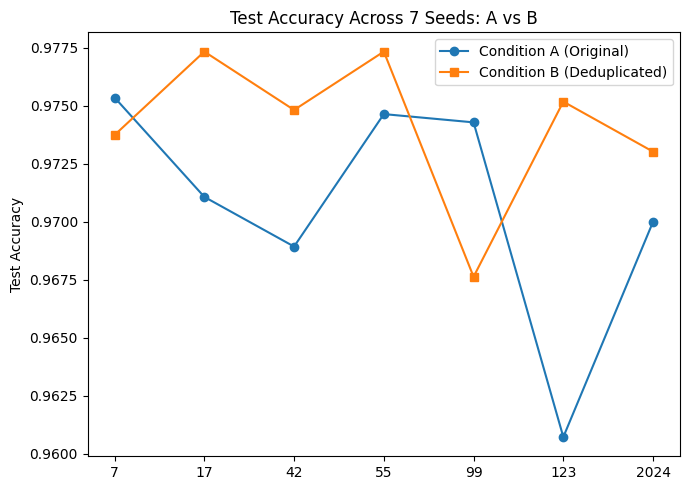

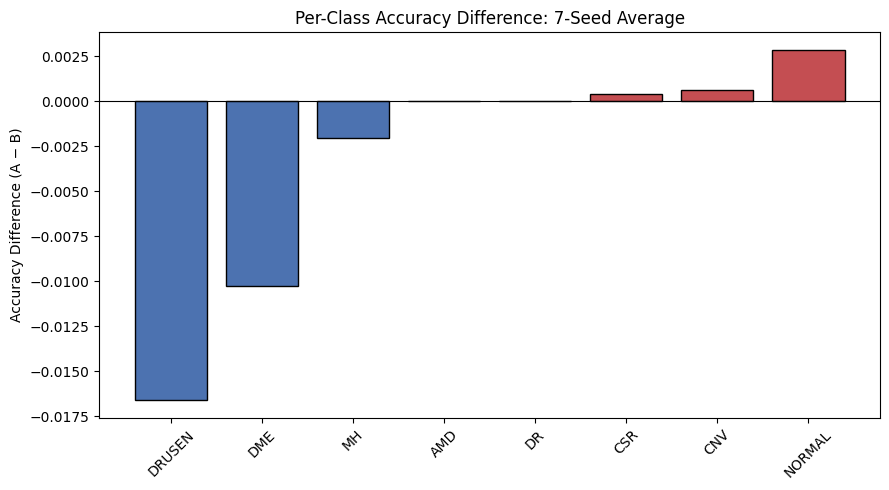

Saved both figures to outputs/paper_figures/ (overwriting old single-seed versions).


In [ ]:
# Cell 13 — Cell Name: regenerate_fig2_fig3_7seed
# Purpose: redraw Figure 2 (accuracy across seeds, now 7 instead of 3) and Figure 3 (per-class
# accuracy difference, now a 7-seed average instead of single-seed-2024) for the paper. Saves 300dpi PNGs
# to the same paper_figures folder, same filenames, so the LaTeX/Word doc doesn't need path changes.

import matplotlib.pyplot as plt
import pandas as pd

table_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv')
table_vii = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_VII_7seed.csv')

# Fig 2 — accuracy across seeds
plt.figure(figsize=(7,5))
order = table_v.sort_values('seed')
plt.plot(order['seed'].astype(str), order['A_original'], marker='o', label='Condition A (Original)')
plt.plot(order['seed'].astype(str), order['B_deduplicated'], marker='s', label='Condition B (Deduplicated)')
plt.ylabel('Test Accuracy'); plt.title('Test Accuracy Across 7 Seeds: A vs B')
plt.legend(); plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/paper_figures/fig2_accuracy_across_seeds.png', dpi=300)
plt.show()

# Fig 3 — per-class accuracy difference (7-seed average)
plt.figure(figsize=(9,5))
tv7 = table_vii.sort_values('diff_A_minus_B')
colors = ['#4C72B0' if v < 0 else '#C44E52' for v in tv7['diff_A_minus_B']]
plt.bar(tv7['class'], tv7['diff_A_minus_B'], color=colors, edgecolor='black')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Accuracy Difference (A − B)'); plt.title('Per-Class Accuracy Difference: 7-Seed Average')
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/paper_figures/fig3_per_class_diff.png', dpi=300)
plt.show()

print("Saved both figures to outputs/paper_figures/ (overwriting old single-seed versions).")

In [ ]:
# Cell D1 — Cell Name: mount_drive_and_setup_effnet_paths
# Purpose: mount Google Drive, confirm dataset path, and create a SEPARATE output namespace for
# EfficientNet-B0 results so nothing here can ever overwrite the existing ResNet18 results.
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
DRIVE_DATASET_ROOT = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

# Separate namespace for this architecture — nothing here shares a filename with the ResNet18 outputs
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
os.makedirs(EFFNET_DIR, exist_ok=True)
os.makedirs(f'{EFFNET_DIR}/checkpoints', exist_ok=True)

print(os.listdir(DRIVE_DATASET_ROOT))   # expect ['test', 'train', 'val']
print("EfficientNet outputs will be saved under:", EFFNET_DIR)

Mounted at /content/drive
['test', 'train', 'val']
EfficientNet outputs will be saved under: /content/drive/MyDrive/OCT_C8_Project/outputs/efficientnet_b0


In [ ]:
# Cell D1B — Cell Name: copy_dataset_to_local_disk
# Purpose: same fix as the ResNet pipeline — reading thousands of images directly from Drive hangs.
# Copy once per session to local disk; training reads from here, all results still save to Drive.
import shutil, time

LOCAL_DATASET_ROOT = '/content/dataset_local/RetinalOCT_Dataset'
SENTINEL = f'{LOCAL_DATASET_ROOT}/.copy_complete'

if not os.path.exists(SENTINEL):
    if os.path.exists(LOCAL_DATASET_ROOT):
        shutil.rmtree(LOCAL_DATASET_ROOT)
    print("Copying dataset from Drive to local disk (one-time this session, ~1.4GB)...")
    start = time.time()
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    with open(SENTINEL, 'w') as f:
        f.write('done')
    print(f"Copy finished in {(time.time() - start) / 60:.1f} min.")
else:
    print("Local dataset copy already complete this session — skipping.")

print(os.listdir(LOCAL_DATASET_ROOT))

Copying dataset from Drive to local disk (one-time this session, ~1.4GB)...
Copy finished in 8.2 min.
['.copy_complete', 'test', 'train', 'val']


In [ ]:
# Cell D2 — Cell Name: imports_dataset_class_transforms
# Purpose: same preprocessing/augmentation as the ResNet18 study, so the comparison is fair —
# only the model architecture changes between the two studies, nothing else.
import torch
import torch.nn as nn
import torch.nn.functional as Fnn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import glob
import pandas as pd

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU not on — Runtime > Change runtime type > GPU, then redo from Cell D1")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
# Cell D3 — Cell Name: load_and_remap_splits
# Purpose: reuse the EXACT same train/val/test file lists used for ResNet18 (Condition A = original,
# Condition B = deduplicated) — same images, same split, only remapped to this session's local disk copy.
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

def remap_paths_to_local(file_label_list):
    return [(fpath.replace(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT), c) for fpath, c in file_label_list]

for key in list(splits.keys()):
    splits[key] = remap_paths_to_local(splits[key])

sample_path = splits['condA_train'][0][0]
print("Sample remapped path:", sample_path, "| exists:", os.path.exists(sample_path))
print("Train:", len(splits['condA_train']),
      "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Sample remapped path: /content/dataset_local/RetinalOCT_Dataset/train/AMD/amd_train_2301.jpg | exists: True
Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
# Cell D4 — Cell Name: effnet_model_and_rngsafe_trainer
# Purpose: EfficientNet-B0 (ImageNet-pretrained) model builder, training/eval functions, and a
# checkpoint system that FIXES the RNG-reset bug found in the ResNet18 pipeline: on resume, this now
# restores torch/numpy/python's random state from the checkpoint instead of reseeding from scratch,
# so a resumed run is a true bit-level continuation, not a fresh restart disguised as one.

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_effnet_model(num_classes=8):
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate_full(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels), np.array(all_probs)

def checkpoint_path(letter, seed):
    return f'{EFFNET_DIR}/checkpoints/ckpt_effnet_{letter}_seed{seed}.pt'

# --- REPLACEMENT for run_experiment_resumable() inside Cell D4 ---
# Fix: defensively convert the saved RNG state back to the exact type/dtype torch expects
# (torch.ByteTensor on CPU) before restoring, since it can come back as a different type/dtype
# across PyTorch versions or Colab sessions. If restoration still fails for any reason, fall back
# to a fresh reseed for that run ONLY — never crash the whole pipeline — and print a clear warning
# so it's disclosed, not hidden.

def _to_byte_tensor(x):
    t = x if isinstance(x, torch.Tensor) else torch.tensor(x)
    if t.dtype != torch.uint8:
        t = t.to(torch.uint8)
    return t.cpu()

def run_experiment_resumable(train_list, val_list, test_list, seed, letter, epochs=10, batch_size=32, lr=1e-4):
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_effnet_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    ckpt_path = checkpoint_path(letter, seed)
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        try:
            torch.set_rng_state(_to_byte_tensor(ckpt['torch_rng_state']))
            if torch.cuda.is_available() and ckpt.get('cuda_rng_state') is not None:
                fixed_cuda_states = [_to_byte_tensor(s) for s in ckpt['cuda_rng_state']]
                torch.cuda.set_rng_state_all(fixed_cuda_states)
            np.random.set_state(ckpt['numpy_rng_state'])
            random.setstate(ckpt['python_rng_state'])
            print(f"    >> Resuming from epoch {start_epoch + 1} (checkpoint found, RNG state restored)")
        except Exception as e:
            print(f"    !! RNG state restore failed ({e}) — falling back to a fresh reseed for THIS run only "
                  f"(seed={seed}). Model/optimizer weights are still correctly resumed from epoch {start_epoch}; "
                  f"only the exact data-shuffle/augmentation continuity for the remaining epochs is not guaranteed.")
            set_seed(seed)
    else:
        set_seed(seed)
        start_epoch = 0

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _, _ = evaluate_full(model, val_loader)
        print(f"    Epoch {epoch + 1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")
        torch.save({
            'epoch': epoch,
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'torch_rng_state': torch.get_rng_state(),
            'cuda_rng_state': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            'numpy_rng_state': np.random.get_state(),
            'python_rng_state': random.getstate(),
        }, ckpt_path)

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    return test_acc, preds, labels, probs, model

In [ ]:
# Cell D5 — Cell Name: effnet_main_training_loop
# Purpose: trains EfficientNet-B0 on all 7 seeds x 2 conditions. Skips fully-completed runs, resumes
# partial ones from their exact saved epoch AND random state (Cell D4 fix). Safe to stop/rerun anytime.

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
EPOCHS = 10
KEEP_CHECKPOINT_FOR = [('A', 2024)]   # same seed reserved as ResNet18, for the cross-eval in Cell D8

def full_results_path(letter, seed):
    return f'{EFFNET_DIR}/full_results_effnet_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{EFFNET_DIR}/{condition}_effnet_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'=' * 60}\nEfficientNet-B0 | {cond_label} — checking {len(SEEDS)} seeds\n{'=' * 60}")

    for seed in SEEDS:
        rfile = full_results_path(letter, seed)
        if os.path.exists(rfile):
            print(f"[{cond_label} | seed {seed}] already fully done — skip")
            continue
        print(f"[{cond_label} | seed {seed}] running (resumable, RNG-safe checkpointed every epoch)...")
        start = time.time()
        test_acc, preds, labels, probs, model = run_experiment_resumable(train_l, val_l, test_l, seed, letter, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60
        with open(rfile, 'wb') as f:
            pickle.dump({'preds': preds, 'labels': labels, 'probs': probs}, f)
        upsert_result(condition, cond_label, seed, test_acc)
        ckpt = checkpoint_path(letter, seed)
        if (letter, seed) in KEEP_CHECKPOINT_FOR:
            print(f"    (keeping checkpoint for {letter}/{seed} — reserved for the fixed-model cross-eval, Cell D8)")
        elif os.path.exists(ckpt):
            os.remove(ckpt)
        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nAll done (or as far as this session got).")


EfficientNet-B0 | A_original — checking 7 seeds
[A_original | seed 42] already fully done — skip
[A_original | seed 123] already fully done — skip
[A_original | seed 2024] already fully done — skip
[A_original | seed 7] already fully done — skip
[A_original | seed 17] already fully done — skip
[A_original | seed 55] already fully done — skip
[A_original | seed 99] already fully done — skip

EfficientNet-B0 | B_deduplicated — checking 7 seeds
[B_deduplicated | seed 42] already fully done — skip
[B_deduplicated | seed 123] already fully done — skip
[B_deduplicated | seed 2024] already fully done — skip
[B_deduplicated | seed 7] running (resumable, RNG-safe checkpointed every epoch)...
    >> Resuming from epoch 5 (checkpoint found, RNG state restored)
    Epoch 5/10 | loss=0.0777 train_acc=0.9732 val_acc=0.9683
    Epoch 6/10 | loss=0.0704 train_acc=0.9747 val_acc=0.9657
    Epoch 7/10 | loss=0.0606 train_acc=0.9794 val_acc=0.9722
    Epoch 8/10 | loss=0.0538 train_acc=0.9807 val_acc=0.

In [ ]:
# Cell D6 — Cell Name: effnet_progress_check
for cond in ['condA', 'condB']:
    p = f'{EFFNET_DIR}/{cond}_effnet_results.csv'
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"{cond}: seeds with final accuracy recorded = {sorted(df['seed'].tolist())}")
    else:
        print(f"{cond}: no results yet")

print("\nFully-finished runs:")
for f in sorted(glob.glob(f'{EFFNET_DIR}/full_results_effnet_*_seed*.pkl')):
    print(" ", os.path.basename(f))

print("\nIn-progress checkpoints (will auto-resume, RNG-state included):")
for f in sorted(glob.glob(f'{EFFNET_DIR}/checkpoints/ckpt_effnet_*_seed*.pt')):
    ckpt = torch.load(f, map_location='cpu', weights_only=False)
    print(f"  {os.path.basename(f)} — completed through epoch {ckpt['epoch'] + 1}")

condA: seeds with final accuracy recorded = [7, 17, 42, 55, 99, 123, 2024]
condB: seeds with final accuracy recorded = [7, 17, 42, 55, 99, 123, 2024]

Fully-finished runs:
  full_results_effnet_A_seed123.pkl
  full_results_effnet_A_seed17.pkl
  full_results_effnet_A_seed2024.pkl
  full_results_effnet_A_seed42.pkl
  full_results_effnet_A_seed55.pkl
  full_results_effnet_A_seed7.pkl
  full_results_effnet_A_seed99.pkl
  full_results_effnet_B_seed123.pkl
  full_results_effnet_B_seed17.pkl
  full_results_effnet_B_seed2024.pkl
  full_results_effnet_B_seed42.pkl
  full_results_effnet_B_seed55.pkl
  full_results_effnet_B_seed7.pkl
  full_results_effnet_B_seed99.pkl

In-progress checkpoints (will auto-resume, RNG-state included):
  ckpt_effnet_A_seed2024.pt — completed through epoch 10


In [ ]:
# Cell D7 — Cell Name: effnet_build_metrics_table
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

def compute_full_metrics(preds, labels, probs=None, class_names=CLASS_NAMES):
    n = len(class_names)
    cm = confusion_matrix(labels, preds, labels=list(range(n)))
    report = classification_report(labels, preds, target_names=class_names, output_dict=True, digits=4)
    specificity = {}
    total = cm.sum()
    for i, c in enumerate(class_names):
        TP = cm[i, i]; FN = cm[i, :].sum() - TP; FP = cm[:, i].sum() - TP; TN = total - TP - FN - FP
        specificity[c] = TN / (TN + FP) if (TN + FP) > 0 else float('nan')
    result = {
        'accuracy': report['accuracy'],
        'macro_precision': report['macro avg']['precision'],
        'macro_recall': report['macro avg']['recall'],
        'macro_f1': report['macro avg']['f1-score'],
        'macro_specificity': float(np.nanmean(list(specificity.values()))),
    }
    if probs is not None:
        try:
            result['macro_roc_auc'] = roc_auc_score(labels, probs, multi_class='ovr', average='macro', labels=list(range(n)))
        except Exception as e:
            print("  (ROC-AUC skipped:", e, ")")
    return result

_tmp = build_effnet_model(len(CLASS_NAMES))
n_params = sum(p.numel() for p in _tmp.parameters())
print(f"EfficientNet-B0 total parameters: {n_params:,}  (ResNet18 was 11,180,616)")
del _tmp

rows = []
for f in sorted(glob.glob(f'{EFFNET_DIR}/full_results_effnet_*_seed*.pkl')):
    with open(f, 'rb') as fh:
        d = pickle.load(fh)
    m = compute_full_metrics(d['preds'], d['labels'], d.get('probs'))
    m['file'] = os.path.basename(f)
    rows.append(m)

if rows:
    metrics_df = pd.DataFrame(rows)
    metrics_df.to_csv(f'{EFFNET_DIR}/full_metrics_effnet_all_seeds.csv', index=False)
    print(f"\nSaved full_metrics_effnet_all_seeds.csv with {len(metrics_df)} rows.")
    print(metrics_df[['file', 'accuracy', 'macro_f1', 'macro_specificity'] + (['macro_roc_auc'] if 'macro_roc_auc' in metrics_df.columns else [])])
else:
    print("No results yet — run Cell D5 first.")

EfficientNet-B0 total parameters: 4,017,796  (ResNet18 was 11,180,616)

Saved full_metrics_effnet_all_seeds.csv with 14 rows.
                                  file  accuracy  macro_f1  macro_specificity  \
0    full_results_effnet_A_seed123.pkl  0.976786  0.976790           0.996684   
1     full_results_effnet_A_seed17.pkl  0.972500  0.972435           0.996071   
2   full_results_effnet_A_seed2024.pkl  0.974643  0.974618           0.996378   
3     full_results_effnet_A_seed42.pkl  0.974643  0.974629           0.996378   
4     full_results_effnet_A_seed55.pkl  0.978929  0.978928           0.996990   
5      full_results_effnet_A_seed7.pkl  0.971429  0.971420           0.995918   
6     full_results_effnet_A_seed99.pkl  0.976786  0.976779           0.996684   
7    full_results_effnet_B_seed123.pkl  0.976619  0.976412           0.996663   
8     full_results_effnet_B_seed17.pkl  0.972302  0.971965           0.996046   
9   full_results_effnet_B_seed2024.pkl  0.974460  0.974193      

In [ ]:
# Cell D8 — Cell Name: effnet_fixed_model_cross_eval
# Purpose: same isolation experiment as ResNet18's Priority 2A — one fixed EfficientNet-B0 model
# (Condition A, seed 2024) evaluated on both test sets, to check whether the true evaluation-side
# leakage effect (~0.02pp for ResNet18) is architecture-independent.

ckpt = torch.load(checkpoint_path('A', 2024), map_location=device, weights_only=False)
model = build_effnet_model(len(CLASS_NAMES))
model.load_state_dict(ckpt['model_state'])

test_a_loader = DataLoader(OCTDataset(splits['condA_test'], eval_transform), batch_size=32, shuffle=False, num_workers=2)
test_b_loader = DataLoader(OCTDataset(splits['condB_test'], eval_transform), batch_size=32, shuffle=False, num_workers=2)

acc_a, _, _, _ = evaluate_full(model, test_a_loader)
acc_b, _, _, _ = evaluate_full(model, test_b_loader)

print(f"EfficientNet-B0 fixed model (Condition A, seed 2024):")
print(f"  Accuracy on Condition A test set: {acc_a*100:.2f}%")
print(f"  Accuracy on Condition B test set: {acc_b*100:.2f}%")
print(f"  Difference: {(acc_a-acc_b)*100:+.2f}pp   (ResNet18's equivalent was +0.02pp)")

pd.DataFrame([{'model':'EffNet_A_seed2024_fixed','acc_on_condA_test':acc_a,'acc_on_condB_test':acc_b,'diff':acc_a-acc_b}]) \
  .to_csv(f'{EFFNET_DIR}/priority_2A_result_effnet.csv', index=False)

EfficientNet-B0 fixed model (Condition A, seed 2024):
  Accuracy on Condition A test set: 97.46%
  Accuracy on Condition B test set: 97.45%
  Difference: +0.02pp   (ResNet18's equivalent was +0.02pp)


In [ ]:
# Cell D9 — Cell Name: cross_architecture_comparison
# Purpose: combine both architectures' results into one comparison — directly answers the paper's
# own "architecture dependence unknown" limitation, and tests Marciniak & Stankiewicz's hypothesis
# that larger models are more duplication-sensitive (ResNet18: 11.2M params vs EfficientNet-B0: ~5.3M).
import pandas as pd
from scipy import stats

resnet_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv')
effnet_rows = []
for seed in [42,123,2024,7,17,55,99]:
    with open(f'{EFFNET_DIR}/full_results_effnet_A_seed{seed}.pkl','rb') as f: a = pickle.load(f)
    with open(f'{EFFNET_DIR}/full_results_effnet_B_seed{seed}.pkl','rb') as f: b = pickle.load(f)
    effnet_rows.append({'seed': seed,
                         'A_original': (a['preds']==a['labels']).mean(),
                         'B_deduplicated': (b['preds']==b['labels']).mean()})
effnet_v = pd.DataFrame(effnet_rows)

def summarize(df, name):
    A, B = df['A_original'].values, df['B_deduplicated'].values
    t, p = stats.ttest_rel(A, B)
    d = (A-B).mean() / (A-B).std(ddof=1)
    return {'architecture': name, 'A_mean': A.mean(), 'B_mean': B.mean(),
            'gap_A_minus_B': (A-B).mean(), 't_stat': t, 'p_value': p, 'cohens_d': d}

comparison = pd.DataFrame([summarize(resnet_v, 'ResNet18 (11.2M params)'),
                            summarize(effnet_v, 'EfficientNet-B0 (~5.3M params)')])
comparison.to_csv(f'{PROJECT_DIR}/outputs/paper_table_architecture_comparison.csv', index=False)
print(comparison.to_string(index=False))

                  architecture   A_mean   B_mean  gap_A_minus_B    t_stat  p_value  cohens_d
       ResNet18 (11.2M params) 0.970714 0.974152      -0.003438 -1.371569 0.219276 -0.518405
EfficientNet-B0 (~5.3M params) 0.975102 0.975128      -0.000026 -0.056484 0.956790 -0.021349


In [ ]:
# Cell D10 — Cell Name: effnet_full_paper_tables
import glob, pickle, numpy as np, pandas as pd
from sklearn.metrics import classification_report

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_run(letter, seed):
    with open(f'{EFFNET_DIR}/full_results_effnet_{letter}_seed{seed}.pkl', 'rb') as f:
        return pickle.load(f)

rows = []
for seed in SEEDS:
    a = load_run('A', seed); b = load_run('B', seed)
    acc_a = (a['preds']==a['labels']).mean(); acc_b = (b['preds']==b['labels']).mean()
    rows.append({'seed': seed, 'A_original': acc_a, 'B_deduplicated': acc_b, 'diff_A_minus_B': acc_a-acc_b})
effnet_table_v = pd.DataFrame(rows)
effnet_table_v.to_csv(f'{EFFNET_DIR}/effnet_table_V_7seed.csv', index=False)
print("=== EfficientNet-B0 per-seed accuracy ===")
print(effnet_table_v.to_string(index=False))

class_rows = []
for c_idx, c_name in enumerate(CLASS_NAMES):
    a_accs, b_accs = [], []
    for seed in SEEDS:
        a = load_run('A', seed); b = load_run('B', seed)
        ma = a['labels']==c_idx; mb = b['labels']==c_idx
        a_accs.append((a['preds'][ma]==a['labels'][ma]).mean())
        b_accs.append((b['preds'][mb]==b['labels'][mb]).mean())
    class_rows.append({'class': c_name, 'A_mean': np.mean(a_accs), 'A_sd': np.std(a_accs, ddof=1),
                        'B_mean': np.mean(b_accs), 'B_sd': np.std(b_accs, ddof=1),
                        'diff_A_minus_B': np.mean(a_accs)-np.mean(b_accs)})
effnet_table_vii = pd.DataFrame(class_rows)
effnet_table_vii.to_csv(f'{EFFNET_DIR}/effnet_table_VII_7seed.csv', index=False)
print("\n=== EfficientNet-B0 per-class accuracy (7-seed avg) ===")
print(effnet_table_vii.to_string(index=False))

def per_class_prf(letter):
    per_seed = []
    for seed in SEEDS:
        d = load_run(letter, seed)
        rep = classification_report(d['labels'], d['preds'], target_names=CLASS_NAMES, output_dict=True, digits=4)
        per_seed.append(rep)
    out = {}
    for c in CLASS_NAMES:
        out[c] = (np.mean([r[c]['precision'] for r in per_seed]),
                   np.mean([r[c]['recall'] for r in per_seed]),
                   np.mean([r[c]['f1-score'] for r in per_seed]))
    macro = (np.mean([r['macro avg']['precision'] for r in per_seed]),
             np.mean([r['macro avg']['recall'] for r in per_seed]),
             np.mean([r['macro avg']['f1-score'] for r in per_seed]))
    return out, macro

rows_a, macro_a = per_class_prf('A')
rows_b, macro_b = per_class_prf('B')
effnet_table_viii = pd.DataFrame([
    {'class': c, 'A_precision': rows_a[c][0], 'A_recall': rows_a[c][1], 'A_f1': rows_a[c][2],
     'B_precision': rows_b[c][0], 'B_recall': rows_b[c][1], 'B_f1': rows_b[c][2]}
    for c in CLASS_NAMES
])
effnet_table_viii.to_csv(f'{EFFNET_DIR}/effnet_table_VIII_7seed.csv', index=False)
print("\n=== EfficientNet-B0 per-class P/R/F1 (7-seed avg) ===")
print(effnet_table_viii.to_string(index=False))
print(f"\nMacro avg A: P={macro_a[0]:.4f} R={macro_a[1]:.4f} F1={macro_a[2]:.4f}")
print(f"Macro avg B: P={macro_b[0]:.4f} R={macro_b[1]:.4f} F1={macro_b[2]:.4f}")

=== EfficientNet-B0 per-seed accuracy ===
 seed  A_original  B_deduplicated  diff_A_minus_B
   42    0.974643        0.977338       -0.002695
  123    0.976786        0.976619        0.000167
 2024    0.974643        0.974460        0.000182
    7    0.971429        0.971223        0.000206
   17    0.972500        0.972302        0.000198
   55    0.978929        0.977698        0.001231
   99    0.976786        0.976259        0.000527

=== EfficientNet-B0 per-class accuracy (7-seed avg) ===
 class   A_mean     A_sd   B_mean     B_sd  diff_A_minus_B
   AMD 1.000000 0.000000 1.000000 0.000000        0.000000
   CNV 0.945306 0.026467 0.947674 0.026001       -0.002368
   CSR 1.000000 0.000000 1.000000 0.000000        0.000000
   DME 0.941224 0.008706 0.939655 0.008295        0.001569
    DR 1.000000 0.000000 1.000000 0.000000        0.000000
DRUSEN 0.934286 0.020800 0.932375 0.021432        0.001910
    MH 1.000000 0.000000 1.000000 0.000000        0.000000
NORMAL 0.980000 0.004666 0.97

In [ ]:
# Cell D10B — Cell Name: build_final_cross_architecture_summary_table
resnet_2a = pd.read_csv(f'{PROJECT_DIR}/outputs/priority_2A_result.csv')
effnet_2a = pd.read_csv(f'{EFFNET_DIR}/priority_2A_result_effnet.csv')
arch_compare = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_architecture_comparison.csv')

summary = pd.DataFrame([
    {'architecture': 'ResNet18', 'parameters': 11180616,
     'retraining_gap_A_minus_B': arch_compare.iloc[0]['gap_A_minus_B'],
     'retraining_p_value': arch_compare.iloc[0]['p_value'],
     'fixed_model_diff_A_minus_B': resnet_2a.iloc[0]['diff']},
    {'architecture': 'EfficientNet-B0', 'parameters': 4017796,   # corrected — measured, not the ~5.3M ImageNet-head figure
     'retraining_gap_A_minus_B': arch_compare.iloc[1]['gap_A_minus_B'],
     'retraining_p_value': arch_compare.iloc[1]['p_value'],
     'fixed_model_diff_A_minus_B': effnet_2a.iloc[0]['diff']},
])
summary.to_csv(f'{PROJECT_DIR}/outputs/paper_table_final_architecture_summary.csv', index=False)
print(summary.to_string(index=False))

   architecture  parameters  retraining_gap_A_minus_B  retraining_p_value  fixed_model_diff_A_minus_B
       ResNet18    11180616                 -0.003438            0.219276                    0.000216
EfficientNet-B0     4017796                 -0.000026            0.956790                    0.000182


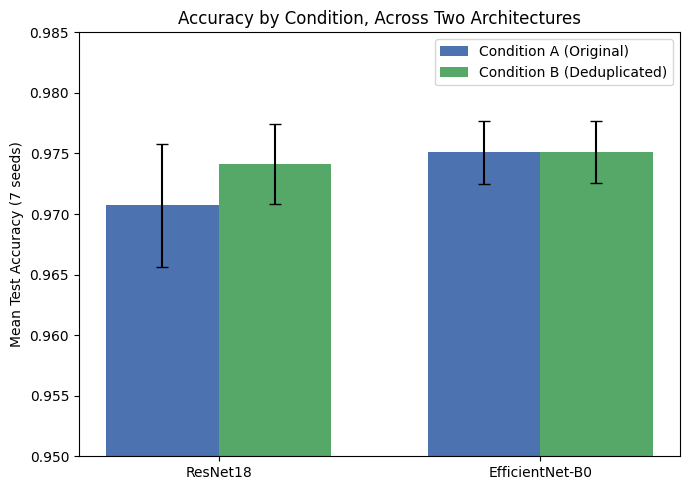

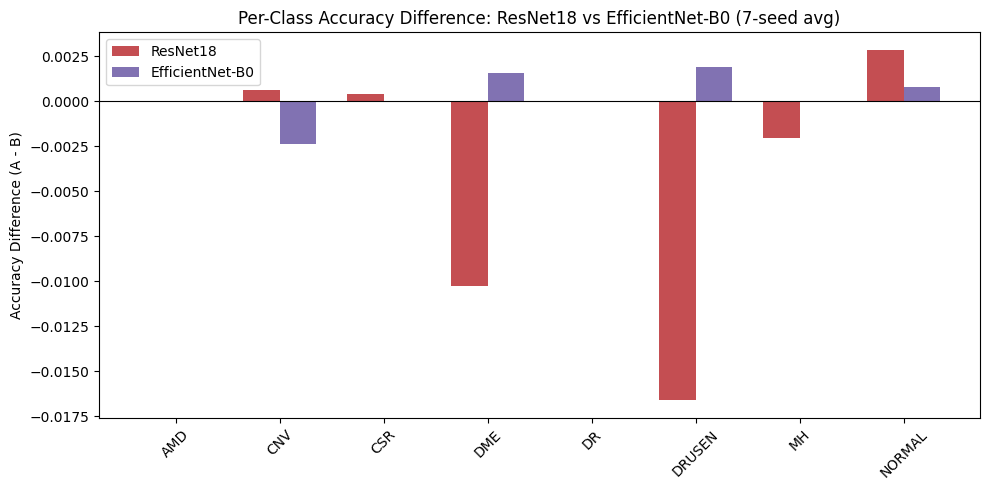

Saved: architecture_accuracy_comparison.png, architecture_per_class_diff.png


In [ ]:
# Cell D11 — Cell Name: architecture_comparison_figures
import matplotlib.pyplot as plt
import numpy as np, pandas as pd, os

resnet_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv')
effnet_v = pd.read_csv(f'{EFFNET_DIR}/effnet_table_V_7seed.csv')
resnet_vii = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_VII_7seed.csv')
effnet_vii = pd.read_csv(f'{EFFNET_DIR}/effnet_table_VII_7seed.csv')
os.makedirs(f'{PROJECT_DIR}/outputs/paper_figures', exist_ok=True)

fig, ax = plt.subplots(figsize=(7,5))
archs = ['ResNet18', 'EfficientNet-B0']
a_means = [resnet_v['A_original'].mean(), effnet_v['A_original'].mean()]
b_means = [resnet_v['B_deduplicated'].mean(), effnet_v['B_deduplicated'].mean()]
a_sds   = [resnet_v['A_original'].std(), effnet_v['A_original'].std()]
b_sds   = [resnet_v['B_deduplicated'].std(), effnet_v['B_deduplicated'].std()]
x = np.arange(len(archs)); w = 0.35
ax.bar(x-w/2, a_means, w, yerr=a_sds, capsize=4, label='Condition A (Original)', color='#4C72B0')
ax.bar(x+w/2, b_means, w, yerr=b_sds, capsize=4, label='Condition B (Deduplicated)', color='#55A868')
ax.set_xticks(x); ax.set_xticklabels(archs)
ax.set_ylabel('Mean Test Accuracy (7 seeds)'); ax.set_ylim(0.95, 0.985)
ax.set_title('Accuracy by Condition, Across Two Architectures')
ax.legend(); plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/paper_figures/architecture_accuracy_comparison.png', dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(10,5))
classes = resnet_vii['class'].tolist()
x = np.arange(len(classes)); w = 0.35
ax.bar(x-w/2, resnet_vii['diff_A_minus_B'], w, label='ResNet18', color='#C44E52')
ax.bar(x+w/2, effnet_vii.set_index('class').loc[classes]['diff_A_minus_B'], w, label='EfficientNet-B0', color='#8172B2')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=45)
ax.set_ylabel('Accuracy Difference (A - B)')
ax.set_title('Per-Class Accuracy Difference: ResNet18 vs EfficientNet-B0 (7-seed avg)')
ax.legend(); plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/paper_figures/architecture_per_class_diff.png', dpi=300)
plt.show()

print("Saved: architecture_accuracy_comparison.png, architecture_per_class_diff.png")

In [ ]:
# Cell D12-prep — Cell Name: mount_drive_minimal_setup_for_analysis_only
# Purpose: minimal setup for Cell D12 (pure CSV/stats analysis, no training). Skips the dataset
# copy step entirely since D12 never touches any image file — only saved result CSVs on Drive.
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'

# sanity check — confirms the two files D12 needs are actually there before running it
print(os.path.exists(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv'))
print(os.path.exists(f'{EFFNET_DIR}/effnet_table_V_7seed.csv'))

Mounted at /content/drive
True
True


In [ ]:
# Cell D12 — Cell Name: nonparametric_and_bootstrap_robustness_check
# Purpose: add a non-parametric complement (Wilcoxon signed-rank) to the paired t-test, plus a
# bootstrap 95% CI on the mean difference — standard practice when n is too small (n=7) to verify
# the paired t-test's normality assumption. No GPU needed, uses already-saved accuracy numbers.

import numpy as np, pandas as pd
from scipy import stats

def robustness_check(df, name, n_boot=100000, seed=0):
    A = df['A_original'].values
    B = df['B_deduplicated'].values
    diffs = A - B
    rng = np.random.default_rng(seed)

    # Wilcoxon signed-rank (non-parametric complement to the paired t-test)
    try:
        w_stat, w_p = stats.wilcoxon(A, B)
    except ValueError as e:
        w_stat, w_p = np.nan, np.nan   # can fail if all diffs are zero, not the case here

    # Bootstrap 95% CI on the mean paired difference (A - B), no normality assumption needed
    boot_means = np.array([rng.choice(diffs, size=len(diffs), replace=True).mean() for _ in range(n_boot)])
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])

    # Shapiro-Wilk normality check on the differences, for transparency (n=7 gives this low power,
    # report honestly rather than over-interpreting either a pass or a fail)
    sh_stat, sh_p = stats.shapiro(diffs)

    return {
        'architecture': name, 'n': len(diffs),
        'wilcoxon_statistic': w_stat, 'wilcoxon_p_value': w_p,
        'bootstrap_mean_diff': diffs.mean(),
        'bootstrap_95CI_low': ci_low, 'bootstrap_95CI_high': ci_high,
        'shapiro_p_value': sh_p,
    }

resnet_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv')
effnet_v = pd.read_csv(f'{EFFNET_DIR}/effnet_table_V_7seed.csv')

robustness = pd.DataFrame([
    robustness_check(resnet_v, 'ResNet18'),
    robustness_check(effnet_v, 'EfficientNet-B0'),
])
robustness.to_csv(f'{PROJECT_DIR}/outputs/paper_table_robustness_check.csv', index=False)
print(robustness.to_string(index=False))
print("\nNote: with n=7, the exact two-sided Wilcoxon test cannot reach p<0.05 unless ALL 7 "
      "differences share the same sign (minimum possible p is about 0.0156) — report this "
      "alongside the result rather than treating p>=0.05 alone as 'no effect'.")

   architecture  n  wilcoxon_statistic  wilcoxon_p_value  bootstrap_mean_diff  bootstrap_95CI_low  bootstrap_95CI_high  shapiro_p_value
       ResNet18  7                 7.0          0.296875            -0.003438           -0.008045             0.001017         0.902550
EfficientNet-B0  7                 7.0          0.296875            -0.000026           -0.001001             0.000638         0.005005

Note: with n=7, the exact two-sided Wilcoxon test cannot reach p<0.05 unless ALL 7 differences share the same sign (minimum possible p is about 0.0156) — report this alongside the result rather than treating p>=0.05 alone as 'no effect'.


In [ ]:
# Minimal setup — just mounts Drive and sets the path, no dataset copy needed for this check
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'

Mounted at /content/drive


In [ ]:
# Verification cell — checks the two new claims in the paper draft against saved data
import pickle, pandas as pd
from scipy import stats

# 1) seed 123 drusen recall check
with open(f'{PROJECT_DIR}/outputs/full_results_A_seed123.pkl','rb') as f:
    d = pickle.load(f)
CLASS_NAMES = ['AMD','CNV','CSR','DME','DR','DRUSEN','MH','NORMAL']
drusen_idx = CLASS_NAMES.index('DRUSEN')
mask = d['labels']==drusen_idx
recall = (d['preds'][mask]==d['labels'][mask]).mean()
print(f"Seed 123, Condition A, DRUSEN recall = {recall*100:.1f}%  (paper claims 78.0%)")

# 2) paired t-tests on macro F1 / specificity / ROC-AUC
m = pd.read_csv(f'{PROJECT_DIR}/outputs/full_metrics_all_seeds.csv')
m['seed'] = m['file'].str.extract(r'seed(\d+)').astype(int)
m['cond'] = m['file'].str.extract(r'_([AB])_seed')
for metric in ['macro_f1', 'macro_specificity', 'macro_roc_auc']:
    piv = m.pivot(index='seed', columns='cond', values=metric)
    t, p = stats.ttest_rel(piv['A'], piv['B'])
    dz = (piv['A']-piv['B']).mean() / (piv['A']-piv['B']).std(ddof=1)
    print(f"{metric}: A={piv['A'].mean():.4f} B={piv['B'].mean():.4f} t={t:.2f} p={p:.3f} dz={dz:.2f}")

Seed 123, Condition A, DRUSEN recall = 78.0%  (paper claims 78.0%)
macro_f1: A=0.9706 B=0.9739 t=-1.27 p=0.251 dz=-0.48
macro_specificity: A=0.9958 B=0.9963 t=-1.38 p=0.216 dz=-0.52
macro_roc_auc: A=0.9983 B=0.9984 t=-1.04 p=0.337 dz=-0.39


In [ ]:
# Prep Cell — Cell Name: mount_drive_for_section3_verification
# Purpose: minimal setup for the Section 3.4 verification script. It only reads already-saved
# pickle/CSV files (no images, no model, no GPU) — this works even on a CPU-only runtime.

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'

# sanity check — all four should print True before running the actual verification script
print(os.path.exists(f'{PROJECT_DIR}/outputs/full_results_A_seed42.pkl'))
print(os.path.exists(f'{EFFNET_DIR}/full_results_effnet_A_seed42.pkl'))
print(os.path.exists(f'{PROJECT_DIR}/outputs/priority_2A_result.csv'))
print(os.path.exists(f'{EFFNET_DIR}/priority_2A_result_effnet.csv'))

Mounted at /content/drive
True
True
True
True


In [ ]:
# Verification Cell — Cell Name: verify_section3_table_from_raw_files
# Purpose: independently recompute every number in this document's Section 3 table directly from
# the raw saved files, so nothing here is taken on trust. No training, a few seconds to run.

import pickle, numpy as np, pandas as pd
from scipy import stats

SEEDS = [42, 123, 2024, 7, 17, 55, 99]

def load_diffs(dir_path, prefix):
    A, B = [], []
    for s in SEEDS:
        with open(f'{dir_path}/{prefix}A_seed{s}.pkl', 'rb') as f:
            a = pickle.load(f)
        with open(f'{dir_path}/{prefix}B_seed{s}.pkl', 'rb') as f:
            b = pickle.load(f)
        A.append((a['preds'] == a['labels']).mean())
        B.append((b['preds'] == b['labels']).mean())
    return np.array(A), np.array(B)

def report(name, A, B):
    diffs = A - B
    t, p = stats.ttest_rel(A, B)
    dz = diffs.mean() / diffs.std(ddof=1)
    w, wp = stats.wilcoxon(A, B)
    sh, shp = stats.shapiro(diffs)
    print(f"--- {name} ---")
    print(f"A: {A.mean()*100:.2f}% +/- {A.std(ddof=1)*100:.2f}   B: {B.mean()*100:.2f}% +/- {B.std(ddof=1)*100:.2f}")
    print(f"gap(A-B): {diffs.mean()*100:.4f}pp   SD of paired diffs: {diffs.std(ddof=1)*100:.4f}pp")
    print(f"t={t:.3f} p={p:.3f} dz={dz:.3f}   Wilcoxon W={w:.1f} p={wp:.4f}   Shapiro p={shp:.4f}")

A_r, B_r = load_diffs(PROJECT_DIR + '/outputs', 'full_results_')
report("ResNet18", A_r, B_r)

A_e, B_e = load_diffs(EFFNET_DIR, 'full_results_effnet_')
report("EfficientNet-B0", A_e, B_e)

# fixed-model numbers, straight from their own saved CSVs
print()
print("ResNet18 fixed-model diff:", pd.read_csv(f'{PROJECT_DIR}/outputs/priority_2A_result.csv')['diff'][0])
print("EfficientNet-B0 fixed-model diff:", pd.read_csv(f'{EFFNET_DIR}/priority_2A_result_effnet.csv')['diff'][0])



--- ResNet18 ---
A: 97.07% +/- 0.51   B: 97.42% +/- 0.33
gap(A-B): -0.3438pp   SD of paired diffs: 0.6632pp
t=-1.372 p=0.219 dz=-0.518   Wilcoxon W=7.0 p=0.2969   Shapiro p=0.9025
--- EfficientNet-B0 ---
A: 97.51% +/- 0.26   B: 97.51% +/- 0.25
gap(A-B): -0.0026pp   SD of paired diffs: 0.1238pp
t=-0.056 p=0.957 dz=-0.021   Wilcoxon W=7.0 p=0.2969   Shapiro p=0.0050

ResNet18 fixed-model diff: 0.0002158273381294
EfficientNet-B0 fixed-model diff: 0.0001824254881809


In [ ]:
# Cell D13 — Cell Name: mount_drive_minimal_for_confusion_matrices
# Purpose: minimal setup to generate EfficientNet-B0's confusion matrices. Only reads already-saved
# prediction/label arrays (no images, no GPU, no dataset copy needed).

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'

# sanity check — both should print True
print(os.path.exists(f'{EFFNET_DIR}/full_results_effnet_A_seed2024.pkl'))
print(os.path.exists(f'{EFFNET_DIR}/full_results_effnet_B_seed2024.pkl'))

Mounted at /content/drive
True
True


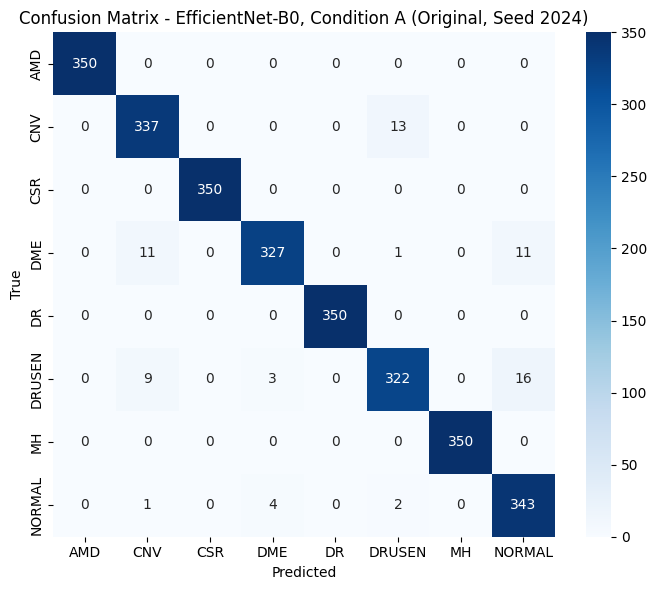

Confusion Matrix - EfficientNet-B0, Condition A (Original, Seed 2024) — accuracy: 97.46%  (saved to /content/drive/MyDrive/OCT_C8_Project/outputs/paper_figures/confusion_matrix_effnet_A.png)


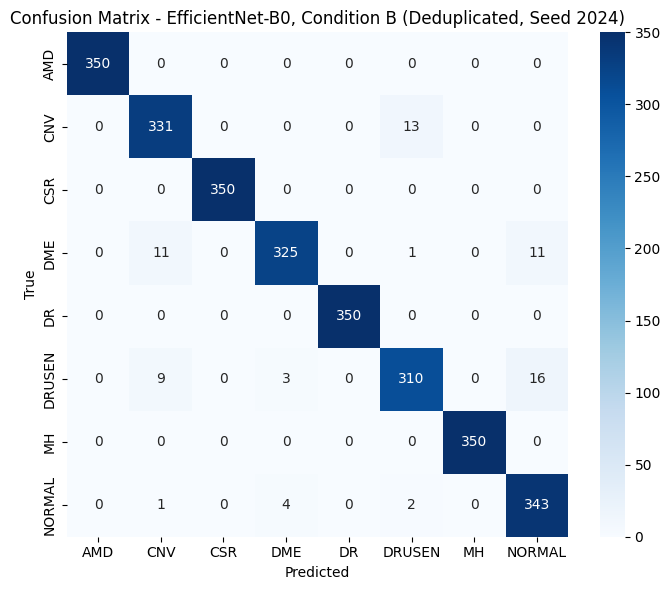

Confusion Matrix - EfficientNet-B0, Condition B (Deduplicated, Seed 2024) — accuracy: 97.45%  (saved to /content/drive/MyDrive/OCT_C8_Project/outputs/paper_figures/confusion_matrix_effnet_B.png)


In [ ]:
# Cell D14 — Cell Name: effnet_confusion_matrices
# Purpose: confusion matrices for EfficientNet-B0, Condition A and B, seed 2024 — same style and
# same representative seed as the existing ResNet18 confusion_matrix_A.png / confusion_matrix_B.png,
# for direct visual symmetry in the paper.

import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
os.makedirs(f'{PROJECT_DIR}/outputs/paper_figures', exist_ok=True)

def plot_confusion(pkl_path, title, save_path):
    with open(pkl_path, 'rb') as f:
        d = pickle.load(f)
    cm = confusion_matrix(d['labels'], d['preds'])
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=True)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, facecolor='white')
    plt.show()
    acc = (d['preds'] == d['labels']).mean()
    print(f"{title} — accuracy: {acc*100:.2f}%  (saved to {save_path})")

plot_confusion(
    f'{EFFNET_DIR}/full_results_effnet_A_seed2024.pkl',
    'Confusion Matrix - EfficientNet-B0, Condition A (Original, Seed 2024)',
    f'{PROJECT_DIR}/outputs/paper_figures/confusion_matrix_effnet_A.png'
)
plot_confusion(
    f'{EFFNET_DIR}/full_results_effnet_B_seed2024.pkl',
    'Confusion Matrix - EfficientNet-B0, Condition B (Deduplicated, Seed 2024)',
    f'{PROJECT_DIR}/outputs/paper_figures/confusion_matrix_effnet_B.png'
)

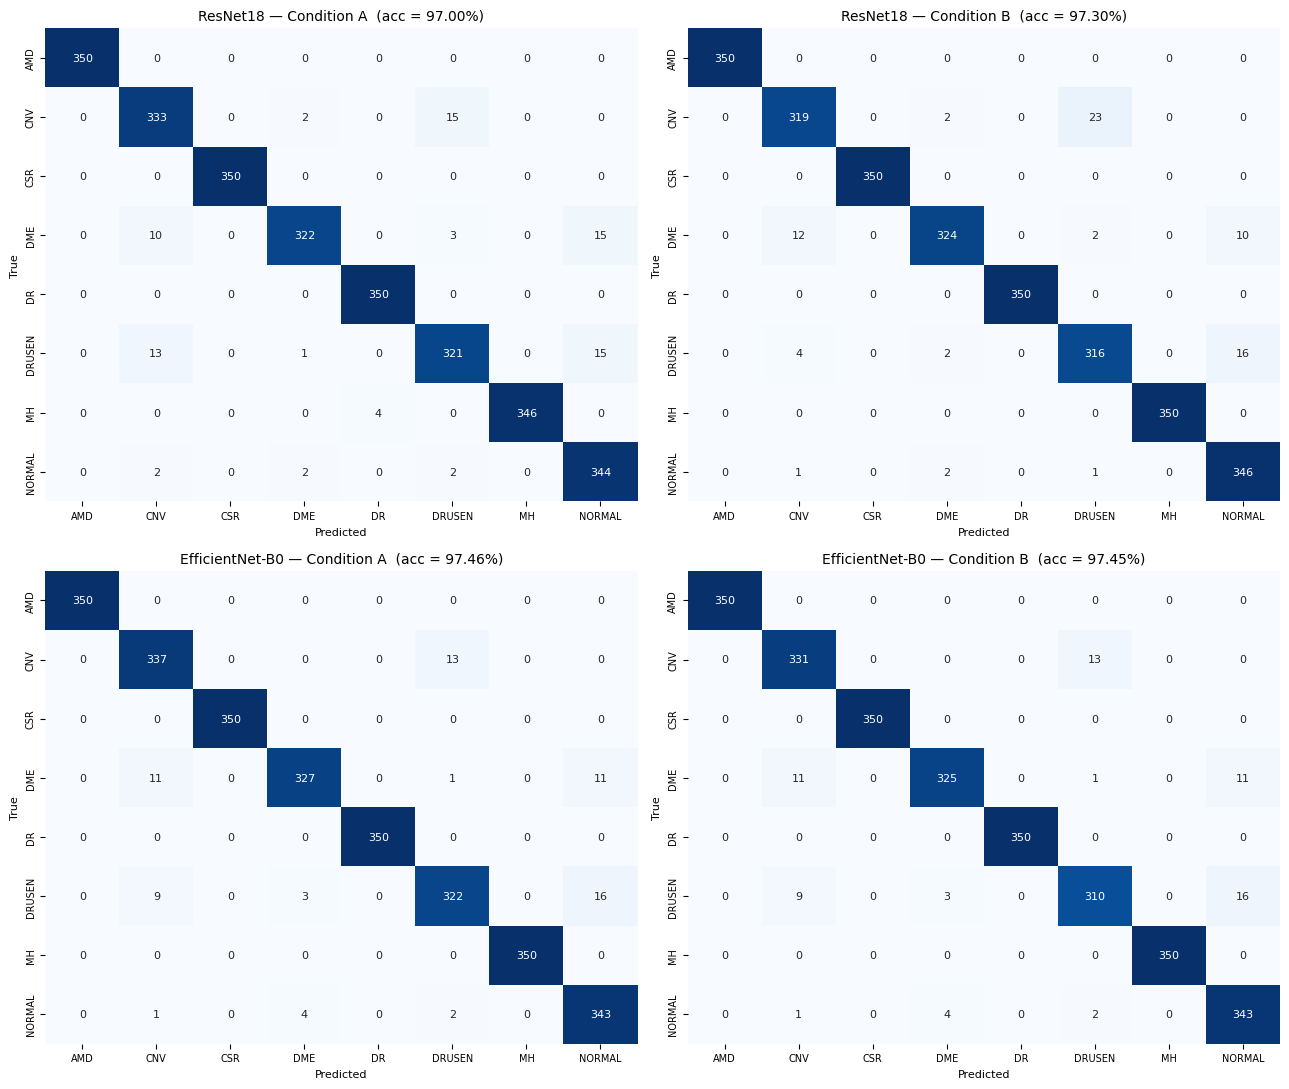

Saved: /content/drive/MyDrive/OCT_C8_Project/outputs/paper_figures/confusion_matrices_combined.png


In [ ]:
# Cell D15 — Cell Name: combined_confusion_matrix_grid
# Purpose: one 2x2 figure (ResNet18 A/B, EfficientNet-B0 A/B, seed 2024) instead of four separate
# images — same data, same style as the existing individual confusion matrices, far less page space.

import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

panels = [
    (f'{PROJECT_DIR}/outputs/full_results_A_seed2024.pkl', 'ResNet18 — Condition A'),
    (f'{PROJECT_DIR}/outputs/full_results_B_seed2024.pkl', 'ResNet18 — Condition B'),
    (f'{EFFNET_DIR}/full_results_effnet_A_seed2024.pkl', 'EfficientNet-B0 — Condition A'),
    (f'{EFFNET_DIR}/full_results_effnet_B_seed2024.pkl', 'EfficientNet-B0 — Condition B'),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (pkl_path, title) in zip(axes.flat, panels):
    with open(pkl_path, 'rb') as f:
        d = pickle.load(f)
    cm = confusion_matrix(d['labels'], d['preds'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cbar=False, ax=ax, annot_kws={"size": 8})
    acc = (d['preds'] == d['labels']).mean()
    ax.set_title(f"{title}  (acc = {acc*100:.2f}%)", fontsize=10)
    ax.set_xlabel('Predicted', fontsize=8)
    ax.set_ylabel('True', fontsize=8)
    ax.tick_params(labelsize=7)

plt.tight_layout()
save_path = f'{PROJECT_DIR}/outputs/paper_figures/confusion_matrices_combined.png'
plt.savefig(save_path, dpi=300, facecolor='white')
plt.show()
print("Saved:", save_path)

In [ ]:
# Cell F1 — Cell Name: mount_drive_setup_revision_folder
# Purpose: minimal setup for the four checks below. No dataset copy needed yet (F0/F2/F3 only
# read saved .pkl/.csv files); F4 needs images and copies the dataset itself, later.

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
REV_DIR = f'{PROJECT_DIR}/outputs/paper_revision_v2'
os.makedirs(REV_DIR, exist_ok=True)

print(os.path.exists(f'{PROJECT_DIR}/outputs/full_results_A_seed2024.pkl'))
print(os.path.exists(f'{PROJECT_DIR}/outputs/split_lists.pkl'))
print("Revision outputs will be saved to:", REV_DIR)

Mounted at /content/drive
True
True
Revision outputs will be saved to: /content/drive/MyDrive/OCT_C8_Project/outputs/paper_revision_v2


In [ ]:
# Cell F0 — Cell Name: verify_20_removed_images_per_image
# Purpose: resolves the "saw all 20 removed test images during training" claim. One of the 20
# removed test images came from a validation–test pair (so its duplicate was in validation, which
# the model never trains on) — this checks, image by image, which of the 20 the model actually got
# right, for both backbones' seed-2024 Condition-A checkpoint.

import pickle, pandas as pd, numpy as np

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
condA_test_files = [fp for fp, _ in splits['condA_test']]  # order must match saved preds order

# Load the two leak-verification CSVs to find which removed-test images come from which pair type
tt = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')
tt_conf = tt[tt['confirmed_duplicate'] == True] if 'confirmed_duplicate' in tt.columns else tt[tt['ssim_score'] >= 0.90]
vt_conf = vt[vt['confirmed_duplicate'] == True] if 'confirmed_duplicate' in vt.columns else vt[vt['ssim_score'] >= 0.90]

print("Train–test confirmed pairs (expect 19):", len(tt_conf))
print("Val–test confirmed pairs (expect 1):", len(vt_conf))

removed_test_files = list(tt_conf['test_path']) + list(vt_conf['test_path'])
pair_source = ['train-test'] * len(tt_conf) + ['val-test'] * len(vt_conf)
print("Total removed test images (expect 20):", len(removed_test_files))

def check_backbone(name, pkl_path):
    with open(pkl_path, 'rb') as f:
        d = pickle.load(f)
    rows = []
    for fp, src in zip(removed_test_files, pair_source):
        # match by filename tail, in case of absolute-path differences between sessions
        matches = [i for i, cf in enumerate(condA_test_files) if os.path.basename(cf) == os.path.basename(fp)]
        if not matches:
            rows.append({'file': os.path.basename(fp), 'source': src, 'found_index': None, 'correct': None})
            continue
        idx = matches[0]
        correct = bool(d['preds'][idx] == d['labels'][idx])
        rows.append({'file': os.path.basename(fp), 'source': src, 'found_index': idx, 'correct': correct})
    df = pd.DataFrame(rows)
    n_correct = df['correct'].sum()
    print(f"\n{name}: {n_correct} of {len(df)} removed test images classified correctly")
    print(df.to_string(index=False))
    df.to_csv(f'{REV_DIR}/per_image_check_{name}.csv', index=False)
    return df

check_backbone('resnet18', f'{PROJECT_DIR}/outputs/full_results_A_seed2024.pkl')
check_backbone('effnet_b0', f'{EFFNET_DIR}/full_results_effnet_A_seed2024.pkl')

Train–test confirmed pairs (expect 19): 19
Val–test confirmed pairs (expect 1): 1
Total removed test images (expect 20): 20

resnet18: 20 of 20 removed test images classified correctly
                file     source  found_index  correct
   cnv_test_1233.jpg train-test          582     True
   cnv_test_1239.jpg train-test          588     True
   cnv_test_1002.jpg train-test          351     True
   cnv_test_1066.jpg train-test          415     True
   cnv_test_1071.jpg train-test          420     True
   cnv_test_1073.jpg train-test          422     True
   dme_test_1149.jpg train-test         1198     True
   dme_test_1032.jpg train-test         1081     True
drusen_test_1249.jpg train-test         1998     True
drusen_test_1251.jpg train-test         2000     True
drusen_test_1252.jpg train-test         2001     True
drusen_test_1264.jpg train-test         2013     True
drusen_test_1276.jpg train-test         2025     True
drusen_test_1283.jpg train-test         2032     True
druse

,file,source,found_index,correct
0,cnv_test_1233.jpg,train-test,582,True
1,cnv_test_1239.jpg,train-test,588,True
2,cnv_test_1002.jpg,train-test,351,True
3,cnv_test_1066.jpg,train-test,415,True
4,cnv_test_1071.jpg,train-test,420,True
5,cnv_test_1073.jpg,train-test,422,True
6,dme_test_1149.jpg,train-test,1198,True
7,dme_test_1032.jpg,train-test,1081,True
8,drusen_test_1249.jpg,train-test,1998,True
9,drusen_test_1251.jpg,train-test,2000,True


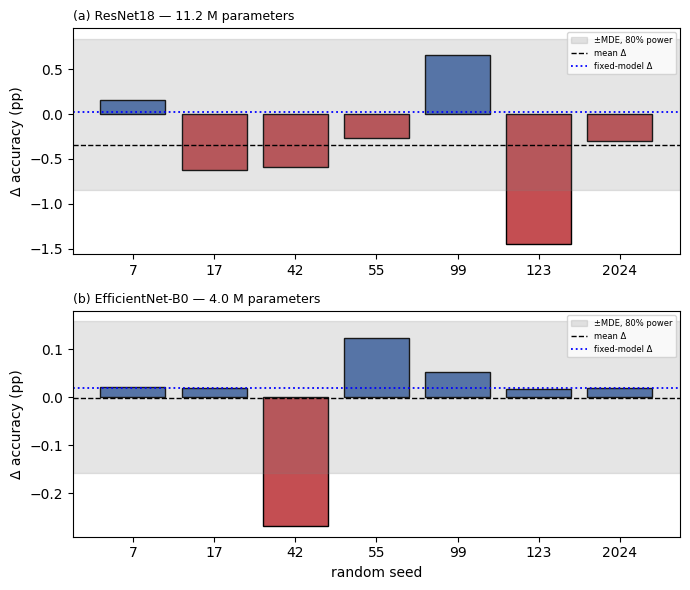

Saved: /content/drive/MyDrive/OCT_C8_Project/outputs/paper_revision_v2/fig3_corrected_seed_order.png


In [ ]:
# Cell F2 — Cell Name: regenerate_fig3_correct_seed_order
# Purpose: Fig. 3 currently plots seeds in generation order (42,123,2024,7,17,55,99); Table III
# lists them in ascending numeric order (7,17,42,55,99,123,2024). Redraw Fig. 3 in that same
# ascending order so the figure and table read the same way.

import matplotlib.pyplot as plt
import pandas as pd

SEED_ORDER = [7, 17, 42, 55, 99, 123, 2024]   # matches Table III

resnet_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv').set_index('seed').loc[SEED_ORDER].reset_index()
effnet_v = pd.read_csv(f'{EFFNET_DIR}/effnet_table_V_7seed.csv').set_index('seed').loc[SEED_ORDER].reset_index()

mde_resnet, mde_effnet = 0.844, 0.158  # from Table V, percentage points
fixed_resnet, fixed_effnet = 0.0216, 0.0182

fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=False)
for ax, df, mde, fixed, label, params in [
    (axes[0], resnet_v, mde_resnet, fixed_resnet, 'ResNet18', '11.2 M parameters'),
    (axes[1], effnet_v, mde_effnet, fixed_effnet, 'EfficientNet-B0', '4.0 M parameters'),
]:
    diff = (df['A_original'] - df['B_deduplicated']) * 100
    colors = ['#4C72B0' if v > 0 else '#C44E52' for v in diff]
    ax.bar(range(len(SEED_ORDER)), diff, color=colors, edgecolor='black')
    ax.axhspan(-mde, mde, color='grey', alpha=0.2, label=f'±MDE, 80% power')
    ax.axhline(diff.mean(), color='black', linestyle='--', linewidth=1, label='mean Δ')
    ax.axhline(fixed, color='blue', linestyle=':', linewidth=1.3, label='fixed-model Δ')
    ax.set_xticks(range(len(SEED_ORDER)))
    ax.set_xticklabels(SEED_ORDER)
    ax.set_title(f'({"a" if ax is axes[0] else "b"}) {label} — {params}', fontsize=9, loc='left')
    ax.set_ylabel('Δ accuracy (pp)')
    ax.legend(fontsize=6, loc='upper right')
ax.set_xlabel('random seed')
plt.tight_layout()
plt.savefig(f'{REV_DIR}/fig3_corrected_seed_order.png', dpi=300, facecolor='white')
plt.show()
print("Saved:", f'{REV_DIR}/fig3_corrected_seed_order.png')

In [ ]:
# Cell F3 — Cell Name: closed_form_leakage_formula
# Purpose: derive and verify Δ = k(1-a)/N in closed form, where k = leaked test images removed,
# N = original test-set size, a = accuracy on the N-k non-leaked images (which, by construction,
# equals the fixed-model's accuracy on Condition B's test set). Also gives the dataset-level upper
# bound k/N that holds regardless of model or architecture.

import pandas as pd

k, N = 20, 2800

resnet_2a = pd.read_csv(f'{PROJECT_DIR}/outputs/priority_2A_result.csv').iloc[0]
effnet_2a = pd.read_csv(f'{EFFNET_DIR}/priority_2A_result_effnet.csv').iloc[0]

rows = []
for name, row in [('ResNet18', resnet_2a), ('EfficientNet-B0', effnet_2a)]:
    a = row['acc_on_condB_test']               # accuracy on the 2,780 non-leaked images
    delta_observed = row['diff']
    delta_formula = k * (1 - a) / N
    rows.append({'backbone': name, 'a (acc on non-leaked)': a,
                  'observed Δ (pp)': delta_observed * 100,
                  'formula Δ=k(1-a)/N (pp)': delta_formula * 100,
                  'match': abs(delta_observed - delta_formula) < 1e-6})

df = pd.DataFrame(rows)
df.to_csv(f'{REV_DIR}/closed_form_verification.csv', index=False)
print(df.to_string(index=False))
print(f"\nDataset-level upper bound, any model/architecture: k/N = {k/N*100:.2f} pp")
print("(this is the Δ the formula gives in the worst case, a -> 0)")

NameError: name 'PROJECT_DIR' is not defined

In [ ]:
# Cell F1B — Cell Name: copy_dataset_for_crossclass_check
# Purpose: Cell F4 needs to re-hash all 24,000 images, so (same fix as before) copy once to local disk.
import shutil, time

DRIVE_DATASET_ROOT = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
LOCAL_DATASET_ROOT = '/content/dataset_local/RetinalOCT_Dataset'
SENTINEL = f'{LOCAL_DATASET_ROOT}/.copy_complete'

if not os.path.exists(SENTINEL):
    if os.path.exists(LOCAL_DATASET_ROOT):
        shutil.rmtree(LOCAL_DATASET_ROOT)
    print("Copying dataset (one-time this session, ~1.4GB)...")
    start = time.time()
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    with open(SENTINEL, 'w') as f:
        f.write('done')
    print(f"Done in {(time.time()-start)/60:.1f} min.")
else:
    print("Already copied this session.")

Copying dataset (one-time this session, ~1.4GB)...
Done in 11.2 min.


In [ ]:
# Cell F4 — Cell Name: cross_class_label_noise_check
# Purpose: the original detector only compared images WITHIN the same class label (same-pathology
# B-scans look similar, so cross-class matches were treated as a labelling problem, not leakage, and
# never even counted). This cell removes that restriction and counts how many cross-split,
# CROSS-class candidate pairs exist — a free, additional label-noise finding, not previously reported.
# Does NOT touch or change the 49 same-class confirmed pairs already in the paper.
!pip install imagehash --quiet
import imagehash
from PIL import Image
import glob, numpy as np, pandas as pd, time
from skimage.metrics import structural_similarity as ssim

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def list_images(split):
    files = []
    for c in CLASS_NAMES:
        for fp in glob.glob(f'{LOCAL_DATASET_ROOT}/{split}/{c}/*'):
            files.append((fp, c))
    return files

train_files = list_images('train')
val_files = list_images('val')
test_files = list_images('test')
print(f"train={len(train_files)} val={len(val_files)} test={len(test_files)}")

def compute_hashes(file_list):
    hashes = []
    for fp, c in file_list:
        h = imagehash.phash(Image.open(fp).convert('L'), hash_size=8)  # 64-bit
        hashes.append(int(str(h), 16))
    return np.array(hashes, dtype=np.uint64), [c for _, c in file_list]

start = time.time()
train_h, train_c = compute_hashes(train_files)
val_h, val_c = compute_hashes(val_files)
test_h, test_c = compute_hashes(test_files)
print(f"Hashing done in {(time.time()-start)/60:.1f} min")

def hamming_matrix(h1, h2, chunk=1000):
    # returns, for each pair under threshold, (i, j, distance) — chunked to limit memory
    results = []
    for start_i in range(0, len(h1), chunk):
        block = h1[start_i:start_i+chunk]
        xor = block[:, None] ^ h2[None, :]
        # popcount via view as uint8 + unpackbits
        bits = np.unpackbits(xor.view(np.uint8).reshape(xor.shape[0], xor.shape[1], 8), axis=-1)
        dist = bits.sum(axis=-1)
        idx_i, idx_j = np.where(dist <= 5)
        for ii, jj in zip(idx_i, idx_j):
            results.append((start_i + ii, jj, int(dist[ii, jj])))
    return results

def find_cross_class(h1, c1, files1, h2, c2, files2, split_pair_name):
    pairs = hamming_matrix(h1, h2)
    cross_class = [(i, j, d) for i, j, d in pairs if c1[i] != c2[j]]
    same_class = [(i, j, d) for i, j, d in pairs if c1[i] == c2[j]]
    print(f"{split_pair_name}: {len(pairs)} total candidates (τH≤5) | "
          f"{len(same_class)} same-class (already known) | {len(cross_class)} CROSS-CLASS (new)")
    rows = []
    for i, j, d in cross_class[:200]:  # cap SSIM verification cost
        img1 = np.array(Image.open(files1[i][0]).convert('L').resize((256, 256)))
        img2 = np.array(Image.open(files2[j][0]).convert('L').resize((256, 256)))
        score = ssim(img1, img2)
        rows.append({'split_pair': split_pair_name, 'file1': files1[i][0], 'class1': c1[i],
                     'file2': files2[j][0], 'class2': c2[j], 'hamming': d, 'ssim': score})
    return rows

all_rows = []
all_rows += find_cross_class(train_h, train_c, train_files, val_h, val_c, val_files, 'train-val')
all_rows += find_cross_class(train_h, train_c, train_files, test_h, test_c, test_files, 'train-test')
all_rows += find_cross_class(val_h, val_c, val_files, test_h, test_c, test_files, 'val-test')

df = pd.DataFrame(all_rows)
df.to_csv(f'{REV_DIR}/cross_class_candidates.csv', index=False)
confirmed = df[df['ssim'] >= 0.90] if len(df) else df
print(f"\nTotal cross-class candidates (first 200/split-pair checked with SSIM): {len(df)}")
print(f"Of those, SSIM-confirmed (≥0.90): {len(confirmed)}")
if len(confirmed):
    print(confirmed[['split_pair', 'class1', 'class2', 'hamming', 'ssim']].to_string(index=False))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 9.5 MB/s eta 0:00:00
train=18400 val=2800 test=2800
Hashing done in 2.4 min
train-val: 240 total candidates (τH≤5) | 175 same-class (already known) | 65 CROSS-CLASS (new)
train-test: 210 total candidates (τH≤5) | 158 same-class (already known) | 52 CROSS-CLASS (new)
val-test: 16 total candidates (τH≤5) | 12 same-class (already known) | 4 CROSS-CLASS (new)

Total cross-class candidates (first 200/split-pair checked with SSIM): 121
Of those, SSIM-confirmed (≥0.90): 3
split_pair class1 class2  hamming     ssim
 train-val DRUSEN    CNV        0 1.000000
 train-val DRUSEN    CNV        0 1.000000
 train-val NORMAL DRUSEN        0 0.992895


In [ ]:
# Cell F5 — Cell Name: sha256_exact_byte_check
# Purpose: resolves two critique points at once — (a) of the 49 confirmed pairs, how many are
# byte-identical (not just pixel-identical after decode)? (b) what does pHash+SSIM catch that
# exact-hash would have missed? Uses the already-copied local dataset, no GPU, seconds to run.

import hashlib, pandas as pd

def sha256_of(path):
    with open(path, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()

def to_local(p):
    return p.replace(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)

tv = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

def confirmed(df):
    return df[df['confirmed_duplicate'] == True] if 'confirmed_duplicate' in df.columns else df[df['ssim_score'] >= 0.90]

rows = []
for df, col_a, col_b, name in [
    (confirmed(tv), 'train_path', 'val_path', 'train-val'),
    (confirmed(tt), 'train_path', 'test_path', 'train-test'),
    (confirmed(vt), 'val_path', 'test_path', 'val-test'),
]:
    for _, r in df.iterrows():
        pa, pb = to_local(r[col_a]), to_local(r[col_b])
        try:
            same_bytes = sha256_of(pa) == sha256_of(pb)
        except FileNotFoundError:
            same_bytes = None
        rows.append({'split_pair': name, 'hamming': r['hamming_distance'], 'ssim': r['ssim_score'],
                     'sha256_identical': same_bytes})

df = pd.DataFrame(rows)
df.to_csv(f'{REV_DIR}/sha256_exact_byte_check.csv', index=False)

n_sha_identical = (df['sha256_identical'] == True).sum()
print(f"Total confirmed pairs: {len(df)}")
print(f"SHA-256 byte-identical: {n_sha_identical}")
print(f"NOT byte-identical (pHash+SSIM caught, exact hash would have missed): {len(df) - n_sha_identical}")
print("\nThe ones exact-hash would have missed:")
print(df[df['sha256_identical'] == False].to_string(index=False))

Total confirmed pairs: 49
SHA-256 byte-identical: 46
NOT byte-identical (pHash+SSIM caught, exact hash would have missed): 3

The ones exact-hash would have missed:
split_pair  hamming     ssim  sha256_identical
 train-val        2 0.932567             False
 train-val        0 0.974884             False
 train-val        0 0.933114             False


In [ ]:
# =====================================================================
# Cell 1 — E1: Deterministic ResNet18, Condition A vs B (same seed), bit-reproducible
# Purpose: dekhano je training bit-reproducible hole A ar B er weights HUBOHU ek hoy, tai A−B = shudhu
#          leakage = closed-form k(1−a)/N. (Paper er "retraining pricing e noise dhoke dey" claim er proof.)
# Time: ~27 min/run x 6 run ≈ 2.7–3 h (T4). Fresh session e eta PROTHOME chalao (deterministic mode er jonno).
# Safe to stop/rerun: ja ses ta skip, adha-run epoch theke resume (weights + optimizer + RNG).
# Result: outputs/revision_runs/E1_deterministic_resnet18/
# =====================================================================
# ---------- CELL CONFIG (shudhu ekhane bodlao) ----------
EXP_NAME = 'E1_deterministic_resnet18'
DETERMINISTIC = True
SMOKE_TEST = False          # True dile ~3 min er chhoto test (2 run, 2 epoch, simulated crash) — cell 2 bar chalate hobe
EPOCHS = 10
SEEDS = [42, 123, 2024]

# =====================================================================
# COMMON BOOTSTRAP — ei block ta protyek cell e hubohu ek, tai cell gulo ekdom independent.
# Kaj: Drive connect -> dataset local disk e copy -> splits load -> trainer define.
# Session ses / theme gele: shudhu ei cell abar run koro, jekhane thamchilo sekhan theke suru hobe.
# =====================================================================
import os, sys, time, shutil, pickle, random, hashlib, traceback
import numpy as np, pandas as pd

DETERMINISTIC = globals().get('DETERMINISTIC', False)
SMOKE_TEST    = globals().get('SMOKE_TEST', False)
EPOCHS        = globals().get('EPOCHS', 10)

# ---- 1) Google Drive connect (already mounted hole skip) ----
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(PROJECT_DIR), "OCT_C8_Project folder paoa jayni — Drive mount/permission check koro"
DRIVE_DATASET_ROOT = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
LOCAL_DATASET_ROOT = '/content/dataset_local/RetinalOCT_Dataset'
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
REV_DIR    = f'{PROJECT_DIR}/outputs/revision_runs'     # notun result ekhane; purono result kokhono overwrite hoy na
os.makedirs(REV_DIR, exist_ok=True)

# ---- 2) Dataset Drive theke local disk e copy (session e ekbar; adha-copy thakle abar suru) ----
SENTINEL = f'{LOCAL_DATASET_ROOT}/.copy_complete'
def _n_files(root):
    return sum(1 for _, _, fs in os.walk(root) for f in fs if not f.startswith('.'))
if not os.path.exists(SENTINEL):
    if os.path.exists(LOCAL_DATASET_ROOT):
        shutil.rmtree(LOCAL_DATASET_ROOT)
    os.makedirs(os.path.dirname(LOCAL_DATASET_ROOT), exist_ok=True)
    print("Dataset Drive theke local disk e copy hocche (~1.4GB, ei session e ekbar)...")
    _t = time.time()
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    _n = _n_files(LOCAL_DATASET_ROOT)
    assert _n == 24000, f"24000 file howar kotha, pelam {_n} — copy incomplete, cell abar chalao"
    with open(SENTINEL, 'w') as f:
        f.write('done')
    print(f"Copy finished in {(time.time() - _t) / 60:.1f} min.")
else:
    print("Local dataset copy already complete — skipping.")

# ---- 3) Torch + determinism mode (cell config er DETERMINISTIC onujayi) ----
import torch, torch.nn as nn, torch.nn.functional as Fnn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

if DETERMINISTIC:
    if torch.cuda.is_initialized() and os.environ.get('CUBLAS_WORKSPACE_CONFIG') != ':4096:8':
        raise RuntimeError("Deterministic mode e CUDA age init hole cholbe na. "
                           "Runtime > Restart session koro, tarpor ei cell ta (fresh session e) prothome chalao.")
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)
else:
    os.environ.pop('CUBLAS_WORKSPACE_CONFIG', None)
    torch.backends.cudnn.deterministic = False      # original pipeline er motoi (default)
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device, "| deterministic:", DETERMINISTIC, "| smoke test:", SMOKE_TEST)

# ---- 4) Dataset class + transforms (original pipeline er hubohu same) ----
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

_norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
train_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomRotation(10),
                                      transforms.RandomHorizontalFlip(p=0.5), transforms.ToTensor(), _norm])
eval_transform  = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), _norm])

# ---- 5) Splits load (Condition A / B file list) + path Drive -> local remap ----
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
def to_local(p):
    return p.replace(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
for _k in list(splits.keys()):
    splits[_k] = [(to_local(p), c) for p, c in splits[_k]]
assert os.path.exists(splits['condA_train'][0][0]), "remapped path local disk e nei"
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

# ---- 6) Trainer: epoch-level checkpoint + full RNG state + atomic save ----
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

class GlobalMeanPool(nn.Module):
    # AdaptiveAvgPool2d(1) er mathematically same, kintu backward deterministic (deterministic mode e dorkar)
    def forward(self, x):
        return x.mean(dim=(2, 3), keepdim=True)

def build_model(arch, num_classes=8, deterministic=False):
    if arch == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif arch == 'effnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(arch)
    if deterministic:
        m.avgpool = GlobalMeanPool()
    return m.to(device)

def _worker_init(wid):
    s = torch.initial_seed() % (2 ** 32)
    np.random.seed(s); random.seed(s)

def make_loader(file_list, tf, shuffle, batch_size=32):
    return DataLoader(OCTDataset(file_list, tf), batch_size=batch_size, shuffle=shuffle,
                      num_workers=2, worker_init_fn=_worker_init)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / max(total, 1), correct / max(total, 1)

def evaluate_full(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / max(total, 1), np.array(all_preds), np.array(all_labels), np.array(all_probs)

def weights_sha256(model):
    h = hashlib.sha256()
    for k, v in sorted(model.state_dict().items()):
        h.update(k.encode())
        h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

def _to_byte_tensor(x):
    t = x if isinstance(x, torch.Tensor) else torch.tensor(x)
    if t.dtype != torch.uint8:
        t = t.to(torch.uint8)
    return t.cpu()

def _atomic_torch_save(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)          # session beche gele-o ckpt kokhono adha-lekha thake na

def _atomic_pickle(obj, path):
    tmp = path + '.tmp'
    with open(tmp, 'wb') as f:
        pickle.dump(obj, f)
    os.replace(tmp, path)

def run_one(spec, out_dir, epochs, batch_size=32, lr=1e-4):
    arch, letter, seed = spec['arch'], spec['letter'], spec['seed']
    tag = f'{arch}_{letter}_seed{seed}'
    rfile = f'{out_dir}/full_results_{tag}.pkl'
    if os.path.exists(rfile):
        print(f'[{tag}] already fully done — skip')
        return 'skip'
    os.makedirs(f'{out_dir}/checkpoints', exist_ok=True)
    ckpt_path = f'{out_dir}/checkpoints/ckpt_{tag}.pt'

    train_loader = make_loader(spec['train'], train_transform, True, batch_size)
    val_loader   = make_loader(spec['val'], eval_transform, False, batch_size)
    test_loader  = make_loader(spec['test'], eval_transform, False, batch_size)

    ckpt = None
    if os.path.exists(ckpt_path):
        try:
            ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
        except Exception as e:
            print(f'    !! checkpoint padha gelo na ({e}) — ei run ta shuru theke hobe')
            os.remove(ckpt_path)
            ckpt = None

    if ckpt is None:
        set_seed(seed)                      # model build er AGE seed — head init o seed onujayi reproducible
        start_epoch, epoch_log, resume_log, rng_ok = 0, [], [], True
    model = build_model(arch, deterministic=DETERMINISTIC)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    if ckpt is not None:
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        epoch_log = ckpt.get('epoch_log', [])
        resume_log = ckpt.get('resume_log', []) + [start_epoch + 1]
        rng_ok = ckpt.get('rng_ok', True)
        try:
            torch.set_rng_state(_to_byte_tensor(ckpt['torch_rng_state']))
            if torch.cuda.is_available() and ckpt.get('cuda_rng_state') is not None:
                torch.cuda.set_rng_state_all([_to_byte_tensor(s) for s in ckpt['cuda_rng_state']])
            np.random.set_state(ckpt['numpy_rng_state'])
            random.setstate(ckpt['python_rng_state'])
            print(f'    >> Resuming from epoch {start_epoch + 1} (weights + optimizer + RNG state restored)')
        except Exception as e:
            rng_ok = False
            set_seed(seed)
            print(f'    !! RNG restore fail ({e}) — weights thik ache, kintu exact shuffle continuity guaranteed na (result e flag thakbe)')

    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        va_acc, _, _, _ = evaluate_full(model, val_loader)
        epoch_log.append(dict(epoch=epoch + 1, loss=tr_loss, train_acc=tr_acc, val_acc=va_acc))
        print(f'    Epoch {epoch + 1}/{epochs} | loss={tr_loss:.4f} train_acc={tr_acc:.4f} val_acc={va_acc:.4f} | {(time.time() - t0) / 60:.1f} min')
        _atomic_torch_save({
            'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
            'torch_rng_state': torch.get_rng_state(),
            'cuda_rng_state': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            'numpy_rng_state': np.random.get_state(), 'python_rng_state': random.getstate(),
            'epoch_log': epoch_log, 'resume_log': resume_log, 'rng_ok': rng_ok,
        }, ckpt_path)
        if SMOKE_TEST and epoch == 0 and not os.path.exists(f'{out_dir}/.smoke_crash_done'):
            open(f'{out_dir}/.smoke_crash_done', 'w').write('x')
            raise RuntimeError('SIMULATED CRASH (smoke test) — cell abar chalao, epoch 2 theke resume hoa uchit')

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    res = dict(arch=arch, letter=letter, seed=seed, deterministic=DETERMINISTIC, test_acc=test_acc,
               val_acc_last=epoch_log[-1]['val_acc'] if epoch_log else None,
               preds=preds, labels=labels, probs=probs,
               test_files=[os.path.basename(p) for p, _ in spec['test']],
               weights_sha256=weights_sha256(model),
               n_train=len(spec['train']), n_val=len(spec['val']), n_test=len(spec['test']),
               epoch_log=epoch_log, resumed_at_epochs=resume_log, rng_restored_ok=rng_ok)
    _atomic_pickle(res, rfile)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)
    print(f'[{tag}] FINAL test_acc={test_acc:.4f}  weights_sha256={res["weights_sha256"][:12]}...')
    return 'done'

def run_queue(queue, out_dir, epochs):
    if SMOKE_TEST:
        out_dir = out_dir + '_SMOKE'
        epochs = 2
        queue = [dict(q, train=q['train'][::100], val=q['val'][::40], test=q['test'][::40]) for q in queue[:2]]
        print("SMOKE TEST: 2 ta run, chhoto subset, 2 epoch — alada folder e save hocche (real result e kono effect nei)")
    os.makedirs(out_dir, exist_ok=True)
    failed, t_all = [], time.time()
    for i, spec in enumerate(queue, 1):
        tag = f"{spec['arch']}_{spec['letter']}_seed{spec['seed']}"
        print(f"\n{'=' * 64}\n[{i}/{len(queue)}] {tag}\n{'=' * 64}")
        t0 = time.time()
        try:
            status = run_one(spec, out_dir, epochs)
            if status == 'done':
                print(f'[{tag}] DONE in {(time.time() - t0) / 60:.1f} min')
        except KeyboardInterrupt:
            raise
        except Exception:
            traceback.print_exc()
            failed.append(tag)
    n_done = sum(os.path.exists(f"{out_dir}/full_results_{q['arch']}_{q['letter']}_seed{q['seed']}.pkl") for q in queue)
    print(f"\n{'=' * 64}\nQUEUE: {n_done}/{len(queue)} run complete | ei session e {(time.time() - t_all) / 60:.1f} min")
    if failed:
        print("FAILED (cell abar chalaleo hoy ni hole error dekho):", failed)
    if n_done < len(queue):
        print("-> Baki ache. Session ses hole shudhu ei cell ta abar run koro; ja ses ta skip hobe, adha-run resume hobe.")
    else:
        print("-> Ei cell er shob run SESH.")
    print('=' * 64)
    return out_dir, failed

# ---------------- Cell 1 body ----------------
ARCH = 'resnet18'
queue = []
for s in SEEDS:                      # protyek seed er A,B pair ek sathe sesh hoy, tai adha-result-o kaje lage
    for letter, key in [('A', 'condA'), ('B', 'condB')]:
        queue.append(dict(arch=ARCH, letter=letter, seed=s,
                          train=splits[f'{key}_train'], val=splits[f'{key}_val'], test=splits[f'{key}_test']))
OUT_DIR, failed = run_queue(queue, f'{REV_DIR}/{EXP_NAME}', EPOCHS)

# ---- E1 result: A ar B er weights ek kina + (A−B) vs closed-form ----
if not SMOKE_TEST:
    rows = []
    for s in SEEDS:
        fa = f'{OUT_DIR}/full_results_{ARCH}_A_seed{s}.pkl'
        fb = f'{OUT_DIR}/full_results_{ARCH}_B_seed{s}.pkl'
        if not (os.path.exists(fa) and os.path.exists(fb)):
            continue
        a = pickle.load(open(fa, 'rb')); b = pickle.load(open(fb, 'rb'))
        acc_a = float((a['preds'] == a['labels']).mean())     # 2800 test image
        acc_b = float((b['preds'] == b['labels']).mean())     # 2780 test image
        rows.append(dict(seed=s, weights_identical=(a['weights_sha256'] == b['weights_sha256']),
                         acc_A_2800=acc_a, acc_B_2780=acc_b,
                         diff_pp=(acc_a - acc_b) * 100, closed_form_pp=20 * (1 - acc_b) / 2800 * 100))
    if rows:
        df = pd.DataFrame(rows)
        df.to_csv(f'{OUT_DIR}/e1_summary.csv', index=False)
        print("\nE1 SUMMARY\n" + df.to_string(index=False))
        print("\nweights_identical=True hole diff_pp == closed_form_pp hobe (paper e: 'retraining works only if bit-reproducible').")

Mounted at /content/drive
Dataset Drive theke local disk e copy hocche (~1.4GB, ei session e ekbar)...
Copy finished in 11.1 min.
Using device: cuda | deterministic: True | smoke test: False
Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780

[1/6] resnet18_A_seed42
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


    Epoch 1/10 | loss=0.2607 train_acc=0.9098 val_acc=0.9496 | 2.5 min
    Epoch 2/10 | loss=0.1265 train_acc=0.9590 val_acc=0.9464 | 2.4 min
    Epoch 3/10 | loss=0.1034 train_acc=0.9661 val_acc=0.9679 | 2.5 min
    Epoch 4/10 | loss=0.0881 train_acc=0.9707 val_acc=0.9654 | 2.5 min
    Epoch 5/10 | loss=0.0807 train_acc=0.9724 val_acc=0.9650 | 2.4 min
    Epoch 6/10 | loss=0.0708 train_acc=0.9777 val_acc=0.9696 | 2.4 min
    Epoch 7/10 | loss=0.0665 train_acc=0.9774 val_acc=0.9707 | 2.4 min
    Epoch 8/10 | loss=0.0577 train_acc=0.9803 val_acc=0.9725 | 2.4 min
    Epoch 9/10 | loss=0.0581 train_acc=0.9801 val_acc=0.9668 | 2.5 min
    Epoch 10/10 | loss=0.0480 train_acc=0.9823 val_acc=0.9696 | 2.7 min
[resnet18_A_seed42] FINAL test_acc=0.9682  weights_sha256=02f96ed75cf0...
[resnet18_A_seed42] DONE in 25.3 min

[2/6] resnet18_B_seed42
    Epoch 1/10 | loss=0.2607 train_acc=0.9098 val_acc=0.9491 | 2.4 min
    Epoch 2/10 | loss=0.1265 train_acc=0.9590 val_acc=0.9459 | 2.4 min
    Epoch 3

In [ ]:
# =====================================================================
# Cell 2 — E2: Interrupted Condition-A run (seed 123, 55) scratch theke abar, RNG-safe trainer diye
# Purpose: paper er "re-seeded resume" defect shesh kora. Original pipeline er motoi (non-deterministic) — shudhu
#          ekbare uninterrupted/RNG-safe. OPTIONAL: EffNet er seed-order bug fix kore A/B pair rerun (niche comment).
# Time: ~25 min/run x 2 ≈ 50 min. Result: outputs/revision_runs/E2_rerun_interrupted/
# Safe to stop/rerun.
# =====================================================================
# ---------- CELL CONFIG ----------
EXP_NAME = 'E2_rerun_interrupted'
DETERMINISTIC = False
SMOKE_TEST = False
EPOCHS = 10
RERUN_QUEUE = [
    ('resnet18', 'A', 123),
    ('resnet18', 'A', 55),
    # --- OPTIONAL: EfficientNet-B0 er driver e model build set_seed() er AGE chilo, tai head init chain-dependent chilo.
    # --- Seed 42, 55, 99 er A/B pair (jegulo alada hoyechilo) abar chalate chaile nicher line gulo uncomment koro (~2.5 h):
    # ('effnet_b0', 'A', 42), ('effnet_b0', 'B', 42),
    # ('effnet_b0', 'A', 55), ('effnet_b0', 'B', 55),
    # ('effnet_b0', 'A', 99), ('effnet_b0', 'B', 99),
]

# =====================================================================
# COMMON BOOTSTRAP — ei block ta protyek cell e hubohu ek, tai cell gulo ekdom independent.
# Kaj: Drive connect -> dataset local disk e copy -> splits load -> trainer define.
# Session ses / theme gele: shudhu ei cell abar run koro, jekhane thamchilo sekhan theke suru hobe.
# =====================================================================
import os, sys, time, shutil, pickle, random, hashlib, traceback
import numpy as np, pandas as pd

DETERMINISTIC = globals().get('DETERMINISTIC', False)
SMOKE_TEST    = globals().get('SMOKE_TEST', False)
EPOCHS        = globals().get('EPOCHS', 10)

# ---- 1) Google Drive connect (already mounted hole skip) ----
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(PROJECT_DIR), "OCT_C8_Project folder paoa jayni — Drive mount/permission check koro"
DRIVE_DATASET_ROOT = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
LOCAL_DATASET_ROOT = '/content/dataset_local/RetinalOCT_Dataset'
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
REV_DIR    = f'{PROJECT_DIR}/outputs/revision_runs'     # notun result ekhane; purono result kokhono overwrite hoy na
os.makedirs(REV_DIR, exist_ok=True)

# ---- 2) Dataset Drive theke local disk e copy (session e ekbar; adha-copy thakle abar suru) ----
SENTINEL = f'{LOCAL_DATASET_ROOT}/.copy_complete'
def _n_files(root):
    return sum(1 for _, _, fs in os.walk(root) for f in fs if not f.startswith('.'))
if not os.path.exists(SENTINEL):
    if os.path.exists(LOCAL_DATASET_ROOT):
        shutil.rmtree(LOCAL_DATASET_ROOT)
    os.makedirs(os.path.dirname(LOCAL_DATASET_ROOT), exist_ok=True)
    print("Dataset Drive theke local disk e copy hocche (~1.4GB, ei session e ekbar)...")
    _t = time.time()
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    _n = _n_files(LOCAL_DATASET_ROOT)
    assert _n == 24000, f"24000 file howar kotha, pelam {_n} — copy incomplete, cell abar chalao"
    with open(SENTINEL, 'w') as f:
        f.write('done')
    print(f"Copy finished in {(time.time() - _t) / 60:.1f} min.")
else:
    print("Local dataset copy already complete — skipping.")

# ---- 3) Torch + determinism mode (cell config er DETERMINISTIC onujayi) ----
import torch, torch.nn as nn, torch.nn.functional as Fnn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

if DETERMINISTIC:
    if torch.cuda.is_initialized() and os.environ.get('CUBLAS_WORKSPACE_CONFIG') != ':4096:8':
        raise RuntimeError("Deterministic mode e CUDA age init hole cholbe na. "
                           "Runtime > Restart session koro, tarpor ei cell ta (fresh session e) prothome chalao.")
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)
else:
    os.environ.pop('CUBLAS_WORKSPACE_CONFIG', None)
    torch.backends.cudnn.deterministic = False      # original pipeline er motoi (default)
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device, "| deterministic:", DETERMINISTIC, "| smoke test:", SMOKE_TEST)

# ---- 4) Dataset class + transforms (original pipeline er hubohu same) ----
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

_norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
train_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomRotation(10),
                                      transforms.RandomHorizontalFlip(p=0.5), transforms.ToTensor(), _norm])
eval_transform  = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), _norm])

# ---- 5) Splits load (Condition A / B file list) + path Drive -> local remap ----
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
def to_local(p):
    return p.replace(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
for _k in list(splits.keys()):
    splits[_k] = [(to_local(p), c) for p, c in splits[_k]]
assert os.path.exists(splits['condA_train'][0][0]), "remapped path local disk e nei"
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

# ---- 6) Trainer: epoch-level checkpoint + full RNG state + atomic save ----
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

class GlobalMeanPool(nn.Module):
    # AdaptiveAvgPool2d(1) er mathematically same, kintu backward deterministic (deterministic mode e dorkar)
    def forward(self, x):
        return x.mean(dim=(2, 3), keepdim=True)

def build_model(arch, num_classes=8, deterministic=False):
    if arch == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif arch == 'effnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(arch)
    if deterministic:
        m.avgpool = GlobalMeanPool()
    return m.to(device)

def _worker_init(wid):
    s = torch.initial_seed() % (2 ** 32)
    np.random.seed(s); random.seed(s)

def make_loader(file_list, tf, shuffle, batch_size=32):
    return DataLoader(OCTDataset(file_list, tf), batch_size=batch_size, shuffle=shuffle,
                      num_workers=2, worker_init_fn=_worker_init)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / max(total, 1), correct / max(total, 1)

def evaluate_full(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / max(total, 1), np.array(all_preds), np.array(all_labels), np.array(all_probs)

def weights_sha256(model):
    h = hashlib.sha256()
    for k, v in sorted(model.state_dict().items()):
        h.update(k.encode())
        h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

def _to_byte_tensor(x):
    t = x if isinstance(x, torch.Tensor) else torch.tensor(x)
    if t.dtype != torch.uint8:
        t = t.to(torch.uint8)
    return t.cpu()

def _atomic_torch_save(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)          # session beche gele-o ckpt kokhono adha-lekha thake na

def _atomic_pickle(obj, path):
    tmp = path + '.tmp'
    with open(tmp, 'wb') as f:
        pickle.dump(obj, f)
    os.replace(tmp, path)

def run_one(spec, out_dir, epochs, batch_size=32, lr=1e-4):
    arch, letter, seed = spec['arch'], spec['letter'], spec['seed']
    tag = f'{arch}_{letter}_seed{seed}'
    rfile = f'{out_dir}/full_results_{tag}.pkl'
    if os.path.exists(rfile):
        print(f'[{tag}] already fully done — skip')
        return 'skip'
    os.makedirs(f'{out_dir}/checkpoints', exist_ok=True)
    ckpt_path = f'{out_dir}/checkpoints/ckpt_{tag}.pt'

    train_loader = make_loader(spec['train'], train_transform, True, batch_size)
    val_loader   = make_loader(spec['val'], eval_transform, False, batch_size)
    test_loader  = make_loader(spec['test'], eval_transform, False, batch_size)

    ckpt = None
    if os.path.exists(ckpt_path):
        try:
            ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
        except Exception as e:
            print(f'    !! checkpoint padha gelo na ({e}) — ei run ta shuru theke hobe')
            os.remove(ckpt_path)
            ckpt = None

    if ckpt is None:
        set_seed(seed)                      # model build er AGE seed — head init o seed onujayi reproducible
        start_epoch, epoch_log, resume_log, rng_ok = 0, [], [], True
    model = build_model(arch, deterministic=DETERMINISTIC)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    if ckpt is not None:
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        epoch_log = ckpt.get('epoch_log', [])
        resume_log = ckpt.get('resume_log', []) + [start_epoch + 1]
        rng_ok = ckpt.get('rng_ok', True)
        try:
            torch.set_rng_state(_to_byte_tensor(ckpt['torch_rng_state']))
            if torch.cuda.is_available() and ckpt.get('cuda_rng_state') is not None:
                torch.cuda.set_rng_state_all([_to_byte_tensor(s) for s in ckpt['cuda_rng_state']])
            np.random.set_state(ckpt['numpy_rng_state'])
            random.setstate(ckpt['python_rng_state'])
            print(f'    >> Resuming from epoch {start_epoch + 1} (weights + optimizer + RNG state restored)')
        except Exception as e:
            rng_ok = False
            set_seed(seed)
            print(f'    !! RNG restore fail ({e}) — weights thik ache, kintu exact shuffle continuity guaranteed na (result e flag thakbe)')

    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        va_acc, _, _, _ = evaluate_full(model, val_loader)
        epoch_log.append(dict(epoch=epoch + 1, loss=tr_loss, train_acc=tr_acc, val_acc=va_acc))
        print(f'    Epoch {epoch + 1}/{epochs} | loss={tr_loss:.4f} train_acc={tr_acc:.4f} val_acc={va_acc:.4f} | {(time.time() - t0) / 60:.1f} min')
        _atomic_torch_save({
            'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
            'torch_rng_state': torch.get_rng_state(),
            'cuda_rng_state': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            'numpy_rng_state': np.random.get_state(), 'python_rng_state': random.getstate(),
            'epoch_log': epoch_log, 'resume_log': resume_log, 'rng_ok': rng_ok,
        }, ckpt_path)
        if SMOKE_TEST and epoch == 0 and not os.path.exists(f'{out_dir}/.smoke_crash_done'):
            open(f'{out_dir}/.smoke_crash_done', 'w').write('x')
            raise RuntimeError('SIMULATED CRASH (smoke test) — cell abar chalao, epoch 2 theke resume hoa uchit')

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    res = dict(arch=arch, letter=letter, seed=seed, deterministic=DETERMINISTIC, test_acc=test_acc,
               val_acc_last=epoch_log[-1]['val_acc'] if epoch_log else None,
               preds=preds, labels=labels, probs=probs,
               test_files=[os.path.basename(p) for p, _ in spec['test']],
               weights_sha256=weights_sha256(model),
               n_train=len(spec['train']), n_val=len(spec['val']), n_test=len(spec['test']),
               epoch_log=epoch_log, resumed_at_epochs=resume_log, rng_restored_ok=rng_ok)
    _atomic_pickle(res, rfile)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)
    print(f'[{tag}] FINAL test_acc={test_acc:.4f}  weights_sha256={res["weights_sha256"][:12]}...')
    return 'done'

def run_queue(queue, out_dir, epochs):
    if SMOKE_TEST:
        out_dir = out_dir + '_SMOKE'
        epochs = 2
        queue = [dict(q, train=q['train'][::100], val=q['val'][::40], test=q['test'][::40]) for q in queue[:2]]
        print("SMOKE TEST: 2 ta run, chhoto subset, 2 epoch — alada folder e save hocche (real result e kono effect nei)")
    os.makedirs(out_dir, exist_ok=True)
    failed, t_all = [], time.time()
    for i, spec in enumerate(queue, 1):
        tag = f"{spec['arch']}_{spec['letter']}_seed{spec['seed']}"
        print(f"\n{'=' * 64}\n[{i}/{len(queue)}] {tag}\n{'=' * 64}")
        t0 = time.time()
        try:
            status = run_one(spec, out_dir, epochs)
            if status == 'done':
                print(f'[{tag}] DONE in {(time.time() - t0) / 60:.1f} min')
        except KeyboardInterrupt:
            raise
        except Exception:
            traceback.print_exc()
            failed.append(tag)
    n_done = sum(os.path.exists(f"{out_dir}/full_results_{q['arch']}_{q['letter']}_seed{q['seed']}.pkl") for q in queue)
    print(f"\n{'=' * 64}\nQUEUE: {n_done}/{len(queue)} run complete | ei session e {(time.time() - t_all) / 60:.1f} min")
    if failed:
        print("FAILED (cell abar chalaleo hoy ni hole error dekho):", failed)
    if n_done < len(queue):
        print("-> Baki ache. Session ses hole shudhu ei cell ta abar run koro; ja ses ta skip hobe, adha-run resume hobe.")
    else:
        print("-> Ei cell er shob run SESH.")
    print('=' * 64)
    return out_dir, failed

# ---------------- Cell 2 body ----------------
queue = []
for arch, letter, s in RERUN_QUEUE:
    key = 'cond' + letter
    queue.append(dict(arch=arch, letter=letter, seed=s,
                      train=splits[f'{key}_train'], val=splits[f'{key}_val'], test=splits[f'{key}_test']))
OUT_DIR, failed = run_queue(queue, f'{REV_DIR}/{EXP_NAME}', EPOCHS)
for q in queue:
    f = f"{OUT_DIR}/full_results_{q['arch']}_{q['letter']}_seed{q['seed']}.pkl"
    if os.path.exists(f):
        r = pickle.load(open(f, 'rb'))
        print(f"{q['arch']} {q['letter']} seed {q['seed']}: test_acc = {r['test_acc'] * 100:.2f}%  (resumed_at={r['resumed_at_epochs']})")

Local dataset copy already complete — skipping.
Using device: cuda | deterministic: False | smoke test: False
Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780

[1/2] resnet18_A_seed123
    Epoch 1/10 | loss=0.2624 train_acc=0.9108 val_acc=0.9518 | 2.3 min
    Epoch 2/10 | loss=0.1295 train_acc=0.9570 val_acc=0.9593 | 2.3 min
    Epoch 3/10 | loss=0.1056 train_acc=0.9659 val_acc=0.9646 | 2.3 min
    Epoch 4/10 | loss=0.0882 train_acc=0.9718 val_acc=0.9625 | 2.3 min
    Epoch 5/10 | loss=0.0815 train_acc=0.9736 val_acc=0.9639 | 2.4 min
    Epoch 6/10 | loss=0.0772 train_acc=0.9758 val_acc=0.9661 | 2.3 min
    Epoch 7/10 | loss=0.0656 train_acc=0.9782 val_acc=0.9700 | 2.4 min
    Epoch 8/10 | loss=0.0597 train_acc=0.9796 val_acc=0.9679 | 2.3 min
    Epoch 9/10 | loss=0.0580 train_acc=0.9803 val_acc=0.9586 | 2.3 min
    Epoch 10/10 | loss=0.0547 train_acc=0.9816 val_acc=0.9721 | 2.3 min
[resnet18_A_seed123] FINAL test_acc=0.9754  weights_sha256=90d083dd84b1...
[resnet18_A_seed12

In [ ]:
# =====================================================================
# Cell 3 — E3: Condition C = duplicate TRAINING side theke soriye retrain (test set original, 2,800 image)
# Purpose: "eval-side cleaning e retraining strawman" criticism er jobab: training-side removal e-o retraining
#          effect (~0.02 pp) noise (±0.3–0.6 pp) er niche hariye jay — eta dekhano. A (7 seed, existing) er sathe paired.
# Time: ResNet18 ~25 min/run x 7 ≈ 3 h  (ARCH='effnet_b0' dile aro ~3 h). Result: outputs/revision_runs/E3_condC_<arch>/
# Safe to stop/rerun.
# =====================================================================
# ---------- CELL CONFIG ----------
ARCH = 'resnet18'            # 'resnet18' ba 'effnet_b0'
C_SCOPE = 'test_only'        # 'test_only' = shudhu train–test pair er train copy (19 ta) soriye; 'all' = train–val pair er train copy-o
EXP_NAME = f'E3_condC_{ARCH}'
DETERMINISTIC = False
SMOKE_TEST = False
EPOCHS = 10
SEEDS = [42, 123, 2024, 7, 17, 55, 99]

# =====================================================================
# COMMON BOOTSTRAP — ei block ta protyek cell e hubohu ek, tai cell gulo ekdom independent.
# Kaj: Drive connect -> dataset local disk e copy -> splits load -> trainer define.
# Session ses / theme gele: shudhu ei cell abar run koro, jekhane thamchilo sekhan theke suru hobe.
# =====================================================================
import os, sys, time, shutil, pickle, random, hashlib, traceback
import numpy as np, pandas as pd

DETERMINISTIC = globals().get('DETERMINISTIC', False)
SMOKE_TEST    = globals().get('SMOKE_TEST', False)
EPOCHS        = globals().get('EPOCHS', 10)

# ---- 1) Google Drive connect (already mounted hole skip) ----
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(PROJECT_DIR), "OCT_C8_Project folder paoa jayni — Drive mount/permission check koro"
DRIVE_DATASET_ROOT = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
LOCAL_DATASET_ROOT = '/content/dataset_local/RetinalOCT_Dataset'
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
REV_DIR    = f'{PROJECT_DIR}/outputs/revision_runs'     # notun result ekhane; purono result kokhono overwrite hoy na
os.makedirs(REV_DIR, exist_ok=True)

# ---- 2) Dataset Drive theke local disk e copy (session e ekbar; adha-copy thakle abar suru) ----
SENTINEL = f'{LOCAL_DATASET_ROOT}/.copy_complete'
def _n_files(root):
    return sum(1 for _, _, fs in os.walk(root) for f in fs if not f.startswith('.'))
if not os.path.exists(SENTINEL):
    if os.path.exists(LOCAL_DATASET_ROOT):
        shutil.rmtree(LOCAL_DATASET_ROOT)
    os.makedirs(os.path.dirname(LOCAL_DATASET_ROOT), exist_ok=True)
    print("Dataset Drive theke local disk e copy hocche (~1.4GB, ei session e ekbar)...")
    _t = time.time()
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    _n = _n_files(LOCAL_DATASET_ROOT)
    assert _n == 24000, f"24000 file howar kotha, pelam {_n} — copy incomplete, cell abar chalao"
    with open(SENTINEL, 'w') as f:
        f.write('done')
    print(f"Copy finished in {(time.time() - _t) / 60:.1f} min.")
else:
    print("Local dataset copy already complete — skipping.")

# ---- 3) Torch + determinism mode (cell config er DETERMINISTIC onujayi) ----
import torch, torch.nn as nn, torch.nn.functional as Fnn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

if DETERMINISTIC:
    if torch.cuda.is_initialized() and os.environ.get('CUBLAS_WORKSPACE_CONFIG') != ':4096:8':
        raise RuntimeError("Deterministic mode e CUDA age init hole cholbe na. "
                           "Runtime > Restart session koro, tarpor ei cell ta (fresh session e) prothome chalao.")
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)
else:
    os.environ.pop('CUBLAS_WORKSPACE_CONFIG', None)
    torch.backends.cudnn.deterministic = False      # original pipeline er motoi (default)
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device, "| deterministic:", DETERMINISTIC, "| smoke test:", SMOKE_TEST)

# ---- 4) Dataset class + transforms (original pipeline er hubohu same) ----
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

_norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
train_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomRotation(10),
                                      transforms.RandomHorizontalFlip(p=0.5), transforms.ToTensor(), _norm])
eval_transform  = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), _norm])

# ---- 5) Splits load (Condition A / B file list) + path Drive -> local remap ----
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
def to_local(p):
    return p.replace(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
for _k in list(splits.keys()):
    splits[_k] = [(to_local(p), c) for p, c in splits[_k]]
assert os.path.exists(splits['condA_train'][0][0]), "remapped path local disk e nei"
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

# ---- 6) Trainer: epoch-level checkpoint + full RNG state + atomic save ----
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

class GlobalMeanPool(nn.Module):
    # AdaptiveAvgPool2d(1) er mathematically same, kintu backward deterministic (deterministic mode e dorkar)
    def forward(self, x):
        return x.mean(dim=(2, 3), keepdim=True)

def build_model(arch, num_classes=8, deterministic=False):
    if arch == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif arch == 'effnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(arch)
    if deterministic:
        m.avgpool = GlobalMeanPool()
    return m.to(device)

def _worker_init(wid):
    s = torch.initial_seed() % (2 ** 32)
    np.random.seed(s); random.seed(s)

def make_loader(file_list, tf, shuffle, batch_size=32):
    return DataLoader(OCTDataset(file_list, tf), batch_size=batch_size, shuffle=shuffle,
                      num_workers=2, worker_init_fn=_worker_init)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / max(total, 1), correct / max(total, 1)

def evaluate_full(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / max(total, 1), np.array(all_preds), np.array(all_labels), np.array(all_probs)

def weights_sha256(model):
    h = hashlib.sha256()
    for k, v in sorted(model.state_dict().items()):
        h.update(k.encode())
        h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

def _to_byte_tensor(x):
    t = x if isinstance(x, torch.Tensor) else torch.tensor(x)
    if t.dtype != torch.uint8:
        t = t.to(torch.uint8)
    return t.cpu()

def _atomic_torch_save(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)          # session beche gele-o ckpt kokhono adha-lekha thake na

def _atomic_pickle(obj, path):
    tmp = path + '.tmp'
    with open(tmp, 'wb') as f:
        pickle.dump(obj, f)
    os.replace(tmp, path)

def run_one(spec, out_dir, epochs, batch_size=32, lr=1e-4):
    arch, letter, seed = spec['arch'], spec['letter'], spec['seed']
    tag = f'{arch}_{letter}_seed{seed}'
    rfile = f'{out_dir}/full_results_{tag}.pkl'
    if os.path.exists(rfile):
        print(f'[{tag}] already fully done — skip')
        return 'skip'
    os.makedirs(f'{out_dir}/checkpoints', exist_ok=True)
    ckpt_path = f'{out_dir}/checkpoints/ckpt_{tag}.pt'

    train_loader = make_loader(spec['train'], train_transform, True, batch_size)
    val_loader   = make_loader(spec['val'], eval_transform, False, batch_size)
    test_loader  = make_loader(spec['test'], eval_transform, False, batch_size)

    ckpt = None
    if os.path.exists(ckpt_path):
        try:
            ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
        except Exception as e:
            print(f'    !! checkpoint padha gelo na ({e}) — ei run ta shuru theke hobe')
            os.remove(ckpt_path)
            ckpt = None

    if ckpt is None:
        set_seed(seed)                      # model build er AGE seed — head init o seed onujayi reproducible
        start_epoch, epoch_log, resume_log, rng_ok = 0, [], [], True
    model = build_model(arch, deterministic=DETERMINISTIC)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    if ckpt is not None:
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        epoch_log = ckpt.get('epoch_log', [])
        resume_log = ckpt.get('resume_log', []) + [start_epoch + 1]
        rng_ok = ckpt.get('rng_ok', True)
        try:
            torch.set_rng_state(_to_byte_tensor(ckpt['torch_rng_state']))
            if torch.cuda.is_available() and ckpt.get('cuda_rng_state') is not None:
                torch.cuda.set_rng_state_all([_to_byte_tensor(s) for s in ckpt['cuda_rng_state']])
            np.random.set_state(ckpt['numpy_rng_state'])
            random.setstate(ckpt['python_rng_state'])
            print(f'    >> Resuming from epoch {start_epoch + 1} (weights + optimizer + RNG state restored)')
        except Exception as e:
            rng_ok = False
            set_seed(seed)
            print(f'    !! RNG restore fail ({e}) — weights thik ache, kintu exact shuffle continuity guaranteed na (result e flag thakbe)')

    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        va_acc, _, _, _ = evaluate_full(model, val_loader)
        epoch_log.append(dict(epoch=epoch + 1, loss=tr_loss, train_acc=tr_acc, val_acc=va_acc))
        print(f'    Epoch {epoch + 1}/{epochs} | loss={tr_loss:.4f} train_acc={tr_acc:.4f} val_acc={va_acc:.4f} | {(time.time() - t0) / 60:.1f} min')
        _atomic_torch_save({
            'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
            'torch_rng_state': torch.get_rng_state(),
            'cuda_rng_state': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            'numpy_rng_state': np.random.get_state(), 'python_rng_state': random.getstate(),
            'epoch_log': epoch_log, 'resume_log': resume_log, 'rng_ok': rng_ok,
        }, ckpt_path)
        if SMOKE_TEST and epoch == 0 and not os.path.exists(f'{out_dir}/.smoke_crash_done'):
            open(f'{out_dir}/.smoke_crash_done', 'w').write('x')
            raise RuntimeError('SIMULATED CRASH (smoke test) — cell abar chalao, epoch 2 theke resume hoa uchit')

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    res = dict(arch=arch, letter=letter, seed=seed, deterministic=DETERMINISTIC, test_acc=test_acc,
               val_acc_last=epoch_log[-1]['val_acc'] if epoch_log else None,
               preds=preds, labels=labels, probs=probs,
               test_files=[os.path.basename(p) for p, _ in spec['test']],
               weights_sha256=weights_sha256(model),
               n_train=len(spec['train']), n_val=len(spec['val']), n_test=len(spec['test']),
               epoch_log=epoch_log, resumed_at_epochs=resume_log, rng_restored_ok=rng_ok)
    _atomic_pickle(res, rfile)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)
    print(f'[{tag}] FINAL test_acc={test_acc:.4f}  weights_sha256={res["weights_sha256"][:12]}...')
    return 'done'

def run_queue(queue, out_dir, epochs):
    if SMOKE_TEST:
        out_dir = out_dir + '_SMOKE'
        epochs = 2
        queue = [dict(q, train=q['train'][::100], val=q['val'][::40], test=q['test'][::40]) for q in queue[:2]]
        print("SMOKE TEST: 2 ta run, chhoto subset, 2 epoch — alada folder e save hocche (real result e kono effect nei)")
    os.makedirs(out_dir, exist_ok=True)
    failed, t_all = [], time.time()
    for i, spec in enumerate(queue, 1):
        tag = f"{spec['arch']}_{spec['letter']}_seed{spec['seed']}"
        print(f"\n{'=' * 64}\n[{i}/{len(queue)}] {tag}\n{'=' * 64}")
        t0 = time.time()
        try:
            status = run_one(spec, out_dir, epochs)
            if status == 'done':
                print(f'[{tag}] DONE in {(time.time() - t0) / 60:.1f} min')
        except KeyboardInterrupt:
            raise
        except Exception:
            traceback.print_exc()
            failed.append(tag)
    n_done = sum(os.path.exists(f"{out_dir}/full_results_{q['arch']}_{q['letter']}_seed{q['seed']}.pkl") for q in queue)
    print(f"\n{'=' * 64}\nQUEUE: {n_done}/{len(queue)} run complete | ei session e {(time.time() - t_all) / 60:.1f} min")
    if failed:
        print("FAILED (cell abar chalaleo hoy ni hole error dekho):", failed)
    if n_done < len(queue):
        print("-> Baki ache. Session ses hole shudhu ei cell ta abar run koro; ja ses ta skip hobe, adha-run resume hobe.")
    else:
        print("-> Ei cell er shob run SESH.")
    print('=' * 64)
    return out_dir, failed

# ---------------- Cell 3 body ----------------
def _confirmed(df):
    return df[df['confirmed_duplicate'] == True] if 'confirmed_duplicate' in df.columns else df[df['ssim_score'] >= 0.90]

def build_condC_train(train_list, tt_csv, tv_csv, scope):
    # Confirmed pair er TRAIN-side copy gulo train list theke baad dey
    tt = _confirmed(pd.read_csv(tt_csv))
    remove = set(to_local(p) for p in tt['train_path'])
    if scope == 'all':
        tv = _confirmed(pd.read_csv(tv_csv))
        remove |= set(to_local(p) for p in tv['train_path'])
    kept = [(p, c) for p, c in train_list if p not in remove]
    removed = len(train_list) - len(kept)
    assert removed == len(remove), f"removal set ({len(remove)}) ar asol removed ({removed}) mille na — path format check koro"
    return kept, sorted(remove)

train_C, removed_paths = build_condC_train(
    splits['condA_train'],
    f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv',
    f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv', C_SCOPE)
print(f"Condition C ({C_SCOPE}): {len(removed_paths)} train image removed -> train = {len(train_C)} (A: {len(splits['condA_train'])})")

OUT_DIR0 = f'{REV_DIR}/{EXP_NAME}'
os.makedirs(OUT_DIR0, exist_ok=True)
pd.DataFrame({'removed_train_path': [p.replace(LOCAL_DATASET_ROOT, '') for p in removed_paths]}).to_csv(
    f'{OUT_DIR0}/condC_removed_from_train.csv', index=False)       # repo te upload korar jonno manifest

queue = [dict(arch=ARCH, letter='C', seed=s, train=train_C,
              val=splits['condA_val'], test=splits['condA_test']) for s in SEEDS]   # test = ORIGINAL 2,800
OUT_DIR, failed = run_queue(queue, OUT_DIR0, EPOCHS)

if not SMOKE_TEST:
    for s in SEEDS:
        f = f'{OUT_DIR}/full_results_{ARCH}_C_seed{s}.pkl'
        if os.path.exists(f):
            r = pickle.load(open(f, 'rb'))
            print(f"{ARCH} C seed {s}: test_acc(2,800) = {r['test_acc'] * 100:.2f}%")
    print("\nA er sathe paired tulona Cell 4 (summary) e hobe.")

Mounted at /content/drive
Dataset Drive theke local disk e copy hocche (~1.4GB, ei session e ekbar)...
Copy finished in 12.8 min.
Using device: cuda | deterministic: False | smoke test: False
Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780
Condition C (test_only): 19 train image removed -> train = 18381 (A: 18400)

[1/7] resnet18_C_seed42
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 157MB/s]


    Epoch 1/10 | loss=0.2527 train_acc=0.9127 val_acc=0.9436 | 2.5 min
    Epoch 2/10 | loss=0.1308 train_acc=0.9577 val_acc=0.9629 | 2.6 min
    Epoch 3/10 | loss=0.1046 train_acc=0.9659 val_acc=0.9661 | 2.4 min
    Epoch 4/10 | loss=0.0882 train_acc=0.9702 val_acc=0.9596 | 2.3 min
    Epoch 5/10 | loss=0.0807 train_acc=0.9739 val_acc=0.9675 | 2.4 min
    Epoch 6/10 | loss=0.0755 train_acc=0.9756 val_acc=0.9679 | 2.3 min
    Epoch 7/10 | loss=0.0648 train_acc=0.9774 val_acc=0.9721 | 2.3 min
    Epoch 8/10 | loss=0.0633 train_acc=0.9792 val_acc=0.9704 | 2.3 min
    Epoch 9/10 | loss=0.0579 train_acc=0.9806 val_acc=0.9686 | 2.3 min
    Epoch 10/10 | loss=0.0534 train_acc=0.9829 val_acc=0.9679 | 2.4 min
[resnet18_C_seed42] FINAL test_acc=0.9693  weights_sha256=ab12892daec4...
[resnet18_C_seed42] DONE in 24.3 min

[2/7] resnet18_C_seed123
    Epoch 1/10 | loss=0.2685 train_acc=0.9065 val_acc=0.9514 | 2.3 min
    Epoch 2/10 | loss=0.1283 train_acc=0.9570 val_acc=0.9607 | 2.3 min
    Epoch 

In [ ]:
# =====================================================================
# Cell 4 — SUMMARY (GPU lage na, ~1 min): shob revision result ek jaygay + paper er jonno table
# Purpose: (1) per-seed fixed-model effect (saved preds theke, retraining chhara) (2) E1 bit-identity
#          (3) 7-seed retraining stats (E2 diye interrupted A replace) (4) Condition C vs A paired stats
# Result: outputs/revision_runs/summary/*.csv
# =====================================================================
import os, pickle, numpy as np, pandas as pd
from scipy import stats, optimize

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(PROJECT_DIR), "OCT_C8_Project folder paoa jayni"
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
REV_DIR = f'{PROJECT_DIR}/outputs/revision_runs'
SUM_DIR = f'{REV_DIR}/summary'
os.makedirs(SUM_DIR, exist_ok=True)
SEEDS = [42, 123, 2024, 7, 17, 55, 99]

def load_pkl(p):
    if not os.path.exists(p):
        return None
    with open(p, 'rb') as f:
        return pickle.load(f)

def correct_of(r):
    return (np.asarray(r['preds']) == np.asarray(r['labels']))

# ---- 20 removed test image er index (Condition A test order e) ----
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    _splits = pickle.load(f)
_testA = [p for p, _ in _splits['condA_test']]
_testB = set(p for p, _ in _splits['condB_test'])
removed_idx = [i for i, p in enumerate(_testA) if p not in _testB]
assert len(removed_idx) == 20, f"20 howar kotha, pelam {len(removed_idx)}"
keep = np.ones(len(_testA), bool); keep[removed_idx] = False
N, K = len(_testA), len(removed_idx)

def main_path(arch, letter, s):
    if arch == 'resnet18':
        return f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{s}.pkl'
    return f'{EFFNET_DIR}/full_results_effnet_{letter}_seed{s}.pkl'

# ---- power helpers (paper er Table V er sathe mile: n=7 -> dz 1.27, 7,413 pairs) ----
def power_paired(dz, n, alpha=0.05):
    df = n - 1; ncp = dz * np.sqrt(n); tc = stats.t.ppf(1 - alpha / 2, df)
    p = 1 - stats.nct.cdf(tc, df, ncp) + stats.nct.cdf(-tc, df, ncp)
    return 1.0 if np.isnan(p) else float(p)       # bhishon boro ncp te scipy NaN dey; power ~1
def mde_dz(n, power=0.8):
    return optimize.brentq(lambda d: power_paired(d, n) - power, 0.05, 6.0)
def n_needed(dz, power=0.8):
    lo, hi = 2, 4
    while power_paired(dz, hi) < power and hi < 10**7:
        hi *= 2
    while lo + 1 < hi:
        mid = (lo + hi) // 2
        if power_paired(dz, mid) >= power: hi = mid
        else: lo = mid
    return hi

def paired_stats(x, y, label):
    # x, y = accuracy (fraction) per seed; diff = x - y
    x = np.asarray(x, float); y = np.asarray(y, float); d = x - y; n = len(d)
    out = dict(label=label, n=n, mean_diff_pp=d.mean() * 100, sd_diff_pp=d.std(ddof=1) * 100)
    t, p = stats.ttest_rel(x, y)
    out.update(t=t, p_t=p, dz=d.mean() / d.std(ddof=1))
    try:
        w = stats.wilcoxon(x, y); out.update(wilcoxon_W=w.statistic, wilcoxon_p=w.pvalue)
    except Exception:
        out.update(wilcoxon_W=np.nan, wilcoxon_p=np.nan)
    boots = np.random.default_rng(0).choice(d, size=(100000, n), replace=True).mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    out.update(boot_lo_pp=lo * 100, boot_hi_pp=hi * 100)
    out.update(sign_k_A_higher=int((d > 0).sum()), MDE_pp=mde_dz(n) * d.std(ddof=1) * 100)
    return out

# ======================= PART 1: per-seed fixed-model effect (kono retraining lage na) =======================
rows = []
for arch in ['resnet18', 'effnet_b0']:
    for s in SEEDS:
        r = load_pkl(main_path(arch, 'A', s))
        if r is None:
            continue
        c = correct_of(r)
        acc_full, acc_clean = c.mean(), c[keep].mean()
        k_ok = int(c[removed_idx].sum())
        rows.append(dict(arch=arch, seed=s, acc_2800=acc_full, acc_2780=acc_clean, leaked_correct=f'{k_ok}/{K}',
                         fixed_model_effect_pp=(acc_full - acc_clean) * 100,
                         formula_pp=(k_ok - K * acc_clean) / N * 100))      # k_ok == K hole = K(1-a)/N
p1 = pd.DataFrame(rows)
p1.to_csv(f'{SUM_DIR}/part1_fixed_model_effect_per_seed.csv', index=False)
print("=" * 70 + "\nPART 1 — per-seed fixed-model leakage effect (A checkpoint er saved preds theke)\n" + "=" * 70)
print(p1.to_string(index=False))
for arch, g in p1.groupby('arch'):
    print(f"{arch}: mean {g.fixed_model_effect_pp.mean():.4f} pp | min {g.fixed_model_effect_pp.min():.4f} | max {g.fixed_model_effect_pp.max():.4f}  (upper bound k/N = {K / N * 100:.2f} pp)")

# ======================= PART 2: E1 deterministic =======================
e1_rows = []
d1 = f'{REV_DIR}/E1_deterministic_resnet18'
for s in [42, 123, 2024]:
    a, b = load_pkl(f'{d1}/full_results_resnet18_A_seed{s}.pkl'), load_pkl(f'{d1}/full_results_resnet18_B_seed{s}.pkl')
    if a is None or b is None:
        continue
    acc_a, acc_b = correct_of(a).mean(), correct_of(b).mean()
    e1_rows.append(dict(seed=s, weights_identical=a['weights_sha256'] == b['weights_sha256'],
                        diff_pp=(acc_a - acc_b) * 100, closed_form_pp=K * (1 - acc_b) / N * 100))
print("\n" + "=" * 70 + "\nPART 2 — E1 deterministic ResNet18 (A vs B)\n" + "=" * 70)
if e1_rows:
    p2 = pd.DataFrame(e1_rows); p2.to_csv(f'{SUM_DIR}/part2_E1_deterministic.csv', index=False); print(p2.to_string(index=False))
else:
    print("E1 result nei (Cell 1 chalao)")

# ======================= PART 3: 7-seed retraining A vs B (E2 diye interrupted A replace) =======================
d2 = f'{REV_DIR}/E2_rerun_interrupted'
stat_rows = []
for arch in ['resnet18', 'effnet_b0']:
    A, B, tags = [], [], []
    for s in SEEDS:
        ra, rb = load_pkl(main_path(arch, 'A', s)), load_pkl(main_path(arch, 'B', s))
        rA2, rB2 = load_pkl(f'{d2}/full_results_{arch}_A_seed{s}.pkl'), load_pkl(f'{d2}/full_results_{arch}_B_seed{s}.pkl')
        if ra is None or rb is None:
            continue
        ra, rb = (rA2 or ra), (rB2 or rb)
        A.append(correct_of(ra).mean()); B.append(correct_of(rb).mean())
        tags.append(s if not (rA2 or rB2) else f'{s}*')
    if len(A) >= 3:
        st = paired_stats(A, B, f'{arch}: A vs B retraining (seeds {tags}; * = E2 rerun)')
        _eff = p1[p1.arch == arch].fixed_model_effect_pp.mean() / 100 if (p1.arch == arch).any() else K * 0.03 / N
        st['pairs_needed_80pct'] = n_needed(abs(_eff) / (st['sd_diff_pp'] / 100))
        stat_rows.append(st)
        print("\n" + "=" * 70 + f"\nPART 3 — {st['label']}\n" + "=" * 70)
        print(f"A mean {np.mean(A) * 100:.2f}  B mean {np.mean(B) * 100:.2f}  gap {st['mean_diff_pp']:.3f} pp | t={st['t']:.2f} p={st['p_t']:.3f} dz={st['dz']:.2f} "
              f"| Wilcoxon W={st['wilcoxon_W']} p={st['wilcoxon_p']:.3f} | boot95 [{st['boot_lo_pp']:.2f}, {st['boot_hi_pp']:.2f}] pp "
              f"| SD(diff) {st['sd_diff_pp']:.3f} | MDE@n=7 {st['MDE_pp']:.3f} pp | A higher in {st['sign_k_A_higher']}/{len(A)} seeds")

# ======================= PART 4: Condition C vs A =======================
for arch in ['resnet18', 'effnet_b0']:
    dc = f'{REV_DIR}/E3_condC_{arch}'
    A, C, A20, C20, tags = [], [], [], [], []
    for s in SEEDS:
        rc = load_pkl(f'{dc}/full_results_{arch}_C_seed{s}.pkl')
        ra = load_pkl(f'{d2}/full_results_{arch}_A_seed{s}.pkl') or load_pkl(main_path(arch, 'A', s))
        if rc is None or ra is None:
            continue
        ca, cc = correct_of(ra), correct_of(rc)
        A.append(ca.mean()); C.append(cc.mean()); A20.append(ca[removed_idx].sum()); C20.append(cc[removed_idx].sum()); tags.append(s)
    if len(A) >= 3:
        st = paired_stats(A, C, f'{arch}: A (leaked, trained on copies) vs C (copies removed from train), same 2,800 test')
        _eff = p1[p1.arch == arch].fixed_model_effect_pp.mean() / 100 if (p1.arch == arch).any() else K * 0.03 / N
        st['pairs_needed_80pct'] = n_needed(abs(_eff) / (st['sd_diff_pp'] / 100))
        stat_rows.append(st)
        print("\n" + "=" * 70 + f"\nPART 4 — {st['label']}\n" + "=" * 70)
        print(f"seeds {tags}\nA mean {np.mean(A) * 100:.2f}  C mean {np.mean(C) * 100:.2f}  gap(A−C) {st['mean_diff_pp']:.3f} pp | t={st['t']:.2f} p={st['p_t']:.3f} dz={st['dz']:.2f} "
              f"| Wilcoxon p={st['wilcoxon_p']:.3f} | boot95 [{st['boot_lo_pp']:.2f}, {st['boot_hi_pp']:.2f}] pp | SD(diff) {st['sd_diff_pp']:.3f} | MDE@n={len(A)} {st['MDE_pp']:.3f} pp")
        print(f"20 leaked test image er moddhe sothik: A avg {np.mean(A20):.1f}/20, C avg {np.mean(C20):.1f}/20")
        print(f"Expected true effect (fixed-model, Part 1): ~{p1[p1.arch == arch].fixed_model_effect_pp.mean():.3f} pp  =>  MDE / true effect ≈ {st['MDE_pp'] / max(p1[p1.arch == arch].fixed_model_effect_pp.mean(), 1e-9):.0f}x")

if stat_rows:
    pd.DataFrame(stat_rows).to_csv(f'{SUM_DIR}/part3_part4_paired_stats.csv', index=False)
print(f"\nSaved: {SUM_DIR}/ (part1/part2/part3_part4 CSV) — eigulo GitHub repo te upload koro.")

PART 1 — per-seed fixed-model leakage effect (A checkpoint er saved preds theke)
     arch  seed  acc_2800  acc_2780 leaked_correct  fixed_model_effect_pp  formula_pp
 resnet18    42  0.968929  0.968705          20/20               0.022354    0.022354
 resnet18   123  0.960714  0.960791          19/20              -0.007708   -0.007708
 resnet18  2024  0.970000  0.969784          20/20               0.021583    0.021583
 resnet18     7  0.975357  0.975180          20/20               0.017729    0.017729
 resnet18    17  0.971071  0.970863          20/20               0.020812    0.020812
 resnet18    55  0.974643  0.974460          20/20               0.018243    0.018243
 resnet18    99  0.974286  0.974101          20/20               0.018499    0.018499
effnet_b0    42  0.974643  0.974460          20/20               0.018243    0.018243
effnet_b0   123  0.976786  0.976619          20/20               0.016701    0.016701
effnet_b0  2024  0.974643  0.974460          20/20         

In [ ]:
# =====================================================================
# Cell 5 — STATUS + RELEASE RUNTIME (sobar sheshe chalao)
# Purpose: kon experiment koyta ses/adha/baki dekhay. Shob ses hole (ar RELEASE_IF_ALL_DONE=True hole)
#          Colab GPU runtime nije theke chhere dey, jate compute unit nosto na hoy — tumi ghumaye thakleo.
# =====================================================================
import os, glob
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
REV_DIR = f'{PROJECT_DIR}/outputs/revision_runs'
RELEASE_IF_ALL_DONE = True
SEEDS7 = [42, 123, 2024, 7, 17, 55, 99]

EXPECTED = {
    'E1_deterministic_resnet18': [f'resnet18_{l}_seed{s}' for s in [42, 123, 2024] for l in 'AB'],
    'E2_rerun_interrupted': ['resnet18_A_seed123', 'resnet18_A_seed55'],
    'E3_condC_resnet18': [f'resnet18_C_seed{s}' for s in SEEDS7],
}
if os.path.isdir(f'{REV_DIR}/E3_condC_effnet_b0'):          # effnet C chalale seta-o count hobe
    EXPECTED['E3_condC_effnet_b0'] = [f'effnet_b0_C_seed{s}' for s in SEEDS7]

all_done = True
for exp, tags in EXPECTED.items():
    done = [t for t in tags if os.path.exists(f'{REV_DIR}/{exp}/full_results_{t}.pkl')]
    partial = [os.path.basename(p)[5:-3] for p in glob.glob(f'{REV_DIR}/{exp}/checkpoints/ckpt_*.pt')]
    missing = [t for t in tags if t not in done]
    all_done &= (len(missing) == 0)
    print(f"{exp}: {len(done)}/{len(tags)} done" + (f" | adha-run (checkpoint ache): {partial}" if partial else "")
          + (f" | baki: {missing}" if missing else " ✓"))

if all_done and RELEASE_IF_ALL_DONE:
    print("\nShob experiment sesh — runtime release kora hocche.")
    from google.colab import runtime
    runtime.unassign()
elif not all_done:
    print("\nBaki ache — runtime release kora hoyni. Oi cell abar chalao, tarpor ei cell.")

E1_deterministic_resnet18: 6/6 done ✓
E2_rerun_interrupted: 2/2 done ✓
E3_condC_resnet18: 7/7 done ✓

Shob experiment sesh — runtime release kora hocche.


In [ ]:
# =====================================================================
# Cell 4 — SUMMARY (GPU lage na, ~1-2 min): shob revision result ek jaygay + paper er jonno table/number
# Part 1 per-seed fixed-model effect (E2 replace soho) | Part 2 E1 bit-identity | Part 3 A vs B 7-seed stats (E2 replace)
# Part 4 Condition C vs A | Part 5 leave-one-out + 3-seed subsets (paper IV-C) | Part 6 Table III/VI + secondary metrics
# Result: outputs/revision_runs/summary/*.csv  (ei CSV gulo-i paper er notun number er source)
# =====================================================================
import os, pickle, itertools, numpy as np, pandas as pd
from scipy import stats, optimize
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, confusion_matrix

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(PROJECT_DIR), "OCT_C8_Project folder paoa jayni"
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
REV_DIR = f'{PROJECT_DIR}/outputs/revision_runs'
SUM_DIR = f'{REV_DIR}/summary'
os.makedirs(SUM_DIR, exist_ok=True)
SEEDS = [42, 123, 2024, 7, 17, 55, 99]
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
d2 = f'{REV_DIR}/E2_rerun_interrupted'

def load_pkl(p):
    if not os.path.exists(p):
        return None
    with open(p, 'rb') as f:
        return pickle.load(f)

def correct_of(r):
    return (np.asarray(r['preds']) == np.asarray(r['labels']))

# ---- 20 removed test image er index (Condition A test order e) ----
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    _splits = pickle.load(f)
_testA = [p for p, _ in _splits['condA_test']]
_testB = set(p for p, _ in _splits['condB_test'])
removed_idx = [i for i, p in enumerate(_testA) if p not in _testB]
assert len(removed_idx) == 20, f"20 howar kotha, pelam {len(removed_idx)}"
keep = np.ones(len(_testA), bool); keep[removed_idx] = False
N, K = len(_testA), len(removed_idx)

def main_path(arch, letter, s):
    if arch == 'resnet18':
        return f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{s}.pkl'
    return f'{EFFNET_DIR}/full_results_effnet_{letter}_seed{s}.pkl'

# ---- "clean" run set: original run, kintu E2 te rerun hole oita (interrupted run replace) ----
def get_run(arch, letter, s):
    r2 = load_pkl(f'{d2}/full_results_{arch}_{letter}_seed{s}.pkl')
    if r2 is not None:
        return r2, True
    return load_pkl(main_path(arch, letter, s)), False

CLEAN = {}
for arch in ['resnet18', 'effnet_b0']:
    c = dict(seeds=[], A=[], B=[], rA=[], rB=[], star=[])
    for s in SEEDS:
        ra, sa = get_run(arch, 'A', s); rb, sb = get_run(arch, 'B', s)
        if ra is None or rb is None:
            continue
        c['seeds'].append(s); c['A'].append(correct_of(ra).mean()); c['B'].append(correct_of(rb).mean())
        c['rA'].append(ra); c['rB'].append(rb); c['star'].append(sa or sb)
    CLEAN[arch] = c

# ---- power helpers (paper Table V er sathe mile: n=7 -> dz 1.27) ----
def power_paired(dz, n, alpha=0.05):
    df = n - 1; ncp = dz * np.sqrt(n); tc = stats.t.ppf(1 - alpha / 2, df)
    p = 1 - stats.nct.cdf(tc, df, ncp) + stats.nct.cdf(-tc, df, ncp)
    return 1.0 if np.isnan(p) else float(p)       # bhishon boro ncp te scipy NaN dey; power ~1
def mde_dz(n, power=0.8):
    return optimize.brentq(lambda d: power_paired(d, n) - power, 0.05, 6.0)
def n_needed(dz, power=0.8):
    lo, hi = 2, 4
    while power_paired(dz, hi) < power and hi < 10**7:
        hi *= 2
    while lo + 1 < hi:
        mid = (lo + hi) // 2
        if power_paired(dz, mid) >= power: hi = mid
        else: lo = mid
    return hi

def paired_stats(x, y, label):
    # x, y = accuracy (fraction) per seed; diff = x - y
    x = np.asarray(x, float); y = np.asarray(y, float); d = x - y; n = len(d)
    out = dict(label=label, n=n, mean_diff_pp=d.mean() * 100, sd_diff_pp=d.std(ddof=1) * 100)
    t, p = stats.ttest_rel(x, y)
    out.update(t=t, p_t=p, dz=d.mean() / d.std(ddof=1))
    try:
        w = stats.wilcoxon(x, y); out.update(wilcoxon_W=w.statistic, wilcoxon_p=w.pvalue)
    except Exception:
        out.update(wilcoxon_W=np.nan, wilcoxon_p=np.nan)
    boots = np.random.default_rng(0).choice(d, size=(100000, n), replace=True).mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    out.update(boot_lo_pp=lo * 100, boot_hi_pp=hi * 100)
    out.update(sign_k_A_higher=int((d > 0).sum()),
               sign_test_p=float(stats.binomtest(int((d > 0).sum()), n, 0.5).pvalue),
               MDE_pp=mde_dz(n) * d.std(ddof=1) * 100)
    return out

# ======================= PART 1: per-seed fixed-model effect (kono retraining lage na) =======================
# * = E2 te rerun howa (clean) A run; baki original A run. General formula: effect = (j - K*a)/N, j = leaked image er sothik count
rows = []
for arch in ['resnet18', 'effnet_b0']:
    for s in SEEDS:
        r, star = get_run(arch, 'A', s)
        if r is None:
            continue
        c = correct_of(r)
        acc_full, acc_clean = c.mean(), c[keep].mean()
        k_ok = int(c[removed_idx].sum())
        rows.append(dict(arch=arch, seed=f'{s}{"*" if star else ""}', acc_2800=acc_full, acc_2780=acc_clean, leaked_correct=f'{k_ok}/{K}',
                         fixed_model_effect_pp=(acc_full - acc_clean) * 100, formula_pp=(k_ok - K * acc_clean) / N * 100))
p1 = pd.DataFrame(rows)
p1.to_csv(f'{SUM_DIR}/part1_fixed_model_effect_per_seed.csv', index=False)
print("=" * 70 + "\nPART 1 — per-seed fixed-model leakage effect (A checkpoint er saved preds; * = E2 rerun)\n" + "=" * 70)
print(p1.to_string(index=False))
eff_by_arch = {}
for arch, g in p1.groupby('arch'):
    eff_by_arch[arch] = g.fixed_model_effect_pp.mean() / 100
    print(f"{arch}: mean {g.fixed_model_effect_pp.mean():.4f} pp | min {g.fixed_model_effect_pp.min():.4f} | max {g.fixed_model_effect_pp.max():.4f}  (upper bound k/N = {K / N * 100:.2f} pp)")
eff_2024 = {a: p1[(p1.arch == a) & (p1.seed == '2024')].fixed_model_effect_pp.mean() / 100 for a in ['resnet18', 'effnet_b0']}

# ======================= PART 2: E1 deterministic =======================
e1_rows = []
d1 = f'{REV_DIR}/E1_deterministic_resnet18'
for s in [42, 123, 2024]:
    a, b = load_pkl(f'{d1}/full_results_resnet18_A_seed{s}.pkl'), load_pkl(f'{d1}/full_results_resnet18_B_seed{s}.pkl')
    if a is None or b is None:
        continue
    acc_a, acc_b = correct_of(a).mean(), correct_of(b).mean()
    e1_rows.append(dict(seed=s, weights_identical=a['weights_sha256'] == b['weights_sha256'], acc_A_2800=acc_a, acc_B_2780=acc_b,
                        diff_pp=(acc_a - acc_b) * 100, closed_form_pp=K * (1 - acc_b) / N * 100,
                        weights_sha256_A=a['weights_sha256'], weights_sha256_B=b['weights_sha256']))
print("\n" + "=" * 70 + "\nPART 2 — E1 deterministic ResNet18 (A vs B)\n" + "=" * 70)
if e1_rows:
    p2 = pd.DataFrame(e1_rows); p2.to_csv(f'{SUM_DIR}/part2_E1_deterministic.csv', index=False)
    print(p2.drop(columns=['weights_sha256_A', 'weights_sha256_B']).to_string(index=False))
    print(f"SD of A-B across 3 deterministic seeds = {p2.diff_pp.std(ddof=1):.4f} pp (non-deterministic pipeline: see Part 3)")
else:
    print("E1 result nei (Cell 1 chalao)")

# ======================= PART 3: 7-seed retraining A vs B (E2 diye interrupted A replace) =======================
stat_rows = []
for arch in ['resnet18', 'effnet_b0']:
    c = CLEAN[arch]
    if len(c['A']) >= 3:
        tags = [f'{s}*' if st else s for s, st in zip(c['seeds'], c['star'])]
        st = paired_stats(c['A'], c['B'], f'{arch}: A vs B retraining (seeds {tags}; * = E2 rerun)')
        sd = st['sd_diff_pp'] / 100
        st['pairs_needed_effect_mean'] = n_needed(abs(eff_by_arch.get(arch, K * 0.03 / N)) / sd)
        st['pairs_needed_effect_seed2024'] = n_needed(abs(eff_2024.get(arch, K * 0.03 / N)) / sd)
        st['sd_over_effect_seed2024'] = sd / abs(eff_2024.get(arch, np.nan))
        st['MDE_over_effect_seed2024'] = st['MDE_pp'] / 100 / abs(eff_2024.get(arch, np.nan))
        st['A_mean_pct'] = np.mean(c['A']) * 100; st['A_sd_pct'] = np.std(c['A'], ddof=1) * 100
        st['B_mean_pct'] = np.mean(c['B']) * 100; st['B_sd_pct'] = np.std(c['B'], ddof=1) * 100
        stat_rows.append(st)
        print("\n" + "=" * 70 + f"\nPART 3 — {st['label']}\n" + "=" * 70)
        print(f"A {st['A_mean_pct']:.2f} ± {st['A_sd_pct']:.2f} | B {st['B_mean_pct']:.2f} ± {st['B_sd_pct']:.2f} | gap {st['mean_diff_pp']:.3f} pp | t={st['t']:.2f} p={st['p_t']:.3f} dz={st['dz']:.2f} "
              f"| Wilcoxon W={st['wilcoxon_W']} p={st['wilcoxon_p']:.3f} | sign {st['sign_k_A_higher']}/{len(c['A'])} p={st['sign_test_p']:.3f} | boot95 [{st['boot_lo_pp']:.2f}, {st['boot_hi_pp']:.2f}] pp")
        print(f"SD(diff) {st['sd_diff_pp']:.3f} pp = {st['sd_over_effect_seed2024']:.1f}x the seed-2024 fixed-model effect | MDE@n=7 {st['MDE_pp']:.3f} pp = {st['MDE_over_effect_seed2024']:.1f}x | pairs for 80% power: {st['pairs_needed_effect_seed2024']} (seed-2024 effect) / {st['pairs_needed_effect_mean']} (mean effect)")

# ======================= PART 4: Condition C vs A =======================
for arch in ['resnet18', 'effnet_b0']:
    dc = f'{REV_DIR}/E3_condC_{arch}'
    A, C, A20, C20, tags = [], [], [], [], []
    for s in SEEDS:
        rc = load_pkl(f'{dc}/full_results_{arch}_C_seed{s}.pkl')
        ra, _ = get_run(arch, 'A', s)
        if rc is None or ra is None:
            continue
        ca, cc = correct_of(ra), correct_of(rc)
        A.append(ca.mean()); C.append(cc.mean()); A20.append(int(ca[removed_idx].sum())); C20.append(int(cc[removed_idx].sum())); tags.append(s)
    if len(A) >= 3:
        st = paired_stats(A, C, f'{arch}: A (trained on copies) vs C (copies removed from train), same 2,800 test')
        sd = st['sd_diff_pp'] / 100
        st['pairs_needed_effect_seed2024'] = n_needed(abs(eff_2024.get(arch, K * 0.03 / N)) / sd)
        st['sd_over_effect_seed2024'] = sd / abs(eff_2024.get(arch, np.nan)); st['MDE_over_effect_seed2024'] = st['MDE_pp'] / 100 / abs(eff_2024.get(arch, np.nan))
        st['A_mean_pct'] = np.mean(A) * 100; st['B_mean_pct'] = np.mean(C) * 100          # B_mean_pct kolum = C er mean
        st['leaked_correct_A'] = str(A20); st['leaked_correct_C'] = str(C20)
        stat_rows.append(st)
        print("\n" + "=" * 70 + f"\nPART 4 — {st['label']}\n" + "=" * 70)
        print(f"seeds {tags}\nA {np.mean(A) * 100:.2f}  C {np.mean(C) * 100:.2f}  gap(A−C) {st['mean_diff_pp']:.3f} pp | t={st['t']:.2f} p={st['p_t']:.3f} dz={st['dz']:.2f} "
              f"| Wilcoxon p={st['wilcoxon_p']:.3f} | boot95 [{st['boot_lo_pp']:.2f}, {st['boot_hi_pp']:.2f}] pp | SD(diff) {st['sd_diff_pp']:.3f} | MDE@n={len(A)} {st['MDE_pp']:.3f} pp")
        print(f"20 leaked test image er sothik count per seed: A {A20} | C {C20}  (total C: {sum(C20)}/{20 * len(C20)})")
        print(f"SD/effect(seed-2024) = {st['sd_over_effect_seed2024']:.1f}x | MDE/effect = {st['MDE_over_effect_seed2024']:.1f}x | pairs for 80% power: {st['pairs_needed_effect_seed2024']}")

if stat_rows:
    pd.DataFrame(stat_rows).to_csv(f'{SUM_DIR}/part3_part4_paired_stats.csv', index=False)

# ======================= PART 5: paper IV-C: leave-one-out + 3-seed subsets (ResNet18 clean) =======================
c = CLEAN['resnet18']
if len(c['A']) == 7:
    A, B = np.array(c['A']), np.array(c['B']); d = A - B; n = 7
    print("\n" + "=" * 70 + "\nPART 5 — ResNet18 (clean): leave-one-out + 3-seed subsets\n" + "=" * 70)
    loo = [(s, float(np.delete(d, i).mean() * 100)) for i, s in enumerate(c['seeds'])]
    print("leave-one-out mean(A−B) pp:", {s: round(m, 3) for s, m in loo}, "| range", round(min(m for _, m in loo), 3), "to", round(max(m for _, m in loo), 3))
    sub = []
    for combo in itertools.combinations(range(n), 3):
        idx = list(combo); dd = d[idx]
        sub.append(dict(seeds=[c['seeds'][i] for i in idx], mean_pp=dd.mean() * 100, dz=dd.mean() / dd.std(ddof=1), p=stats.ttest_rel(A[idx], B[idx]).pvalue))
    sdf = pd.DataFrame(sub); sdf.to_csv(f'{SUM_DIR}/part5_three_seed_subsets.csv', index=False)
    print(f"35 three-seed subsets: mean diff {sdf.mean_pp.min():.2f} to {sdf.mean_pp.max():.2f} pp | |dz|>0.8: {(sdf.dz.abs() > 0.8).sum()} | p<0.05: {(sdf.p < 0.05).sum()} | max |dz| = {sdf.dz.abs().max():.2f} | positive-sign subsets (A>B): {(sdf.mean_pp > 0).sum()}")
    pd.DataFrame(loo, columns=['dropped_seed', 'mean_diff_pp']).to_csv(f'{SUM_DIR}/part5_leave_one_out.csv', index=False)

# ======================= PART 6: Table III (per-seed), secondary metrics, per-class table (ResNet18 clean) =======================
def metrics_of(r):
    y, p = np.asarray(r['labels']), np.asarray(r['preds'])
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=list(range(8)), zero_division=0)
    cm = confusion_matrix(y, p, labels=list(range(8)))
    tn = cm.sum() - cm.sum(0) - cm.sum(1) + np.diag(cm); fp = cm.sum(0) - np.diag(cm)
    spec = tn / np.maximum(tn + fp, 1)
    auc = np.nan
    if r.get('probs') is not None:
        try:
            auc = roc_auc_score(y, np.asarray(r['probs']), multi_class='ovr', average='macro', labels=list(range(8)))
        except Exception:
            pass
    return dict(prec=pr, rec=rc, f1=f1, spec=spec, macro_f1=f1.mean(), macro_spec=spec.mean(), macro_auc=auc, acc=(y == p).mean())

if len(c['A']) == 7:
    t3 = pd.DataFrame(dict(seed=[f'{s}{"*" if st else ""}' for s, st in zip(c['seeds'], c['star'])], A_pct=A * 100, B_pct=B * 100, diff_pp=d * 100))
    t3.to_csv(f'{SUM_DIR}/part6_table3_per_seed.csv', index=False)
    print("\n" + "=" * 70 + "\nPART 6 — Table III (per-seed, * = E2 rerun) + Fig. 3 data\n" + "=" * 70)
    print(t3.sort_values('seed', key=lambda x: x.str.replace('*', '').astype(int)).to_string(index=False))
    MA = [metrics_of(r) for r in c['rA']]; MB = [metrics_of(r) for r in c['rB']]
    print("\nSecondary metrics (paired two-sided t-test, A vs B):")
    for key, nm in [('macro_f1', 'macro F1'), ('macro_spec', 'macro specificity'), ('macro_auc', 'macro ROC-AUC')]:
        xa, xb = np.array([m[key] for m in MA]), np.array([m[key] for m in MB])
        if np.isnan(xa).any() or np.isnan(xb).any():
            print(f"  {nm}: probs nei, skip"); continue
        print(f"  {nm}: Δ(A−B) = {np.mean(xa - xb):+.4f}  p = {stats.ttest_rel(xa, xb).pvalue:.3f}")
    rows = []
    for ci, cn in enumerate(CLASS_NAMES):
        rows.append(dict(cls=cn, leaks=int(sum(1 for i in removed_idx if np.asarray(c['rA'][0]['labels'])[i] == ci)),
                         A_P=np.mean([m['prec'][ci] for m in MA]) * 100, A_R=np.mean([m['rec'][ci] for m in MA]) * 100, A_R_sd=np.std([m['rec'][ci] for m in MA], ddof=1) * 100, A_F1=np.mean([m['f1'][ci] for m in MA]) * 100,
                         B_P=np.mean([m['prec'][ci] for m in MB]) * 100, B_R=np.mean([m['rec'][ci] for m in MB]) * 100, B_R_sd=np.std([m['rec'][ci] for m in MB], ddof=1) * 100, B_F1=np.mean([m['f1'][ci] for m in MB]) * 100))
    t6 = pd.DataFrame(rows); t6.to_csv(f'{SUM_DIR}/part6_table6_per_class.csv', index=False)
    print("\nPer-class (Table VI, 7-seed mean; R_sd = across-seed SD):\n" + t6.round(1).to_string(index=False))

print(f"\nSaved: {SUM_DIR}/ — shob CSV GitHub repo te upload koro ar paper er number ei CSV theke nao.")

Mounted at /content/drive
PART 1 — per-seed fixed-model leakage effect (A checkpoint er saved preds; * = E2 rerun)
     arch seed  acc_2800  acc_2780 leaked_correct  fixed_model_effect_pp  formula_pp
 resnet18   42  0.968929  0.968705          20/20               0.022354    0.022354
 resnet18 123*  0.975357  0.975180          20/20               0.017729    0.017729
 resnet18 2024  0.970000  0.969784          20/20               0.021583    0.021583
 resnet18    7  0.975357  0.975180          20/20               0.017729    0.017729
 resnet18   17  0.971071  0.970863          20/20               0.020812    0.020812
 resnet18  55*  0.970000  0.969784          20/20               0.021583    0.021583
 resnet18   99  0.974286  0.974101          20/20               0.018499    0.018499
effnet_b0   42  0.974643  0.974460          20/20               0.018243    0.018243
effnet_b0  123  0.976786  0.976619          20/20               0.016701    0.016701
effnet_b0 2024  0.974643  0.974460 

DATA AUDIT
resnet18: 14/14 A/B run pkl | probs (ROC) in 14/14
effnet_b0: 14/14 A/B run pkl | probs (ROC) in 14/14
E1 epoch_log: [42, 123, 2024] | E3 (Condition C) epoch_log seeds: [42, 123, 2024, 7, 17, 55, 99]


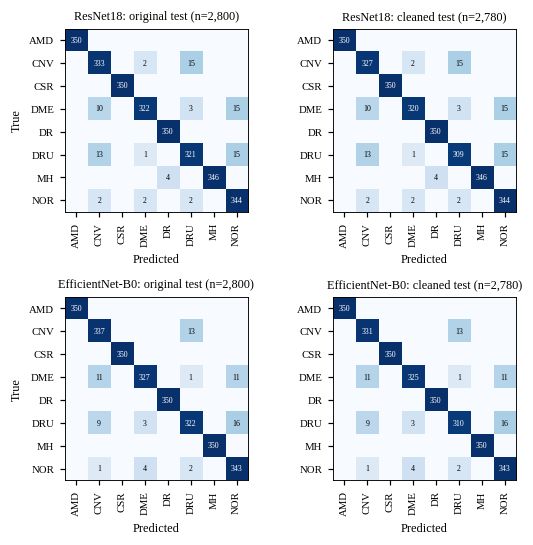

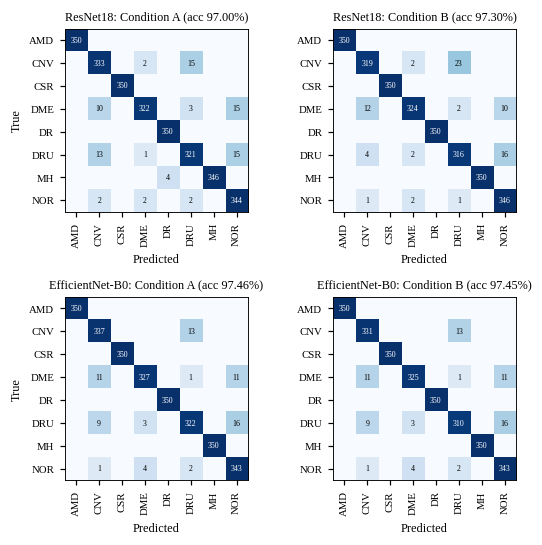

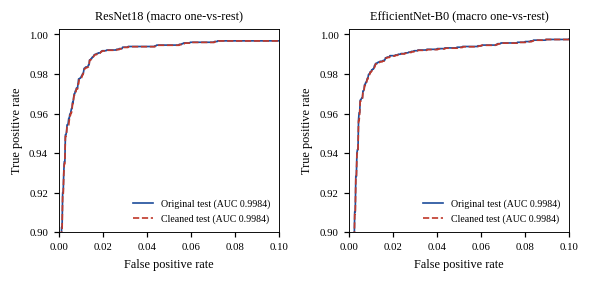

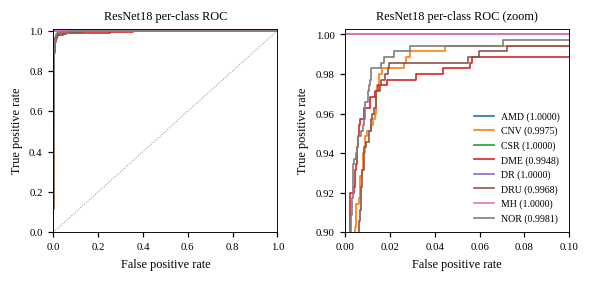

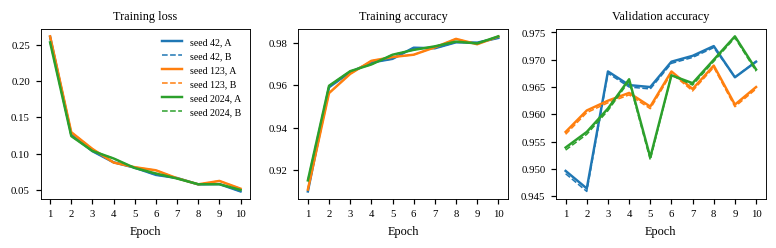

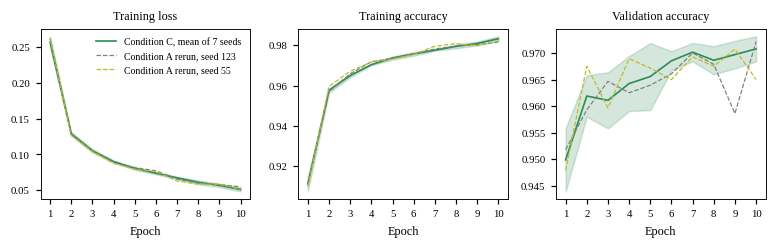

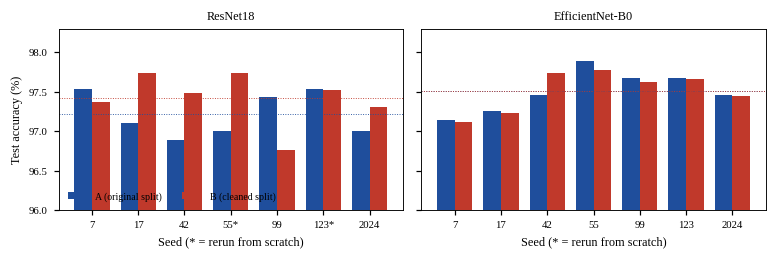

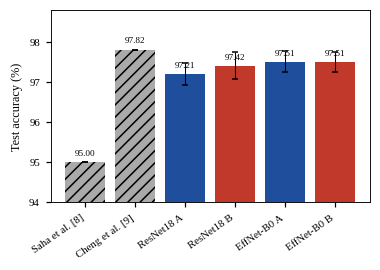

          model condition  n_seeds  acc_mean  acc_sd  macro_P  macro_R  macro_F1  macro_spec  macro_AUC
       ResNet18         A        7   97.2143  0.2766  97.2790  97.2143   97.2076     99.6020     0.9984
       ResNet18         B        7   97.4152  0.3313  97.4285  97.3843   97.3860     99.6311     0.9984
EfficientNet-B0         A        7   97.5102  0.2614  97.5501  97.5102   97.5085     99.6443     0.9987
EfficientNet-B0         B        7   97.5128  0.2539  97.5315  97.4861   97.4876     99.6451     0.9987


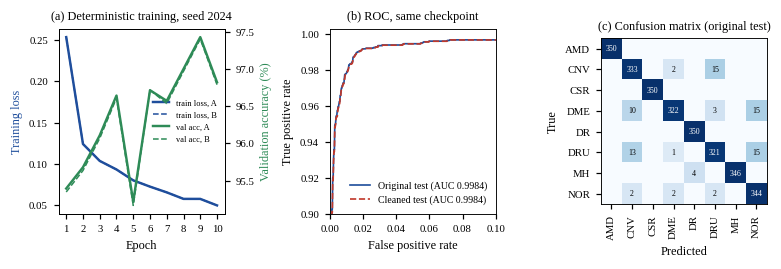

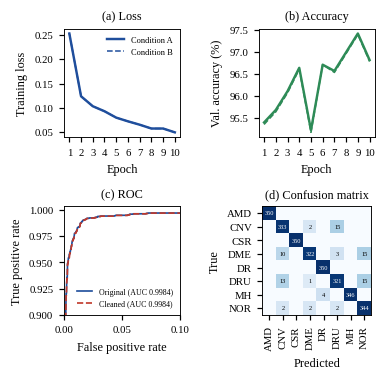


SUMMARY
OK      F1 confusion (fixed checkpoint)
OK      F1b confusion (retrained A/B)
OK      F2 ROC (fixed checkpoint)
OK      F2b ROC per class
OK      F3a curves E1
OK      F3b curves Condition C
OK      F4 per-seed accuracy
OK      F5 model comparison
OK      T performance table
OK      COMBINED 1x3 (full width)
OK      COMBINED 2x2 (single column)

Saved in: /content/drive/MyDrive/OCT_C8_Project/outputs/paper_figures_final
                                      file     size_in                                                                                                                        note
  F1_confusion_fixed_checkpoint.png / .pdf 5.20 x 5.00                                                                   same weights, original vs cleaned test set (paper method)
    F1b_confusion_retrained_A_B.png / .pdf 5.20 x 5.00                                                                                 retrained A vs B, seed 2024 (as old Fig. 4)
        F2_roc_fixed_checkpoin

In [ ]:
# =====================================================================
# Cell F — PAPER FIGURES (GPU lage na, ~2–4 min). Saved pkl theke shob figure + table banay.
# Kono model train hoy na. Drive mount hobe (popup e Allow dao). Output: outputs/paper_figures_final/ (PNG 300dpi + PDF vector)
# Kono figure fail korle baki gulo cholte thake; sheshe summary dekhabe.
# =====================================================================
import os, sys, pickle, warnings, traceback, itertools
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_fscore_support
from sklearn.preprocessing import label_binarize

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(PROJECT_DIR), "OCT_C8_Project folder paoa jayni"
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
REV_DIR = f'{PROJECT_DIR}/outputs/revision_runs'
FIG_DIR = f'{PROJECT_DIR}/outputs/paper_figures_final'
os.makedirs(FIG_DIR, exist_ok=True)

# ---------------- CONFIG ----------------
SEEDS = [42, 123, 2024, 7, 17, 55, 99]
FIXED_SEED = 2024                     # paper er Table III checkpoint (Condition A, seed 2024)
COMBINED_SOURCE = 'table3'            # 'table3' = ROC/confusion Table III er checkpoint theke; 'e1' = E1 deterministic seed-2024 A theke
SHOW_INLINE = True                    # Colab e figure dekhabe
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
SHORT = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRU', 'MH', 'NOR']
# Paper er cited reported accuracy (alada protocol; SOTA claim na). [8] er 95.0 ami verify kori ni — source theke ekbar dekhe nio.
PRIOR_WORK = [('Saha et al. [8]', 95.0), ('Cheng et al. [9]', 97.82)]

plt.rcParams.update({'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'legend.fontsize': 6.5,
                     'xtick.labelsize': 7, 'ytick.labelsize': 7, 'axes.linewidth': 0.6, 'lines.linewidth': 1.1,
                     'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
                     'mathtext.fontset': 'dejavuserif', 'figure.dpi': 110, 'axes.grid': False})
C_A, C_B, C_C = '#1f4e9c', '#c0392b', '#2e8b57'

# ---------------- data helpers ----------------
def load_pkl(p):
    if not os.path.exists(p):
        return None
    with open(p, 'rb') as f:
        return pickle.load(f)
def main_path(arch, letter, s):
    return (f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{s}.pkl' if arch == 'resnet18'
            else f'{EFFNET_DIR}/full_results_effnet_{letter}_seed{s}.pkl')
d1 = f'{REV_DIR}/E1_deterministic_resnet18'; d2 = f'{REV_DIR}/E2_rerun_interrupted'
def get_run(arch, letter, s):
    r2 = load_pkl(f'{d2}/full_results_{arch}_{letter}_seed{s}.pkl')       # E2 rerun hole oita (interrupted run replace)
    return (r2, True) if r2 is not None else (load_pkl(main_path(arch, letter, s)), False)
def correct_of(r):
    return np.asarray(r['preds']) == np.asarray(r['labels'])

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    _sp = pickle.load(f)
_testA = [p for p, _ in _sp['condA_test']]; _testB = set(p for p, _ in _sp['condB_test'])
removed_idx = [i for i, p in enumerate(_testA) if p not in _testB]
assert len(removed_idx) == 20, f"20 howar kotha, pelam {len(removed_idx)}"
keep = np.ones(len(_testA), bool); keep[removed_idx] = False

# ---------------- data audit ----------------
print('=' * 70 + '\nDATA AUDIT\n' + '=' * 70)
for arch in ['resnet18', 'effnet_b0']:
    n_ok = sum(get_run(arch, l, s)[0] is not None for l in 'AB' for s in SEEDS)
    n_probs = sum((get_run(arch, l, s)[0] or {}).get('probs') is not None for l in 'AB' for s in SEEDS)
    print(f'{arch}: {n_ok}/14 A/B run pkl | probs (ROC) in {n_probs}/14')
print('E1 epoch_log:', [s for s in (42, 123, 2024) if (load_pkl(f"{d1}/full_results_resnet18_A_seed{s}.pkl") or {}).get('epoch_log')],
      '| E3 (Condition C) epoch_log seeds:', [s for s in SEEDS if (load_pkl(f"{REV_DIR}/E3_condC_resnet18/full_results_resnet18_C_seed{s}.pkl") or {}).get('epoch_log')])

SAVED = []
def save(fig, stem, note=''):
    paths = []
    for ext in ('png', 'pdf'):
        p = f'{FIG_DIR}/{stem}.{ext}'
        fig.savefig(p, dpi=300, bbox_inches='tight', facecolor='white'); paths.append(p)
    w, h = fig.get_size_inches()
    SAVED.append(dict(file=f'{stem}.png / .pdf', size_in=f'{w:.2f} x {h:.2f}', note=note))
    if SHOW_INLINE:
        plt.show()
    plt.close(fig)

STATUS = []
def run_fig(name, fn):
    try:
        fn(); STATUS.append((name, 'OK'))
    except Exception as e:
        traceback.print_exc(); STATUS.append((name, f'FAILED: {type(e).__name__}: {e}'))

# ---------------- drawing helpers ----------------
def draw_cm(ax, y, p, title, ylabel=True, fs=5.2):
    cm = confusion_matrix(y, p, labels=list(range(8)))
    ax.imshow(cm, cmap='Blues', norm=PowerNorm(0.35, vmin=0, vmax=max(cm.max(), 1)))
    for i in range(8):
        for j in range(8):
            if cm[i, j] > 0:
                ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=fs, color='white' if cm[i, j] > 0.55 * cm.max() else 'black')
    ax.set_xticks(range(8)); ax.set_xticklabels(SHORT, rotation=90); ax.set_yticks(range(8)); ax.set_yticklabels(SHORT)
    ax.set_xlabel('Predicted')
    if ylabel:
        ax.set_ylabel('True')
    ax.set_title(title)

def roc_data(y, probs):
    Y = label_binarize(y, classes=list(range(8)))
    per, grid = [], np.linspace(0, 1, 4001)
    for c in range(8):
        f, t, _ = roc_curve(Y[:, c], probs[:, c]); per.append((f, t, auc(f, t)))
    mean_tpr = np.mean([np.interp(grid, f, t) for f, t, _ in per], axis=0)
    return grid, mean_tpr, float(np.mean([a for _, _, a in per])), per

def draw_roc(ax, curves, zoom=True, title=None):
    # curves = [(label, y, probs, color, linestyle)]  — macro (one-vs-rest) ROC
    for lab, y, pr, col, ls in curves:
        g, t, a, _ = roc_data(y, pr)
        ax.plot(g, t, color=col, ls=ls, label=f'{lab} (AUC {a:.4f})')
    if zoom:
        ax.set_xlim(0, 0.1); ax.set_ylim(0.9, 1.003)
    else:
        ax.plot([0, 1], [0, 1], color='gray', lw=0.6, ls=':'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.legend(loc='lower right', frameon=False)
    if title:
        ax.set_title(title)

def fixed_source(arch):
    if COMBINED_SOURCE == 'e1' and arch == 'resnet18':
        r = load_pkl(f'{d1}/full_results_resnet18_A_seed{FIXED_SEED}.pkl')
    else:
        r = load_pkl(main_path(arch, 'A', FIXED_SEED))
    return np.asarray(r['labels']), np.asarray(r['preds']), np.asarray(r['probs'])

def curve_xy(r, key):
    log = r['epoch_log']; return [e['epoch'] for e in log], [e[key] for e in log]

# =============== F1: confusion matrices, fixed checkpoint, original vs cleaned (both backbones) ===============
def fig_confusion_fixed():
    fig, axes = plt.subplots(2, 2, figsize=(5.2, 5.0))
    for r_i, (arch, nm) in enumerate([('resnet18', 'ResNet18'), ('effnet_b0', 'EfficientNet-B0')]):
        y, p, _ = fixed_source(arch)
        draw_cm(axes[r_i, 0], y, p, f'{nm}: original test (n=2,800)', ylabel=True)
        draw_cm(axes[r_i, 1], y[keep], p[keep], f'{nm}: cleaned test (n=2,780)', ylabel=False)
    fig.tight_layout(); save(fig, 'F1_confusion_fixed_checkpoint', 'same weights, original vs cleaned test set (paper method)')
run_fig('F1 confusion (fixed checkpoint)', fig_confusion_fixed)

# =============== F1b: confusion matrices, retrained A vs B (seed 2024) — old Fig. 4 ===============
def fig_confusion_retrained():
    fig, axes = plt.subplots(2, 2, figsize=(5.2, 5.0))
    for r_i, (arch, nm) in enumerate([('resnet18', 'ResNet18'), ('effnet_b0', 'EfficientNet-B0')]):
        for c_i, L in enumerate('AB'):
            r, _ = get_run(arch, L, FIXED_SEED)
            draw_cm(axes[r_i, c_i], np.asarray(r['labels']), np.asarray(r['preds']),
                    f'{nm}: Condition {L} (acc {correct_of(r).mean() * 100:.2f}%)', ylabel=(c_i == 0))
    fig.tight_layout(); save(fig, 'F1b_confusion_retrained_A_B', 'retrained A vs B, seed 2024 (as old Fig. 4)')
run_fig('F1b confusion (retrained A/B)', fig_confusion_retrained)

# =============== F2: ROC, fixed checkpoint, original vs cleaned (macro one-vs-rest, zoomed) ===============
def fig_roc_fixed():
    fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.6))
    for ax, (arch, nm) in zip(axes, [('resnet18', 'ResNet18'), ('effnet_b0', 'EfficientNet-B0')]):
        y, p, pr = fixed_source(arch)
        draw_roc(ax, [('Original test', y, pr, C_A, '-'), ('Cleaned test', y[keep], pr[keep], C_B, '--')], zoom=True, title=f'{nm} (macro one-vs-rest)')
    fig.tight_layout(); save(fig, 'F2_roc_fixed_checkpoint', 'macro ROC, zoomed to FPR<=0.1, TPR>=0.9; curves overlap by construction')
run_fig('F2 ROC (fixed checkpoint)', fig_roc_fixed)

def fig_roc_per_class():
    fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.6))
    y, p, pr = fixed_source('resnet18'); _, _, _, per = roc_data(y, pr)
    cols = plt.cm.tab10(np.linspace(0, 1, 10))
    for ax, zoom in zip(axes, [False, True]):
        for c, (f, t, a) in enumerate(per):
            ax.plot(f, t, color=cols[c], label=f'{SHORT[c]} ({a:.4f})')
        if zoom:
            ax.set_xlim(0, 0.1); ax.set_ylim(0.9, 1.003)
        else:
            ax.plot([0, 1], [0, 1], color='gray', lw=0.6, ls=':'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
        ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
        ax.set_title('ResNet18 per-class ROC' + (' (zoom)' if zoom else ''))
    axes[1].legend(loc='lower right', frameon=False, ncol=1)
    fig.tight_layout(); save(fig, 'F2b_roc_per_class_resnet18', 'per-class ROC, original test set')
run_fig('F2b ROC per class', fig_roc_per_class)

# =============== F3a: E1 deterministic curves, A vs B (loss, train acc, val acc) ===============
def fig_curves_e1():
    fig, axes = plt.subplots(1, 3, figsize=(7.1, 2.3)); cols = ['#1f77b4', '#ff7f0e', '#2ca02c']
    for k, s in enumerate((42, 123, 2024)):
        for L, ls, lw in (('A', '-', 1.6), ('B', '--', 1.0)):
            r = load_pkl(f'{d1}/full_results_resnet18_{L}_seed{s}.pkl')
            if r is None or not r.get('epoch_log'):
                continue
            for ax, key in zip(axes, ['loss', 'train_acc', 'val_acc']):
                x, yv = curve_xy(r, key); ax.plot(x, yv, color=cols[k], ls=ls, lw=lw, label=f'seed {s}, {L}')
    for ax, t in zip(axes, ['Training loss', 'Training accuracy', 'Validation accuracy']):
        ax.set_title(t); ax.set_xlabel('Epoch'); ax.set_xticks(range(1, 11))
    axes[0].legend(frameon=False, ncol=1)
    fig.tight_layout(); save(fig, 'F3a_curves_deterministic_A_vs_B', 'deterministic ResNet18; A (solid) and B (dashed) trajectories coincide; val sets differ (2,800 vs 2,772)')
run_fig('F3a curves E1', fig_curves_e1)

# =============== F3b: Condition C curves (mean +- SD, 7 seeds) + E2 reruns ===============
def fig_curves_c():
    fig, axes = plt.subplots(1, 3, figsize=(7.1, 2.3))
    logs = [load_pkl(f'{REV_DIR}/E3_condC_resnet18/full_results_resnet18_C_seed{s}.pkl') for s in SEEDS]
    logs = [r for r in logs if r is not None and r.get('epoch_log')]
    assert logs, 'E3 epoch_log nei'
    for ax, key, t in zip(axes, ['loss', 'train_acc', 'val_acc'], ['Training loss', 'Training accuracy', 'Validation accuracy']):
        M = np.array([[e[key] for e in r['epoch_log']] for r in logs]); x = np.arange(1, M.shape[1] + 1)
        ax.plot(x, M.mean(0), color=C_C, label=f'Condition C, mean of {len(logs)} seeds'); ax.fill_between(x, M.mean(0) - M.std(0, ddof=1), M.mean(0) + M.std(0, ddof=1), color=C_C, alpha=0.2)
        for s, col in ((123, '#7f7f7f'), (55, '#bcbd22')):
            r2 = load_pkl(f'{d2}/full_results_resnet18_A_seed{s}.pkl')
            if r2 is not None and r2.get('epoch_log'):
                xx, yy = curve_xy(r2, key); ax.plot(xx, yy, color=col, lw=0.8, ls='--', label=f'Condition A rerun, seed {s}')
        ax.set_title(t); ax.set_xlabel('Epoch'); ax.set_xticks(range(1, 11))
    axes[0].legend(frameon=False)
    fig.tight_layout(); save(fig, 'F3b_curves_condition_C', 'Condition C (training copies removed) mean +- SD, with the two E2 Condition-A reruns')
run_fig('F3b curves Condition C', fig_curves_c)

# =============== F4: per-seed accuracy, A vs B (clean) ===============
CLEAN = {}
for arch in ['resnet18', 'effnet_b0']:
    rows = []
    for s in sorted(SEEDS):
        ra, sa = get_run(arch, 'A', s); rb, sb = get_run(arch, 'B', s)
        if ra is not None and rb is not None:
            rows.append((s, sa, correct_of(ra).mean() * 100, correct_of(rb).mean() * 100, ra, rb))
    CLEAN[arch] = rows

def fig_per_seed():
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 2.4), sharey=True)
    for ax, (arch, nm) in zip(axes, [('resnet18', 'ResNet18'), ('effnet_b0', 'EfficientNet-B0')]):
        rows = CLEAN[arch]; x = np.arange(len(rows)); w = 0.38
        ax.bar(x - w / 2, [r[2] for r in rows], w, color=C_A, label='A (original split)')
        ax.bar(x + w / 2, [r[3] for r in rows], w, color=C_B, label='B (cleaned split)')
        ax.set_xticks(x); ax.set_xticklabels([f'{r[0]}{"*" if r[1] else ""}' for r in rows]); ax.set_xlabel('Seed (* = rerun from scratch)')
        ax.set_ylim(96.0, 98.3); ax.set_title(nm); ax.axhline(np.mean([r[2] for r in rows]), color=C_A, lw=0.6, ls=':'); ax.axhline(np.mean([r[3] for r in rows]), color=C_B, lw=0.6, ls=':')
    axes[0].set_ylabel('Test accuracy (%)'); axes[0].legend(frameon=False, loc='lower left', ncol=2)
    fig.tight_layout(); save(fig, 'F4_accuracy_per_seed_A_vs_B', 'per-seed test accuracy; dotted = condition mean; y-axis truncated at 96%')
run_fig('F4 per-seed accuracy', fig_per_seed)

# =============== F5: model comparison (backbones + reported prior work) ===============
def fig_model_comparison():
    fig, ax = plt.subplots(figsize=(3.5, 2.5)); labels, vals, errs, cols, hatch = [], [], [], [], []
    for name, v in PRIOR_WORK:
        labels.append(name); vals.append(v); errs.append(0); cols.append('#aaaaaa'); hatch.append('///')
    for arch, nm in [('resnet18', 'ResNet18'), ('effnet_b0', 'EffNet-B0')]:
        for k, L in ((2, 'A'), (3, 'B')):
            v = np.array([r[k] for r in CLEAN[arch]]); labels.append(f'{nm} {L}'); vals.append(v.mean()); errs.append(v.std(ddof=1))
            cols.append(C_A if L == 'A' else C_B); hatch.append('')
    x = np.arange(len(vals)); bars = ax.bar(x, vals, yerr=errs, color=cols, capsize=2, error_kw={'lw': 0.7})
    for b, h in zip(bars, hatch):
        b.set_hatch(h)
    for xi, v in zip(x, vals):
        ax.text(xi, v + 0.12, f'{v:.2f}', ha='center', va='bottom', fontsize=6)
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=35, ha='right'); ax.set_ylim(94, 98.8); ax.set_ylabel('Test accuracy (%)')
    fig.tight_layout(); save(fig, 'F5_model_comparison', 'hatched = accuracy reported by cited papers (different protocols; context only, not a SOTA claim); ours = 7-seed mean +- SD')
run_fig('F5 model comparison', fig_model_comparison)

# =============== T: performance table (accuracy + macro P/R/F1/specificity/AUC) ===============
def metrics_of(r):
    y, p = np.asarray(r['labels']), np.asarray(r['preds'])
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=list(range(8)), zero_division=0)
    cm = confusion_matrix(y, p, labels=list(range(8)))
    tn = cm.sum() - cm.sum(0) - cm.sum(1) + np.diag(cm); fp = cm.sum(0) - np.diag(cm); spec = tn / np.maximum(tn + fp, 1)
    a = np.nan
    if r.get('probs') is not None:
        a = roc_data(y, np.asarray(r['probs']))[2]
    return dict(acc=(y == p).mean() * 100, P=pr.mean() * 100, R=rc.mean() * 100, F1=f1.mean() * 100, Spec=spec.mean() * 100, AUC=a,
                per_P=pr * 100, per_R=rc * 100, per_F1=f1 * 100)

def table_performance():
    rows, tex = [], []
    for arch, nm in [('resnet18', 'ResNet18'), ('effnet_b0', 'EfficientNet-B0')]:
        for k, L in ((4, 'A'), (5, 'B')):
            M = [metrics_of(r[k]) for r in CLEAN[arch]]
            g = lambda key: np.array([m[key] for m in M])
            rows.append(dict(model=nm, condition=L, n_seeds=len(M), acc_mean=g('acc').mean(), acc_sd=g('acc').std(ddof=1), macro_P=g('P').mean(), macro_R=g('R').mean(),
                             macro_F1=g('F1').mean(), macro_spec=g('Spec').mean(), macro_AUC=np.nanmean(g('AUC'))))
    df = pd.DataFrame(rows); df.to_csv(f'{FIG_DIR}/T_performance_table.csv', index=False)
    print(df.round(4).to_string(index=False))
    tex.append('% Table: classification performance (7-seed means; accuracy mean +- SD). Prior-work rows: accuracy as reported, protocols differ.')
    tex.append('\\begin{tabular}{llcccccc}\n\\hline\nModel & Cond. & Acc. (\\%) & Prec. & Rec. & F1 & Spec. & AUC \\\\\n\\hline')
    for name, v in PRIOR_WORK:
        tex.append(f'{name} & -- & {v:.2f} & -- & -- & -- & -- & -- \\\\')
    for r in rows:
        tex.append(f"{r['model']} & {r['condition']} & {r['acc_mean']:.2f} $\\pm$ {r['acc_sd']:.2f} & {r['macro_P']:.2f} & {r['macro_R']:.2f} & {r['macro_F1']:.2f} & {r['macro_spec']:.2f} & {r['macro_AUC']:.4f} \\\\")
    tex.append('\\hline\n\\end{tabular}')
    open(f'{FIG_DIR}/T_performance_table.tex', 'w').write('\n'.join(tex))
    # per-class (ResNet18) table
    M_A = [metrics_of(r[4]) for r in CLEAN['resnet18']]; M_B = [metrics_of(r[5]) for r in CLEAN['resnet18']]
    pc = pd.DataFrame({'class': CLASS_NAMES,
                       'A_P': np.mean([m['per_P'] for m in M_A], 0), 'A_R': np.mean([m['per_R'] for m in M_A], 0), 'A_R_sd': np.std([m['per_R'] for m in M_A], 0, ddof=1), 'A_F1': np.mean([m['per_F1'] for m in M_A], 0),
                       'B_P': np.mean([m['per_P'] for m in M_B], 0), 'B_R': np.mean([m['per_R'] for m in M_B], 0), 'B_R_sd': np.std([m['per_R'] for m in M_B], 0, ddof=1), 'B_F1': np.mean([m['per_F1'] for m in M_B], 0)})
    pc.to_csv(f'{FIG_DIR}/T_per_class_resnet18.csv', index=False)
    SAVED.append(dict(file='T_performance_table.csv / .tex', size_in='table', note='accuracy + macro P/R/F1/spec/AUC (A,B; both backbones) + prior-work rows'))
    SAVED.append(dict(file='T_per_class_resnet18.csv', size_in='table', note='per-class P/R/F1, 7-seed means'))
run_fig('T performance table', table_performance)

# =============== COMBINED figures (paper er jonno) ===============
def panel_curves(ax_loss, ax_acc=None, seed=FIXED_SEED):
    for L, ls, lw in (('A', '-', 1.6), ('B', '--', 1.0)):
        r = load_pkl(f'{d1}/full_results_resnet18_{L}_seed{seed}.pkl')
        if r is None or not r.get('epoch_log'):
            raise RuntimeError('E1 epoch_log nei')
        x, lo = curve_xy(r, 'loss'); _, va = curve_xy(r, 'val_acc')
        if ax_acc is None:                         # twin-axis version
            ax_loss.plot(x, lo, color=C_A, ls=ls, lw=lw, label=f'train loss, {L}')
            tw = ax_loss.twinx() if L == 'A' else tw
            tw.plot(x, [v * 100 for v in va], color=C_C, ls=ls, lw=lw, label=f'val acc, {L}')
        else:
            ax_loss.plot(x, lo, color=C_A, ls=ls, lw=lw, label=f'Condition {L}'); ax_acc.plot(x, [v * 100 for v in va], color=C_C, ls=ls, lw=lw, label=f'Condition {L}')
    ax_loss.set_xlabel('Epoch'); ax_loss.set_xticks(range(1, 11))
    return None if ax_acc is not None else tw

def fig_combined_3():
    fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.45), gridspec_kw=dict(width_ratios=[1, 1, 1.0]))
    tw = panel_curves(axes[0])
    axes[0].set_ylabel('Training loss', color=C_A); tw.set_ylabel('Validation accuracy (%)', color=C_C)
    axes[0].set_title('(a) Deterministic training, seed %d' % FIXED_SEED)
    h1, l1 = axes[0].get_legend_handles_labels(); h2, l2 = tw.get_legend_handles_labels(); axes[0].legend(h1 + h2, l1 + l2, frameon=False, fontsize=5.5, loc='center right')
    y, p, pr = fixed_source('resnet18')
    draw_roc(axes[1], [('Original test', y, pr, C_A, '-'), ('Cleaned test', y[keep], pr[keep], C_B, '--')], zoom=True); axes[1].set_title('(b) ROC, same checkpoint')
    draw_cm(axes[2], y, p, '(c) Confusion matrix (original test)', ylabel=True)
    fig.tight_layout(w_pad=0.8); save(fig, 'COMBINED_3panel_fullwidth', 'paper: figure* (full width). (a) E1 deterministic A vs B; (b),(c) fixed checkpoint (COMBINED_SOURCE)')
run_fig('COMBINED 1x3 (full width)', fig_combined_3)

def fig_combined_4():
    fig, axes = plt.subplots(2, 2, figsize=(3.5, 3.5))
    panel_curves(axes[0, 0], axes[0, 1])
    axes[0, 0].set_ylabel('Training loss'); axes[0, 0].set_title('(a) Loss'); axes[0, 1].set_ylabel('Val. accuracy (%)'); axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_xticks(range(1, 11)); axes[0, 1].set_title('(b) Accuracy')
    axes[0, 0].legend(frameon=False, fontsize=5.5)
    y, p, pr = fixed_source('resnet18')
    draw_roc(axes[1, 0], [('Original', y, pr, C_A, '-'), ('Cleaned', y[keep], pr[keep], C_B, '--')], zoom=True); axes[1, 0].set_title('(c) ROC'); axes[1, 0].legend(frameon=False, fontsize=5.2, loc='lower right')
    draw_cm(axes[1, 1], y, p, '(d) Confusion matrix', ylabel=True, fs=4.2)
    fig.tight_layout(); save(fig, 'COMBINED_4panel_singlecolumn', 'paper: single column 2x2 (a) loss (b) val acc, A vs B deterministic; (c) ROC; (d) confusion matrix')
run_fig('COMBINED 2x2 (single column)', fig_combined_4)

# ---------------- summary ----------------
pd.DataFrame(SAVED).to_csv(f'{FIG_DIR}/figures_manifest.csv', index=False)
print('\n' + '=' * 70 + '\nSUMMARY\n' + '=' * 70)
for n, s in STATUS:
    print(f'{s:60s} <- {n}' if s != 'OK' else f'OK      {n}')
print('\nSaved in:', FIG_DIR)
print(pd.DataFrame(SAVED).to_string(index=False))
print('\nEi list ar combined figure dekhe amake bolo kon gulo paper e jabe.')

Mounted at /content/drive
saved Fig1_pipeline_compact 3.50 x 2.05 in


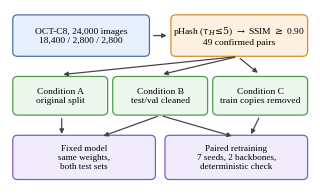

confirmed pairs: 49 | byte-identical: 46 | not identical: 3
saved Fig2_near_duplicate_pairs 3.50 x 1.90 in


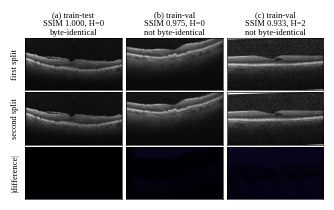


Sesh. Fig1_pipeline_compact ar Fig2_near_duplicate_pairs (PNG+PDF) ar fig2_pairs_used.csv amake pathao / check koro.


In [1]:
# =====================================================================
# Cell G — Fig. 1 (compact flowchart) + Fig. 2 (near-duplicate pairs). GPU/training lage na, ~1 min.
# Fig.1 : single-column (3.5 in) compact pipeline — purono 280 pt boro flowchart er jaygay ~140 pt.
# Fig.2 : col (a) = test-side byte-identical pair (jeta asholei result-ke prabhabito kore),
#         col (b),(c) = pHash+SSIM er dhorsha NON-identical pair (exact hash miss korto) + |difference| map.
# Output: outputs/paper_figures_final/Fig1_pipeline_compact.{png,pdf}, Fig2_near_duplicate_pairs.{png,pdf}, fig2_pairs_used.csv
# =====================================================================
import os, hashlib, warnings, traceback
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from PIL import Image

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(PROJECT_DIR), "OCT_C8_Project folder paoa jayni"
FIG_DIR = f'{PROJECT_DIR}/outputs/paper_figures_final'
os.makedirs(FIG_DIR, exist_ok=True)
SHOW_INLINE = True
plt.rcParams.update({'font.size': 7, 'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'], 'figure.dpi': 110, 'mathtext.fontset': 'dejavuserif'})

def save(fig, stem):
    for ext in ('png', 'pdf'):
        fig.savefig(f'{FIG_DIR}/{stem}.{ext}', dpi=300, bbox_inches='tight', facecolor='white')
    print('saved', stem, f'{fig.get_size_inches()[0]:.2f} x {fig.get_size_inches()[1]:.2f} in')
    if SHOW_INLINE:
        plt.show()
    plt.close(fig)

# ======================= Fig. 1: compact pipeline =======================
def fig1():
    fig, ax = plt.subplots(figsize=(3.5, 2.05)); ax.set_xlim(0, 100); ax.set_ylim(0, 62); ax.axis('off')
    def box(x0, y0, x1, y1, text, fc, ec, fs=6.2, bold=False):
        ax.add_patch(FancyBboxPatch((x0, y0), x1 - x0, y1 - y0, boxstyle='round,pad=0.4,rounding_size=1.6', fc=fc, ec=ec, lw=0.8))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, text, ha='center', va='center', fontsize=fs, fontweight='bold' if bold else 'normal', linespacing=1.15)
    def arrow(p, q):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=6, lw=0.8, color='#444444'))
    box(1, 46, 46, 60, 'OCT-C8, 24,000 images\n18,400 / 2,800 / 2,800', '#e8f0fe', '#4a6fa5')
    box(54, 46, 99, 60, 'pHash ($\\tau_H\\!\\leq\\!5$) $\\rightarrow$ SSIM $\\geq$ 0.90\n49 confirmed pairs', '#fff1e0', '#d98c2b')
    arrow((46.8, 53), (53.2, 53))
    box(1, 25, 32, 38, 'Condition A\noriginal split', '#eef7ee', '#4c9a4c')
    box(34.5, 25, 65.5, 38, 'Condition B\ntest/val cleaned', '#eef7ee', '#4c9a4c')
    box(68, 25, 99, 38, 'Condition C\ntrain copies removed', '#eef7ee', '#4c9a4c')
    arrow((76, 45.5), (50, 39)); arrow((76, 45.5), (83.5, 39)); arrow((76, 45.5), (16.5, 39))
    box(1, 2, 48, 17, 'Fixed model\nsame weights,\nboth test sets', '#f1ecfb', '#7a5cc2', fs=6.0)
    box(52, 2, 99, 17, 'Paired retraining\n7 seeds, 2 backbones,\ndeterministic check', '#f1ecfb', '#7a5cc2', fs=6.0)
    arrow((17, 24.5), (17, 16.8)); arrow((50, 24.5), (30, 16.8)); arrow((50, 24.5), (75, 16.8)); arrow((83.5, 24.5), (80, 16.8))
    save(fig, 'Fig1_pipeline_compact')
try:
    fig1()
except Exception:
    traceback.print_exc()

# ======================= Fig. 2: pairs =======================
def sha(p):
    with open(p, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()
def confirmed(df):
    return df[df['confirmed_duplicate'] == True] if 'confirmed_duplicate' in df.columns else df[df['ssim_score'] >= 0.90]

def fig2():
    rows = []
    for fn, a, b, nm in [('leaks_train_val_verified.csv', 'train_path', 'val_path', 'train-val'),
                         ('leaks_train_test_verified.csv', 'train_path', 'test_path', 'train-test'),
                         ('leaks_val_test_verified.csv', 'val_path', 'test_path', 'val-test')]:
        df = confirmed(pd.read_csv(f'{PROJECT_DIR}/outputs/{fn}'))
        for _, r in df.iterrows():
            rows.append(dict(split_pair=nm, path_a=r[a], path_b=r[b], cls=r.get('class', ''), hamming=r['hamming_distance'], ssim=r['ssim_score'], same_bytes=(sha(r[a]) == sha(r[b]))))
    P = pd.DataFrame(rows)
    print('confirmed pairs:', len(P), '| byte-identical:', int(P.same_bytes.sum()), '| not identical:', int((~P.same_bytes).sum()))
    nonexact = P[~P.same_bytes].sort_values('ssim', ascending=False)
    test_exact = P[(P.same_bytes) & (P.split_pair.isin(['train-test', 'val-test']))].sort_values(['cls', 'path_a'])
    drusen = test_exact[test_exact.cls.astype(str).str.upper() == 'DRUSEN']
    pick = [(drusen if len(drusen) else test_exact).iloc[0]]                                   # (a) test-side exact copy
    if len(nonexact) >= 2:
        pick += [nonexact.iloc[0], nonexact.iloc[-1]]                                          # (b) highest SSIM, (c) lowest SSIM non-identical
    else:
        pick += [nonexact.iloc[i] for i in range(len(nonexact))]
    pd.DataFrame(pick).to_csv(f'{FIG_DIR}/fig2_pairs_used.csv', index=False)
    fig, axes = plt.subplots(3, len(pick), figsize=(3.5, 1.9), squeeze=False)
    for j, r in enumerate(pick):
        A = np.asarray(Image.open(r.path_a).convert('L'), float); B_img = Image.open(r.path_b).convert('L')
        B = np.asarray(B_img.resize((A.shape[1], A.shape[0])), float) if B_img.size != (A.shape[1], A.shape[0]) else np.asarray(B_img, float)
        D = np.abs(A - B) / 255.0
        for i, (img, kw) in enumerate([(A, dict(cmap='gray')), (B, dict(cmap='gray')), (D, dict(cmap='magma', vmin=0, vmax=0.4))]):
            ax = axes[i, j]; ax.imshow(img, aspect='auto', **kw); ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_linewidth(0.4)
        tag = 'byte-identical' if r.same_bytes else 'not byte-identical'
        axes[0, j].set_title(f"({'abc'[j]}) {r.split_pair}\nSSIM {r.ssim:.3f}, H={int(r.hamming)}\n{tag}", fontsize=5.6, pad=2)
    axes[0, 0].set_ylabel('first split', fontsize=5.6); axes[1, 0].set_ylabel('second split', fontsize=5.6); axes[2, 0].set_ylabel('|difference|', fontsize=5.6)
    fig.subplots_adjust(wspace=0.04, hspace=0.04)
    save(fig, 'Fig2_near_duplicate_pairs')
try:
    fig2()
except Exception:
    traceback.print_exc()
print('\nSesh. Fig1_pipeline_compact ar Fig2_near_duplicate_pairs (PNG+PDF) ar fig2_pairs_used.csv amake pathao / check koro.')

saved Fig1_pipeline_compact 3.50 x 2.05 in


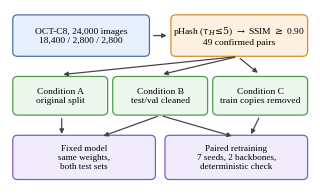

confirmed pairs: 49 | byte-identical: 46 | not identical: 3
saved Fig2_near_duplicate_pairs 3.50 x 1.90 in


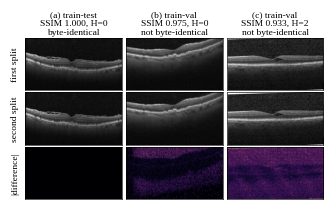


Sesh. Fig1_pipeline_compact ar Fig2_near_duplicate_pairs (PNG+PDF) ar fig2_pairs_used.csv amake pathao / check koro.


In [2]:
# =====================================================================
# Cell G — Fig. 1 (compact flowchart) + Fig. 2 (near-duplicate pairs). GPU/training lage na, ~1 min.
# Fig.1 : single-column (3.5 in) compact pipeline — purono 280 pt boro flowchart er jaygay ~140 pt.
# Fig.2 : col (a) = test-side byte-identical pair (jeta asholei result-ke prabhabito kore),
#         col (b),(c) = pHash+SSIM er dhorsha NON-identical pair (exact hash miss korto) + |difference| map.
# Output: outputs/paper_figures_final/Fig1_pipeline_compact.{png,pdf}, Fig2_near_duplicate_pairs.{png,pdf}, fig2_pairs_used.csv
# =====================================================================
import os, hashlib, warnings, traceback
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from PIL import Image

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
if not os.path.isdir(PROJECT_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.isdir(PROJECT_DIR), "OCT_C8_Project folder paoa jayni"
FIG_DIR = f'{PROJECT_DIR}/outputs/paper_figures_final'
os.makedirs(FIG_DIR, exist_ok=True)
SHOW_INLINE = True
DIFF_VMAX = 0.08          # |difference| colour scale (0..0.08 of full intensity range) — (b),(c) er chhoto parthokko dekhanor jonno
plt.rcParams.update({'font.size': 7, 'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'], 'figure.dpi': 110, 'mathtext.fontset': 'dejavuserif'})

def save(fig, stem):
    for ext in ('png', 'pdf'):
        fig.savefig(f'{FIG_DIR}/{stem}.{ext}', dpi=300, bbox_inches='tight', facecolor='white')
    print('saved', stem, f'{fig.get_size_inches()[0]:.2f} x {fig.get_size_inches()[1]:.2f} in')
    if SHOW_INLINE:
        plt.show()
    plt.close(fig)

# ======================= Fig. 1: compact pipeline =======================
def fig1():
    fig, ax = plt.subplots(figsize=(3.5, 2.05)); ax.set_xlim(0, 100); ax.set_ylim(0, 62); ax.axis('off')
    def box(x0, y0, x1, y1, text, fc, ec, fs=6.2, bold=False):
        ax.add_patch(FancyBboxPatch((x0, y0), x1 - x0, y1 - y0, boxstyle='round,pad=0.4,rounding_size=1.6', fc=fc, ec=ec, lw=0.8))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, text, ha='center', va='center', fontsize=fs, fontweight='bold' if bold else 'normal', linespacing=1.15)
    def arrow(p, q):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=6, lw=0.8, color='#444444'))
    box(1, 46, 46, 60, 'OCT-C8, 24,000 images\n18,400 / 2,800 / 2,800', '#e8f0fe', '#4a6fa5')
    box(54, 46, 99, 60, 'pHash ($\\tau_H\\!\\leq\\!5$) $\\rightarrow$ SSIM $\\geq$ 0.90\n49 confirmed pairs', '#fff1e0', '#d98c2b')
    arrow((46.8, 53), (53.2, 53))
    box(1, 25, 32, 38, 'Condition A\noriginal split', '#eef7ee', '#4c9a4c')
    box(34.5, 25, 65.5, 38, 'Condition B\ntest/val cleaned', '#eef7ee', '#4c9a4c')
    box(68, 25, 99, 38, 'Condition C\ntrain copies removed', '#eef7ee', '#4c9a4c')
    arrow((76, 45.5), (50, 39)); arrow((76, 45.5), (83.5, 39)); arrow((76, 45.5), (16.5, 39))
    box(1, 2, 48, 17, 'Fixed model\nsame weights,\nboth test sets', '#f1ecfb', '#7a5cc2', fs=6.0)
    box(52, 2, 99, 17, 'Paired retraining\n7 seeds, 2 backbones,\ndeterministic check', '#f1ecfb', '#7a5cc2', fs=6.0)
    arrow((17, 24.5), (17, 16.8)); arrow((50, 24.5), (30, 16.8)); arrow((50, 24.5), (75, 16.8)); arrow((83.5, 24.5), (80, 16.8))
    save(fig, 'Fig1_pipeline_compact')
try:
    fig1()
except Exception:
    traceback.print_exc()

# ======================= Fig. 2: pairs =======================
def sha(p):
    with open(p, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()
def confirmed(df):
    return df[df['confirmed_duplicate'] == True] if 'confirmed_duplicate' in df.columns else df[df['ssim_score'] >= 0.90]

def fig2():
    rows = []
    for fn, a, b, nm in [('leaks_train_val_verified.csv', 'train_path', 'val_path', 'train-val'),
                         ('leaks_train_test_verified.csv', 'train_path', 'test_path', 'train-test'),
                         ('leaks_val_test_verified.csv', 'val_path', 'test_path', 'val-test')]:
        df = confirmed(pd.read_csv(f'{PROJECT_DIR}/outputs/{fn}'))
        for _, r in df.iterrows():
            rows.append(dict(split_pair=nm, path_a=r[a], path_b=r[b], cls=r.get('class', ''), hamming=r['hamming_distance'], ssim=r['ssim_score'], same_bytes=(sha(r[a]) == sha(r[b]))))
    P = pd.DataFrame(rows)
    print('confirmed pairs:', len(P), '| byte-identical:', int(P.same_bytes.sum()), '| not identical:', int((~P.same_bytes).sum()))
    nonexact = P[~P.same_bytes].sort_values('ssim', ascending=False)
    test_exact = P[(P.same_bytes) & (P.split_pair.isin(['train-test', 'val-test']))].sort_values(['cls', 'path_a'])
    drusen = test_exact[test_exact.cls.astype(str).str.upper() == 'DRUSEN']
    pick = [(drusen if len(drusen) else test_exact).iloc[0]]                                   # (a) test-side exact copy
    if len(nonexact) >= 2:
        pick += [nonexact.iloc[0], nonexact.iloc[-1]]                                          # (b) highest SSIM, (c) lowest SSIM non-identical
    else:
        pick += [nonexact.iloc[i] for i in range(len(nonexact))]
    pd.DataFrame(pick).to_csv(f'{FIG_DIR}/fig2_pairs_used.csv', index=False)
    fig, axes = plt.subplots(3, len(pick), figsize=(3.5, 1.9), squeeze=False)
    for j, r in enumerate(pick):
        A = np.asarray(Image.open(r.path_a).convert('L'), float); B_img = Image.open(r.path_b).convert('L')
        B = np.asarray(B_img.resize((A.shape[1], A.shape[0])), float) if B_img.size != (A.shape[1], A.shape[0]) else np.asarray(B_img, float)
        D = np.abs(A - B) / 255.0
        for i, (img, kw) in enumerate([(A, dict(cmap='gray')), (B, dict(cmap='gray')), (D, dict(cmap='magma', vmin=0, vmax=DIFF_VMAX))]):
            ax = axes[i, j]; ax.imshow(img, aspect='auto', **kw); ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_linewidth(0.4)
        tag = 'byte-identical' if r.same_bytes else 'not byte-identical'
        axes[0, j].set_title(f"({'abc'[j]}) {r.split_pair}\nSSIM {r.ssim:.3f}, H={int(r.hamming)}\n{tag}", fontsize=6.2, pad=2)
    axes[0, 0].set_ylabel('first split', fontsize=6.2); axes[1, 0].set_ylabel('second split', fontsize=6.2); axes[2, 0].set_ylabel('|difference|', fontsize=6.2)
    fig.subplots_adjust(wspace=0.04, hspace=0.04)
    save(fig, 'Fig2_near_duplicate_pairs')
try:
    fig2()
except Exception:
    traceback.print_exc()
print('\nSesh. Fig1_pipeline_compact ar Fig2_near_duplicate_pairs (PNG+PDF) ar fig2_pairs_used.csv amake pathao / check koro.')